---
# Group 8 — Final Machine Learning Notebook


---
# 01 — Exploratory Data Analysis


In [22]:

# ==========================================================
# Cell 1 — Project Root Setup
# Run this FIRST after restarting the Jupyter kernel
# ==========================================================

from pathlib import Path
import os
import sys

current = Path.cwd().resolve()

# Search the current folder and its parent folders
candidates = [current, *current.parents]

project_root = next(
    (
        folder
        for folder in candidates
        if (folder / "src" / "preprocessing.py").is_file()
        and (folder / "data" / "raw" / "credit_default.csv").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find project root. Make sure the repository "
        "contains src/preprocessing.py and "
        "data/raw/credit_default.csv."
    )

# Make src importable
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Ensure output paths save to the correct repository
os.chdir(project_root)

print("Project root:", project_root)
print("Current working directory:", Path.cwd())
print("Shared preprocessing found:",
      (project_root / "src" / "preprocessing.py").exists())


Project root: C:\Users\Vivian\OneDrive\Documents\A 6001CMD Machine learning\ML Group
Current working directory: C:\Users\Vivian\OneDrive\Documents\A 6001CMD Machine learning\ML Group
Shared preprocessing found: True


In [23]:

# ==========================================================
# Cell 2 — Shared Dataset Setup
# ==========================================================

import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import load_data, split_data

df = load_data()

X_train, X_test, y_train, y_test = split_data(df)

print("Full dataset:", df.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)

assert df.shape == (30000, 25)
assert X_train.shape == (24000, 23)
assert X_test.shape == (6000, 23)

assert "ID" not in X_train.columns
assert "PAY_0" in X_train.columns

print("Shared preprocessing contract verified!")


Full dataset: (30000, 25)
Training features: (24000, 23)
Testing features: (6000, 23)
Training target: (24000,)
Shared preprocessing contract verified!


## 2. Dataset Loading and Shared Train/Test Split

**Objective:** To load the Credit Card Default dataset and apply the shared stratified 80/20 train/test split provided by M2.

**Evidence:** Dataset and split dimensions.

**Report Section:** Chapter 2.1 and Chapter 3.2.

In [3]:
import os
import sys
from pathlib import Path

print("Current folder:", Path.cwd())

# Find the project root containing src/preprocessing.py
project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src" / "preprocessing.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Cannot find src/preprocessing.py. "
        "Please check your VS Code project folder."
    )

sys.path.insert(0, str(project_root))
os.chdir(project_root)

print("Project root:", project_root)
print("Ready!")

Current folder: c:\Users\Vivian\OneDrive\Documents\A 6001CMD Machine learning\ML Group\notebooks
Project root: c:\Users\Vivian\OneDrive\Documents\A 6001CMD Machine learning\ML Group
Ready!


In [4]:
from src.preprocessing import load_data, split_data

df = load_data()

X_train, X_test, y_train, y_test = split_data(df)

print("Full dataset:", df.shape)
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

display(X_train.describe().T)

Full dataset: (30000, 25)
Training data: (24000, 23)
Test data: (6000, 23)


,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167364.666667,129511.313151,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.604750,0.488915,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.853792,0.792375,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.552875,0.521903,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.432625,9.195256,21.0,28.00,34.0,41.00,75.0
PAY_0,24000.0,-0.014125,1.123155,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.134083,1.198818,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.166917,1.194166,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.221333,1.161924,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.270333,1.125192,-2.0,-1.00,0.0,0.00,8.0


Descriptive Statistics

**Objective:** To summarise the distribution and variability of numerical features in the training dataset.

**Output:** `results/eda_descriptive_statistics.csv`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Descriptive statistics for training features
stats = X_train.describe().T

display(stats)

# Save evidence
from pathlib import Path

Path("results").mkdir(exist_ok=True)
stats.to_csv("results/eda_descriptive_statistics.csv")

print("Saved: results/eda_descriptive_statistics.csv")

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,24000.0,167364.666667,129511.313151,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,24000.0,1.604750,0.488915,1.0,1.00,2.0,2.00,2.0
EDUCATION,24000.0,1.853792,0.792375,0.0,1.00,2.0,2.00,6.0
MARRIAGE,24000.0,1.552875,0.521903,0.0,1.00,2.0,2.00,3.0
AGE,24000.0,35.432625,9.195256,21.0,28.00,34.0,41.00,75.0
PAY_0,24000.0,-0.014125,1.123155,-2.0,-1.00,0.0,0.00,8.0
PAY_2,24000.0,-0.134083,1.198818,-2.0,-1.00,0.0,0.00,8.0
PAY_3,24000.0,-0.166917,1.194166,-2.0,-1.00,0.0,0.00,8.0
PAY_4,24000.0,-0.221333,1.161924,-2.0,-1.00,0.0,0.00,8.0
PAY_5,24000.0,-0.270333,1.125192,-2.0,-1.00,0.0,0.00,8.0


Saved: results/eda_descriptive_statistics.csv


## 4. Target Class Distribution

**Objective:** To examine the proportion of default and non-default cases in the training dataset and identify potential class imbalance.

**Evidence:** `figures/eda_target_distribution.png`

**Report Section:** Chapter 2.1 — Dataset Overview and Data Quality Analysis.

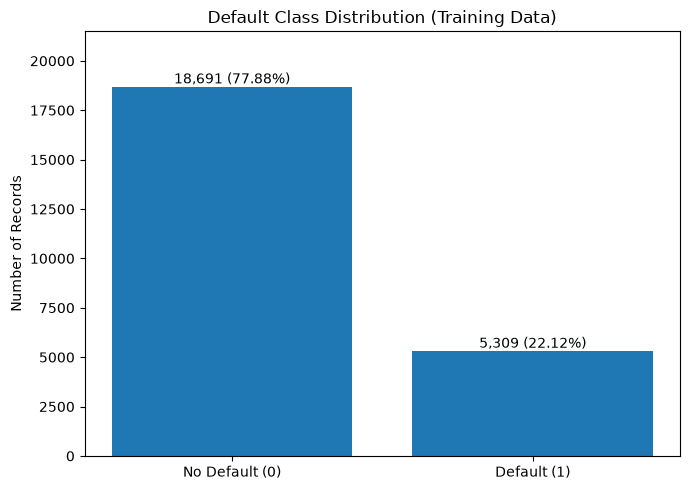

Saved: figures/eda_target_distribution.png


In [6]:
from pathlib import Path
import matplotlib.pyplot as plt

# Use training labels for EDA
counts = y_train.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Default (0)", "Default (1)"],
    counts.values
)

ax.set_title("Default Class Distribution (Training Data)")
ax.set_ylabel("Number of Records")

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} ({count / len(y_train):.2%})",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/eda_target_distribution.png", dpi=300)
plt.show()

print("Saved: figures/eda_target_distribution.png")

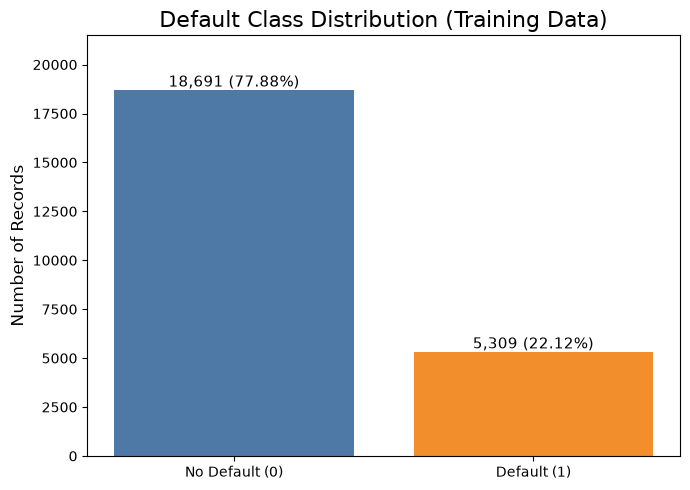

Saved: figures/eda_target_distribution.png


In [10]:
from pathlib import Path
import matplotlib.pyplot as plt

counts = y_train.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["No Default (0)", "Default (1)"],
    counts.values,
    color=["#4E79A7", "#F28E2B"]
)

ax.set_title("Default Class Distribution (Training Data)", fontsize=16)
ax.set_ylabel("Number of Records", fontsize=12)

for bar, count in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} ({count / len(y_train):.2%})",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/eda_target_distribution.png", dpi=300)
plt.show()

print("Saved: figures/eda_target_distribution.png")

## 5. Credit Limit Distribution

**Objective:** To examine the distribution of credit limits among customers and identify potential skewness and extreme values.

**Feature:** LIMIT_BAL

**Evidence:** `figures/eda_credit_limit_distribution.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

Credit Limit Statistics
Mean: 167364.67
Median: 140000.0
Minimum: 10000
Maximum: 1000000
Skewness: 1.0


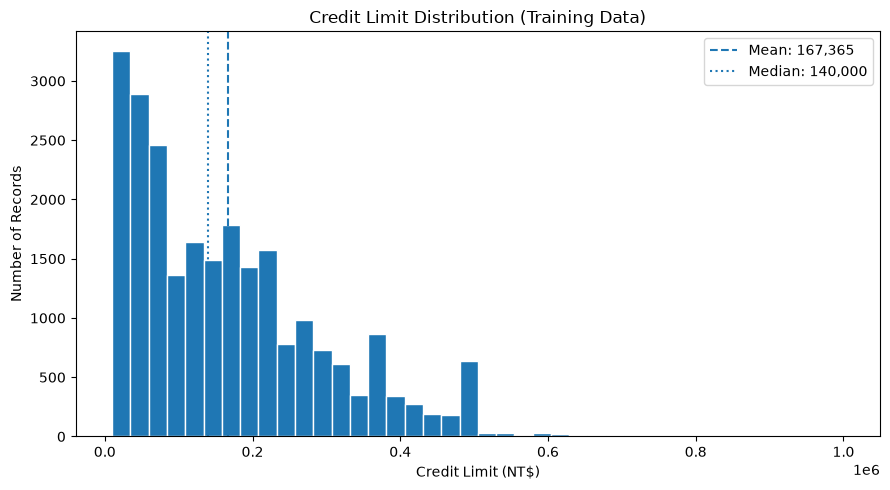

Saved: figures/eda_credit_limit_distribution.png


In [7]:
from pathlib import Path
import matplotlib.pyplot as plt

# Use training features only
credit_limit = X_train["LIMIT_BAL"]

# Calculate descriptive statistics
print("Credit Limit Statistics")
print("Mean:", round(credit_limit.mean(), 2))
print("Median:", round(credit_limit.median(), 2))
print("Minimum:", credit_limit.min())
print("Maximum:", credit_limit.max())
print("Skewness:", round(credit_limit.skew(), 3))

# Visualise the distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    credit_limit,
    bins=40,
    edgecolor="white"
)

ax.axvline(
    credit_limit.mean(),
    linestyle="--",
    label=f"Mean: {credit_limit.mean():,.0f}"
)

ax.axvline(
    credit_limit.median(),
    linestyle=":",
    label=f"Median: {credit_limit.median():,.0f}"
)

ax.set_title("Credit Limit Distribution (Training Data)")
ax.set_xlabel("Credit Limit (NT$)")
ax.set_ylabel("Number of Records")
ax.legend()

plt.tight_layout()

# Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_credit_limit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/eda_credit_limit_distribution.png")

### Findings — Credit Limit Distribution

The distribution of credit limits is positively skewed (skewness = 1.0). The mean credit limit (NT$167,364.67) is higher than the median (NT$140,000), indicating that relatively high credit limits influence the overall average. A small number of records have substantially higher credit limits, with the maximum reaching NT$1,000,000. These observations suggest that credit limits vary considerably across customers.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.


## 6. Age Distribution

**Objective:** To examine the age distribution of credit card customers and identify the typical age range, skewness, and potential extreme values.

**Feature:** AGE

**Evidence:** `figures/eda_age_distribution.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.


Age Statistics
Mean: 35.43
Median: 34.0
Minimum: 21
Maximum: 75
Standard Deviation: 9.2
Skewness: 0.738


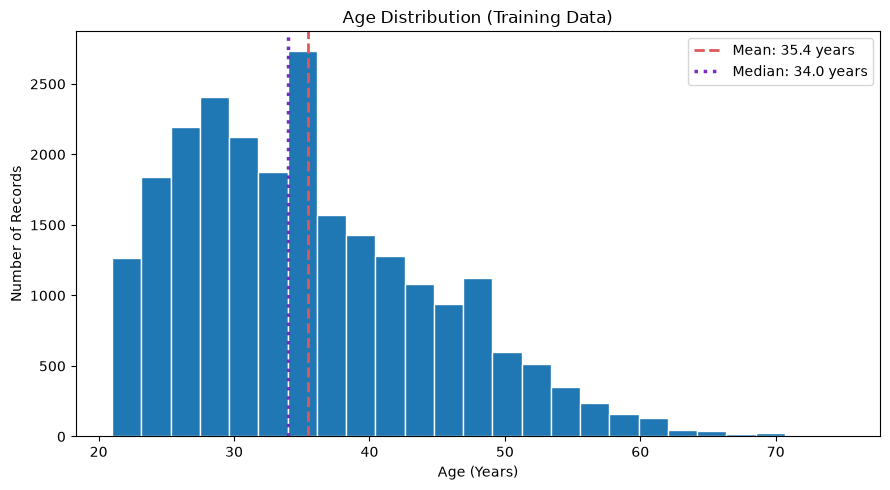

Saved: figures/eda_age_distribution.png


In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

# Use training data only
age = X_train["AGE"]

# Calculate age statistics
print("Age Statistics")
print("Mean:", round(age.mean(), 2))
print("Median:", age.median())
print("Minimum:", age.min())
print("Maximum:", age.max())
print("Standard Deviation:", round(age.std(), 2))
print("Skewness:", round(age.skew(), 3))

# Plot age distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    age,
    bins=25,
    edgecolor="white"
)

# Mean and median reference lines
ax.axvline(
    age.mean(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {age.mean():.1f} years"
)

ax.axvline(
    age.median(),
    color="#7B2CBF",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {age.median():.1f} years"
)

ax.set_title("Age Distribution (Training Data)")
ax.set_xlabel("Age (Years)")
ax.set_ylabel("Number of Records")
ax.legend()

plt.tight_layout()

# Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/eda_age_distribution.png")

Age Statistics
Mean: 35.43
Median: 34.0
Minimum: 21
Maximum: 75
Standard Deviation: 9.2
Skewness: 0.738


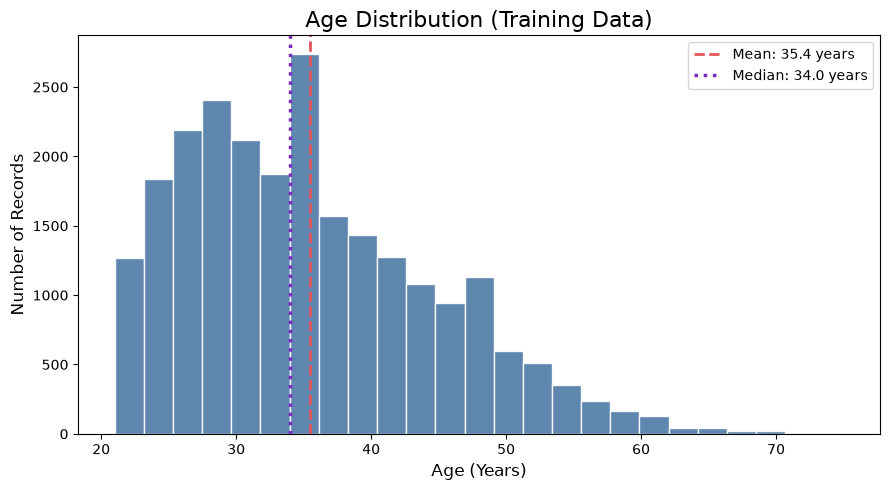

Saved: figures/eda_age_distribution.png


In [12]:
from pathlib import Path
import matplotlib.pyplot as plt

age = X_train["AGE"]

print("Age Statistics")
print("Mean:", round(age.mean(), 2))
print("Median:", age.median())
print("Minimum:", age.min())
print("Maximum:", age.max())
print("Standard Deviation:", round(age.std(), 2))
print("Skewness:", round(age.skew(), 3))

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    age,
    bins=25,
    color="#4E79A7",
    edgecolor="white",
    alpha=0.9
)

ax.axvline(
    age.mean(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {age.mean():.1f} years"
)

ax.axvline(
    age.median(),
    color="#7B2CBF",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {age.median():.1f} years"
)

ax.set_title("Age Distribution (Training Data)", fontsize=16)
ax.set_xlabel("Age (Years)", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)
ax.legend()

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/eda_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: figures/eda_age_distribution.png")

### Findings — Age Distribution

The age distribution is moderately right-skewed (skewness = 0.738), with a mean age of 35.43 years and a median of 34 years. Most customers are concentrated in early to middle adulthood, while relatively fewer customers belong to older age groups. The observed ages range from 21 to 75 years.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

Credit Limit Statistics
Mean: 167364.67
Median: 140000.0
Minimum: 10000
Maximum: 1000000
Skewness: 1.0


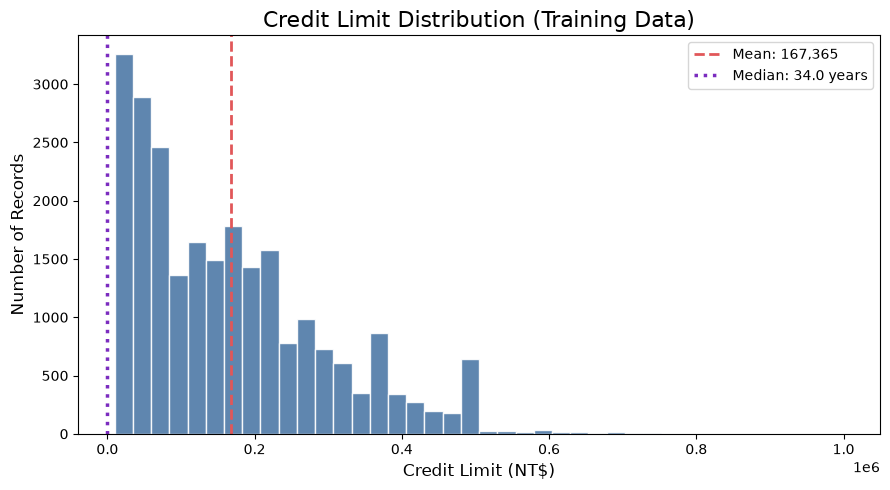

Saved: figures/eda_credit_limit_distribution.png


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt

credit_limit = X_train["LIMIT_BAL"]

print("Credit Limit Statistics")
print("Mean:", round(credit_limit.mean(), 2))
print("Median:", round(credit_limit.median(), 2))
print("Minimum:", credit_limit.min())
print("Maximum:", credit_limit.max())
print("Skewness:", round(credit_limit.skew(), 3))

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    credit_limit,
    bins=40,
    color="#4E79A7",
    edgecolor="white",
    alpha=0.9
)

ax.axvline(
    credit_limit.mean(),
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {credit_limit.mean():,.0f}"
)

ax.axvline(
    age.median(),
    color="#7B2CBF",
    linestyle=":",
    linewidth=2.5,
    label=f"Median: {age.median():.1f} years"
)

ax.set_title("Credit Limit Distribution (Training Data)", fontsize=16)
ax.set_xlabel("Credit Limit (NT$)", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)
ax.legend()

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig(
    "figures/eda_credit_limit_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved: figures/eda_credit_limit_distribution.png")

## 7. Repayment Status Analysis

**Objective:** To analyse the distribution of repayment status (PAY_0) and examine its relationship with credit card default.

**Feature:** PAY_0

**Evidence:**
- `figures/eda_repayment_status_analysis.png`
- `results/eda_repayment_status_summary.csv`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** Only training data is used to examine feature–target relationships and avoid influencing modelling decisions using the held-out test set.

Full dataset: (30000, 25)
Training features: (24000, 23)
Testing features: (6000, 23)
Training target: (24000,)
PAY_0 exists: True
Shared preprocessing contract verified!


,records,defaults,default_rate,default_rate_pct
PAY_0,,,,
-2,2198,279,0.126934,12.693358
-1,4527,753,0.166335,16.633532
0,11781,1508,0.128003,12.800272
1,3000,1031,0.343667,34.366667
2,2138,1483,0.693639,69.363891
3,245,188,0.767347,76.734694
4,58,38,0.655172,65.517241
5,18,8,0.444444,44.444444
6,10,6,0.600000,60.000000


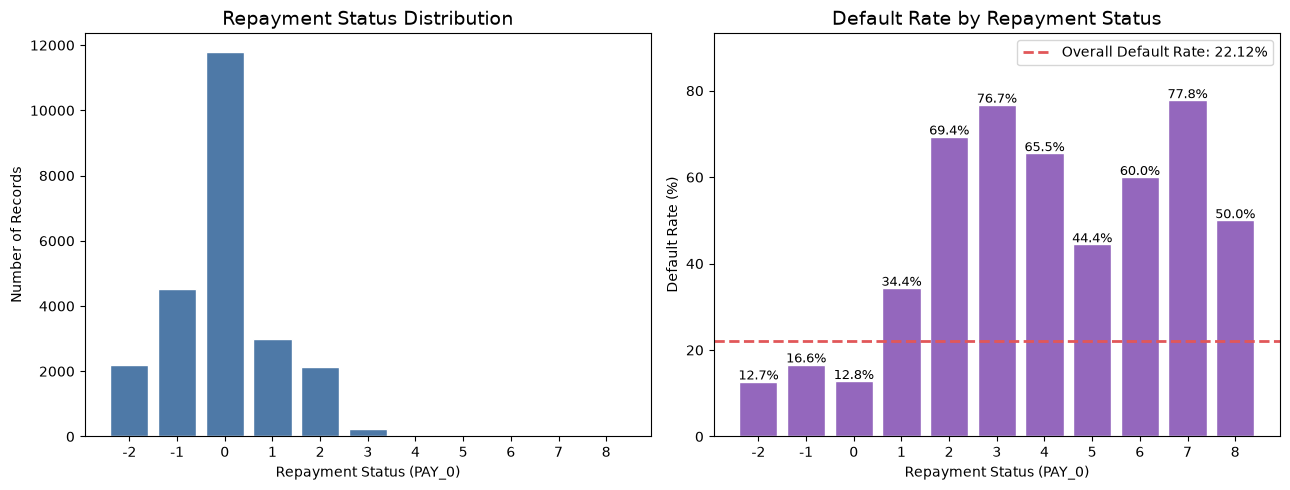

Saved: figures/eda_repayment_status_analysis.png
Saved: results/eda_repayment_status_summary.csv


In [24]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# 7. Repayment Status Analysis
# Uses M2's shared preprocessing contract
# ==========================================================

from src.preprocessing import load_data, split_data

# 1. Load the official dataset and shared train/test split
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

# 2. Verify the shared preprocessing contract
print("Full dataset:", df.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("PAY_0 exists:", "PAY_0" in X_train.columns)

assert df.shape == (30000, 25)
assert X_train.shape == (24000, 23)
assert X_test.shape == (6000, 23)
assert "ID" not in X_train.columns
assert "PAY_0" in X_train.columns

print("Shared preprocessing contract verified!")

# 3. Combine training feature and target
repayment_df = X_train[["PAY_0"]].copy()
repayment_df["default_next_month"] = y_train

# 4. Calculate repayment status statistics
summary = (
    repayment_df.groupby("PAY_0")["default_next_month"]
    .agg(["size", "sum", "mean"])
    .rename(columns={
        "size": "records",
        "sum": "defaults",
        "mean": "default_rate"
    })
    .sort_index()
)

summary["default_rate_pct"] = summary["default_rate"] * 100

display(summary)

# 5. Prepare figure
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

status_labels = summary.index.astype(str)

# Left: Number of customers by repayment status
axes[0].bar(
    status_labels,
    summary["records"],
    color="#4E79A7",
    edgecolor="white"
)

axes[0].set_title(
    "Repayment Status Distribution",
    fontsize=14
)
axes[0].set_xlabel("Repayment Status (PAY_0)")
axes[0].set_ylabel("Number of Records")

# Right: Default rate by repayment status
bars = axes[1].bar(
    status_labels,
    summary["default_rate_pct"],
    color="#9467BD",
    edgecolor="white"
)

# Overall training default rate
overall_rate = y_train.mean() * 100

axes[1].axhline(
    overall_rate,
    color="#E15759",
    linestyle="--",
    linewidth=2,
    label=f"Overall Default Rate: {overall_rate:.2f}%"
)

axes[1].set_title(
    "Default Rate by Repayment Status",
    fontsize=14
)
axes[1].set_xlabel("Repayment Status (PAY_0)")
axes[1].set_ylabel("Default Rate (%)")
axes[1].legend()

axes[1].set_ylim(
    0,
    max(summary["default_rate_pct"].max() * 1.2, 5)
)

# Add percentage labels
for bar, rate in zip(bars, summary["default_rate_pct"]):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{rate:.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

# 6. Save evidence
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_repayment_status_analysis1.png",
    dpi=300,
    bbox_inches="tight"
)

summary.to_csv(
    "results/eda_repayment_status_summary.csv"
)

plt.show()

print("Saved: figures/eda_repayment_status_analysis.png")
print("Saved: results/eda_repayment_status_summary.csv")


### Findings — Repayment Status Analysis

The analysis indicates a strong association between repayment status (PAY_0) and credit card default. Customers with PAY_0 = 0 account for the largest group (11,781 records) and have a default rate of 12.80%, which is below the overall training default rate of 22.12%.

In contrast, the default rate increases to 34.37% for PAY_0 = 1 and 69.36% for PAY_0 = 2. PAY_0 = 3 also shows a high default rate of 76.73%. These findings suggest that repayment status may be an informative predictor of default.

However, higher repayment-status categories contain relatively few observations. Their default rates should therefore be interpreted cautiously due to limited sample sizes. The observed relationship is descriptive and does not establish causation.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 8. Bill and Payment Amount Analysis

**Objective:** To examine the distributions and variability of billing and payment amounts across six recorded periods.

**Features:** BILL_AMT1–6 and PAY_AMT1–6

**Evidence:**
- `results/eda_bill_payment_summary.csv`
- `figures/eda_bill_payment_distribution.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** The histograms display the 1st–99th percentile range for readability. Full training data is retained for statistical calculations.

,mean,median,std,min,max,zero_count,negative_count
BILL_AMT1,51100.50,22330.0,73510.03,-165580.0,964511.0,1612,468
BILL_AMT2,49012.27,21107.0,70840.10,-69777.0,983931.0,1986,522
BILL_AMT3,46861.88,20031.0,68403.93,-61506.0,855086.0,2308,515
BILL_AMT4,43156.66,19004.5,64046.73,-81334.0,891586.0,2555,530
BILL_AMT5,40164.41,18102.5,60627.85,-81334.0,927171.0,2828,524
BILL_AMT6,38675.98,16993.0,59308.74,-339603.0,961664.0,3223,556
PAY_AMT1,5623.56,2100.5,16148.32,0.0,873552.0,4180,0
PAY_AMT2,5879.97,2014.0,20252.98,0.0,1215471.0,4324,0
PAY_AMT3,5215.78,1805.5,17513.55,0.0,896040.0,4780,0
PAY_AMT4,4790.33,1500.0,15060.69,0.0,621000.0,5141,0


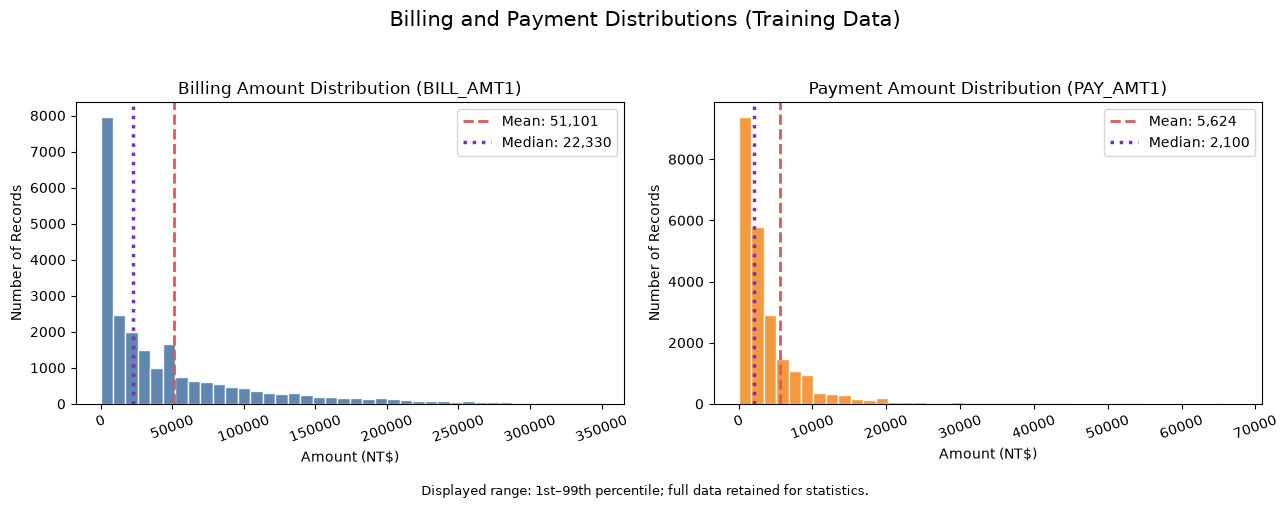

Saved: results/eda_bill_payment_summary.csv
Saved: figures/eda_bill_payment_distribution.png


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Select billing and payment features
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
payment_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# 2. Calculate descriptive statistics for all 12 features
features = bill_cols + payment_cols

summary = X_train[features].agg(
    ["mean", "median", "std", "min", "max"]
).T

summary["zero_count"] = (X_train[features] == 0).sum()
summary["negative_count"] = (X_train[features] < 0).sum()

display(summary.round(2))

# 3. Save complete statistics
Path("results").mkdir(exist_ok=True)

summary.to_csv(
    "results/eda_bill_payment_summary.csv"
)

# 4. Visualise representative billing and payment features
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_features = [
    ("BILL_AMT1", "#4E79A7", "Billing Amount"),
    ("PAY_AMT1", "#F28E2B", "Payment Amount")
]

for ax, (column, color, title) in zip(axes, plot_features):

    values = X_train[column]

    # Limit only the displayed range to reduce distortion
    lower = values.quantile(0.01)
    upper = values.quantile(0.99)

    visible = values[
        (values >= lower) & (values <= upper)
    ]

    ax.hist(
        visible,
        bins=40,
        color=color,
        edgecolor="white",
        alpha=0.9
    )

    ax.axvline(
        values.mean(),
        color="#E15759",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {values.mean():,.0f}"
    )

    ax.axvline(
        values.median(),
        color="#7B2CBF",
        linestyle=":",
        linewidth=2.5,
        label=f"Median: {values.median():,.0f}"
    )

    ax.set_title(f"{title} Distribution ({column})")
    ax.set_xlabel("Amount (NT$)")
    ax.set_ylabel("Number of Records")
    ax.legend()
    ax.tick_params(axis="x", labelrotation=20)

fig.suptitle(
    "Billing and Payment Distributions (Training Data)",
    fontsize=15
)

fig.text(
    0.5, 0.01,
    "Displayed range: 1st–99th percentile; "
    "full data retained for statistics.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])

# 5. Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_bill_payment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/eda_bill_payment_summary.csv")
print("Saved: figures/eda_bill_payment_distribution.png")

### Findings — Bill and Payment Amount Analysis

The billing and payment amount variables exhibit strongly right-skewed distributions, with mean values substantially exceeding their corresponding medians.

For BILL_AMT1, the mean billing amount is NT$51,100.50, compared with a median of NT$22,330.00. Similarly, PAY_AMT1 has a mean of NT$5,623.56 and a median of NT$2,100.50. These differences indicate that relatively large financial transactions influence the overall averages.

The analysis also reveals a considerable number of zero payment records. PAY_AMT1 contains 4,180 zero values, while PAY_AMT6 contains 5,787. Furthermore, some billing amounts are negative, which may reflect credit balances or accounting adjustments rather than data errors.

These findings suggest substantial variability and potential extreme values in financial features. Appropriate preprocessing and robust model evaluation are therefore important.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 9. Correlation Analysis

**Objective:** To examine linear relationships among numerical features and identify potential multicollinearity.

**Features:**
- LIMIT_BAL
- AGE
- BILL_AMT1–6
- PAY_AMT1–6

**Method:** Pearson Correlation Coefficient

**Evidence:**
- `figures/eda_correlation_heatmap.png`
- `results/eda_correlation_matrix.csv`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** Only numerical features from the training dataset are included. Categorical features are excluded because their numerical codes represent categories rather than continuous quantities.

,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
LIMIT_BAL,1.00,0.15,0.28,0.28,0.28,0.29,0.29,0.29,0.19,0.19,0.21,0.20,0.22,0.22
AGE,0.15,1.00,0.06,0.06,0.06,0.05,0.05,0.05,0.03,0.03,0.03,0.02,0.03,0.02
BILL_AMT1,0.28,0.06,1.00,0.95,0.90,0.86,0.83,0.80,0.14,0.11,0.16,0.16,0.17,0.18
BILL_AMT2,0.28,0.06,0.95,1.00,0.94,0.89,0.86,0.83,0.27,0.10,0.16,0.15,0.16,0.17
BILL_AMT3,0.28,0.06,0.90,0.94,1.00,0.93,0.89,0.86,0.24,0.29,0.13,0.14,0.16,0.18
BILL_AMT4,0.29,0.05,0.86,0.89,0.93,1.00,0.94,0.90,0.23,0.23,0.30,0.14,0.16,0.18
BILL_AMT5,0.29,0.05,0.83,0.86,0.89,0.94,1.00,0.95,0.21,0.20,0.26,0.29,0.14,0.16
BILL_AMT6,0.29,0.05,0.80,0.83,0.86,0.90,0.95,1.00,0.19,0.18,0.24,0.25,0.31,0.11
PAY_AMT1,0.19,0.03,0.14,0.27,0.24,0.23,0.21,0.19,1.00,0.31,0.26,0.22,0.15,0.20
PAY_AMT2,0.19,0.03,0.11,0.10,0.29,0.23,0.20,0.18,0.31,1.00,0.27,0.22,0.15,0.19


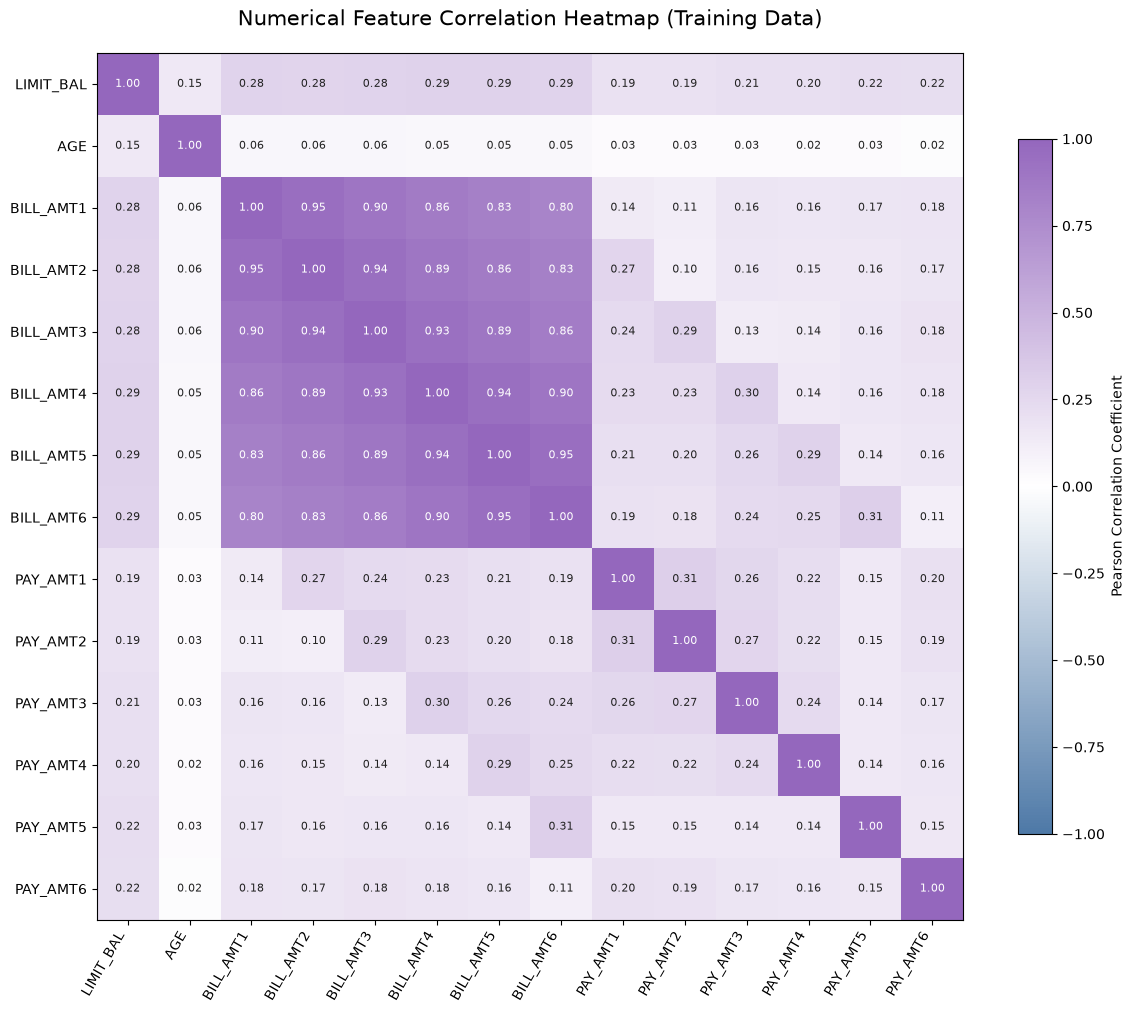

Saved: figures/eda_correlation_heatmap.png
Saved: results/eda_correlation_matrix.csv


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

# 1. Select numerical features according to M2's contract
numeric_features = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

# 2. Calculate Pearson correlation matrix
corr_matrix = X_train[numeric_features].corr(
    method="pearson"
)

display(corr_matrix.round(2))

# 3. Create professional blue-white-purple colour map
cmap = LinearSegmentedColormap.from_list(
    "professional_correlation",
    ["#4E79A7", "#FFFFFF", "#9467BD"]
)

text_color = (
    "white" if abs(value) >= 0.75
    else "#222222"
)

# 4. Plot correlation heatmap
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    corr_matrix,
    cmap=cmap,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(numeric_features)))
ax.set_yticks(range(len(numeric_features)))

ax.set_xticklabels(
    numeric_features,
    rotation=60,
    ha="right"
)

ax.set_yticklabels(numeric_features)

# 5. Display correlation values
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):

        value = corr_matrix.iloc[i, j]

        text_color = (
            "white" if abs(value) >= 0.75
            else "#222222"
        )

        ax.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color=text_color
        )

# 6. Add title and colour legend
ax.set_title(
    "Numerical Feature Correlation Heatmap (Training Data)",
    fontsize=15,
    pad=20
)

fig.colorbar(
    im,
    ax=ax,
    label="Pearson Correlation Coefficient",
    shrink=0.8
)

plt.tight_layout()

# 7. Save evidence
Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

corr_matrix.to_csv(
    "results/eda_correlation_matrix.csv"
)

plt.show()

print("Saved: figures/eda_correlation_heatmap.png")
print("Saved: results/eda_correlation_matrix.csv")


### Findings — Correlation Analysis

The Pearson correlation heatmap reveals strong positive correlations among the six billing amount features (BILL_AMT1–6). For example, BILL_AMT1 and BILL_AMT2 have a correlation coefficient of approximately 0.95, while BILL_AMT5 and BILL_AMT6 also exhibit a correlation of approximately 0.95.

These strong correlations suggest that consecutive monthly billing amounts contain overlapping information, which may introduce multicollinearity and affect the interpretability of Logistic Regression coefficients.

In comparison, correlations among payment amount features (PAY_AMT1–6) are generally weaker, ranging from approximately 0.14 to 0.31. AGE also exhibits very weak linear correlations with most billing and payment amount features.

Overall, the analysis highlights potential multicollinearity among billing variables. However, highly correlated features are not automatically removed, as their usefulness should be evaluated through the shared preprocessing and model validation process.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 10. Outlier Analysis Using the IQR Method

**Objective:** To identify potential outliers in numerical features using the Interquartile Range (IQR) method and evaluate the extent of extreme values.

**Features:**
- LIMIT_BAL
- AGE
- BILL_AMT1–6
- PAY_AMT1–6

**Method:** IQR (Interquartile Range)

**Evidence:**
- `results/eda_outlier_summary.csv`
- `figures/eda_outlier_analysis.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** Outliers are identified for exploratory analysis only. No records are removed or modified, and all calculations use the training dataset.

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
0,LIMIT_BAL,50000.00,240000.00,190000.00,-235000.00,525000.00,136,0.57
1,AGE,28.00,41.00,13.00,8.50,60.50,214,0.89
3,BILL_AMT2,2989.75,63992.75,61003.00,-88514.75,155497.25,1898,7.91
2,BILL_AMT1,3513.75,66966.50,63452.75,-91665.38,162145.62,1899,7.91
4,BILL_AMT3,2652.00,60033.75,57381.75,-83420.62,146106.38,1980,8.25
10,PAY_AMT3,390.00,4580.50,4190.50,-5895.75,10866.25,2084,8.68
5,BILL_AMT4,2332.00,54386.50,52054.50,-75749.75,132468.25,2104,8.77
7,BILL_AMT6,1225.00,48977.25,47752.25,-70403.38,120605.62,2159,9.00
8,PAY_AMT1,1000.00,5018.25,4018.25,-5027.38,11045.62,2170,9.04
9,PAY_AMT2,840.00,5000.00,4160.00,-5400.00,11240.00,2183,9.10


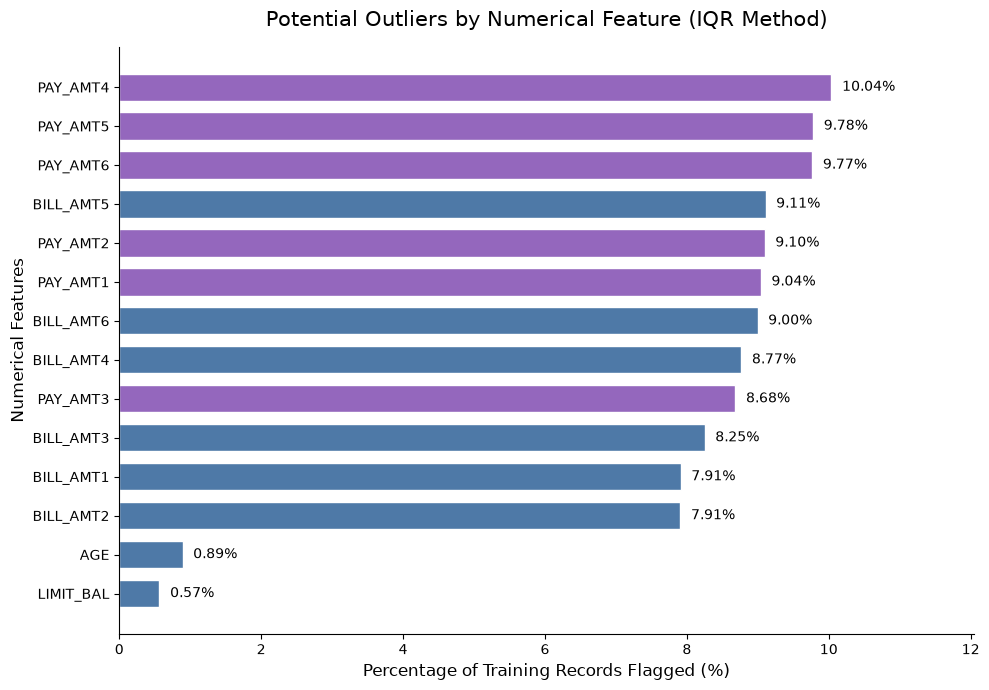

Saved: results/eda_outlier_summary.csv
Saved: figures/eda_outlier_analysis.png


In [21]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Select numerical features
numeric_features = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

# 2. Calculate outliers using the IQR method
outlier_results = []

for feature in numeric_features:

    values = X_train[feature]

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())
    outlier_percentage = (
        outlier_count / len(values) * 100
    )

    outlier_results.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outlier_count,
        "outlier_percentage": outlier_percentage
    })

# 3. Convert results into a DataFrame
outlier_summary = pd.DataFrame(
    outlier_results
).sort_values(
    "outlier_percentage",
    ascending=True
)

display(outlier_summary.round(2))

# 4. Save summary CSV
Path("results").mkdir(exist_ok=True)

outlier_summary.to_csv(
    "results/eda_outlier_summary.csv",
    index=False
)

# 5. Create professional outlier comparison chart
fig, ax = plt.subplots(figsize=(10, 7))

colors = [
    "#9467BD" if feature.startswith("PAY_AMT")
    else "#4E79A7"
    for feature in outlier_summary["feature"]
]

bars = ax.barh(
    outlier_summary["feature"],
    outlier_summary["outlier_percentage"],
    color=colors,
    edgecolor="white",
    height=0.7
)

# 6. Add percentage labels
for bar, value in zip(
    bars,
    outlier_summary["outlier_percentage"]
):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

ax.set_xlim(
    0,
    max(
        outlier_summary["outlier_percentage"].max() * 1.2,
        5
    )
)

ax.set_title(
    "Potential Outliers by Numerical Feature (IQR Method)",
    fontsize=15,
    pad=15
)

ax.set_xlabel(
    "Percentage of Training Records Flagged (%)",
    fontsize=12
)

ax.set_ylabel("Numerical Features", fontsize=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# 7. Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_outlier_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/eda_outlier_summary.csv")
print("Saved: figures/eda_outlier_analysis.png")


### Findings — Outlier Analysis

The IQR-based outlier analysis reveals that billing and payment amounts contain substantially more potential outliers than customer age and credit limit.

Among the numerical features, PAY_AMT4 has the highest proportion of potential outliers, with 2,409 records (10.04%), followed by PAY_AMT5 (9.78%) and PAY_AMT6 (9.77%). Billing amount features also exhibit relatively high outlier proportions, ranging from 7.91% to 9.11%.

In contrast, AGE and LIMIT_BAL have comparatively low outlier proportions of 0.89% and 0.57%, respectively.

These findings indicate considerable variability and extreme values in financial transaction features. However, the IQR method identifies statistical outliers rather than confirmed data errors. Therefore, no observations were removed during EDA, and the findings should be considered when evaluating preprocessing choices and model robustness.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 11. Credit Limit and Age vs Default Rate

**Objective:** To investigate how credit card default rates vary across different credit limit quartiles and customer age groups.

**Features:**
- LIMIT_BAL
- AGE

**Target:** default_next_month

**Method:** Group-based default rate analysis using training data only.

**Evidence:**
- `results/eda_feature_default_summary.csv`
- `figures/eda_feature_default_relationships.png`

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation

**Note:** The analysis is descriptive and does not establish causal relationships. The held-out test set is not used.

,group,records,defaults,default_rate,feature,default_rate_pct
0,Q1 (Lowest),6146,1977,0.321673,LIMIT_BAL,32.167263
1,Q2,6067,1509,0.248723,LIMIT_BAL,24.872260
2,Q3,6178,1083,0.175299,LIMIT_BAL,17.529945
3,Q4 (Highest),5609,740,0.131931,LIMIT_BAL,13.193083
4,21-29,7706,1770,0.229691,AGE,22.969115
5,30-39,9040,1823,0.201659,AGE,20.165929
6,40-49,5123,1173,0.228967,AGE,22.896740
7,50-59,1868,470,0.251606,AGE,25.160600
8,60+,263,73,0.277567,AGE,27.756654


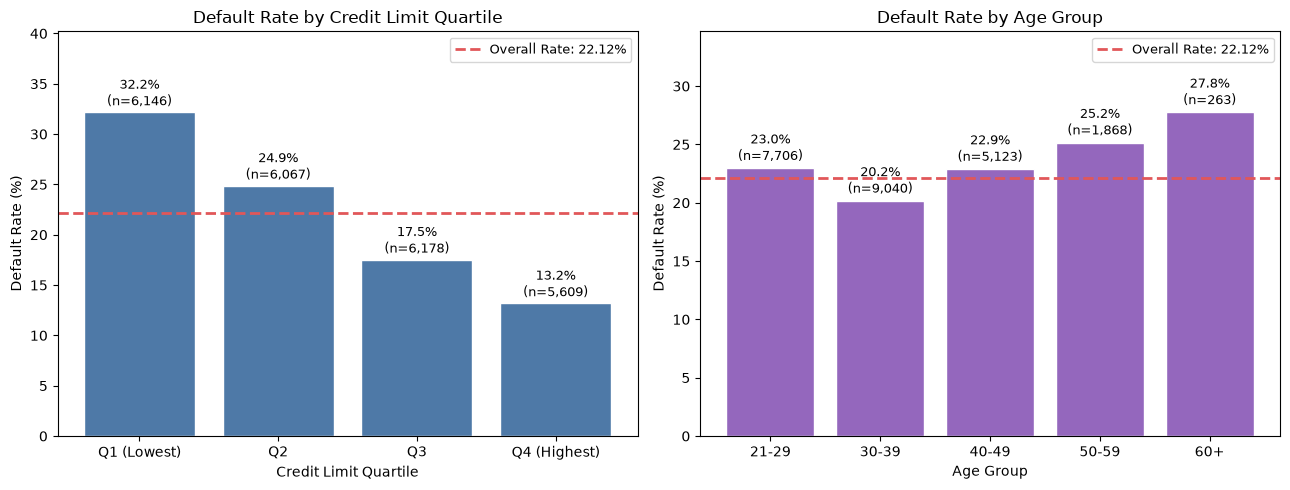

Saved: results/eda_feature_default_summary.csv
Saved: figures/eda_feature_default_relationships.png


In [22]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Combine training features and target
eda_df = X_train[["LIMIT_BAL", "AGE"]].copy()
eda_df["default_next_month"] = y_train

# 2. Group credit limits into quartiles
eda_df["credit_limit_group"] = pd.qcut(
    eda_df["LIMIT_BAL"],
    q=4,
    labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"]
)

# 3. Group customer ages
eda_df["age_group"] = pd.cut(
    eda_df["AGE"],
    bins=[20, 29, 39, 49, 59, float("inf")],
    labels=["21-29", "30-39", "40-49", "50-59", "60+"]
)

# 4. Calculate default rate by credit limit
credit_summary = (
    eda_df.groupby("credit_limit_group", observed=True)
    ["default_next_month"]
    .agg(records="size", defaults="sum", default_rate="mean")
    .reset_index()
    .rename(columns={"credit_limit_group": "group"})
)

credit_summary["feature"] = "LIMIT_BAL"

# 5. Calculate default rate by age group
age_summary = (
    eda_df.groupby("age_group", observed=True)
    ["default_next_month"]
    .agg(records="size", defaults="sum", default_rate="mean")
    .reset_index()
    .rename(columns={"age_group": "group"})
)

age_summary["feature"] = "AGE"

# 6. Combine and save summary
summary = pd.concat(
    [credit_summary, age_summary],
    ignore_index=True
)

summary["default_rate_pct"] = (
    summary["default_rate"] * 100
)

display(summary)

Path("results").mkdir(exist_ok=True)
summary.to_csv(
    "results/eda_feature_default_summary.csv",
    index=False
)

# 7. Create comparison charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

overall_rate = y_train.mean() * 100

plot_settings = [
    (credit_summary, "Credit Limit Quartile", "#4E79A7"),
    (age_summary, "Age Group", "#9467BD")
]

for ax, (data, xlabel, color) in zip(axes, plot_settings):

    rates = data["default_rate"] * 100

    bars = ax.bar(
        data["group"].astype(str),
        rates,
        color=color,
        edgecolor="white"
    )

    ax.axhline(
        overall_rate,
        color="#E15759",
        linestyle="--",
        linewidth=2,
        label=f"Overall Rate: {overall_rate:.2f}%"
    )

    for bar, rate, count in zip(
        bars, rates, data["records"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.7,
            f"{rate:.1f}%\n(n={count:,})",
            ha="center",
            fontsize=9
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Default Rate (%)")
    ax.set_title(f"Default Rate by {xlabel}")
    ax.set_ylim(0, max(rates.max() * 1.25, overall_rate * 1.3))
    ax.legend(fontsize=9)

plt.tight_layout()

# 8. Save figure
Path("figures").mkdir(exist_ok=True)

plt.savefig(
    "figures/eda_feature_default_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/eda_feature_default_summary.csv")
print("Saved: figures/eda_feature_default_relationships.png")


### Findings — Credit Limit and Age vs Default Rate

The analysis reveals a clear inverse association between credit limit and credit card default. Customers in the lowest credit limit quartile (Q1) have a default rate of 32.17%, compared with 13.19% among customers in the highest quartile (Q4). This difference of approximately 18.97 percentage points suggests that credit limit may be an informative predictor of default risk.

For age, the lowest observed default rate is found among customers aged 30–39 (20.17%). Default rates are higher in the 50–59 (25.16%) and 60+ (27.76%) age groups. However, the 60+ group contains only 263 records, so its estimated default rate should be interpreted cautiously.

Overall, the results suggest that both credit limit and age may contribute useful information to default prediction. Nevertheless, these descriptive relationships do not establish causation and should be assessed further through machine learning model evaluation.

**Report Section:** Chapter 2.2 — Feature Analysis and Visualisation.

## 12. Summary of EDA Findings

**Objective:** To consolidate the key findings from exploratory data analysis and explain their implications for subsequent preprocessing and machine learning modelling.

**Key Findings:**

1. **Class Imbalance:** The training dataset contains 77.88% non-default cases and 22.12% default cases. This supports using stratified sampling and evaluating positive-class F1-score, precision, and recall.

2. **Repayment Status:** PAY_0 shows a strong descriptive association with default. The default rate increases from 12.80% for PAY_0 = 0 to 69.36% for PAY_0 = 2.

3. **Credit Limit:** The lowest credit limit quartile has a default rate of 32.17%, compared with 13.19% in the highest quartile, indicating an inverse association between credit limit and observed default risk.

4. **Customer Age:** Default rates vary across age groups, although smaller groups such as customers aged 60 and above require cautious interpretation.

5. **Financial Distributions and Outliers:** Billing and payment amounts exhibit right-skewed distributions and substantial numbers of potential IQR outliers. These observations do not necessarily indicate invalid records.

6. **Feature Correlation:** The billing amount features are strongly correlated, suggesting potential multicollinearity that may affect the interpretation of linear models.

**Implications for Modelling:**

The findings support the use of consistent preprocessing, stratified cross-validation, and evaluation metrics that account for class imbalance. The different feature characteristics also provide a rationale for comparing Logistic Regression, Random Forest, and Gradient Boosting. Any feature removal, transformation, or outlier treatment should be assessed through training-data validation rather than decided solely from descriptive analysis.

**Report Section:** Chapter 2.3 — Summary of EDA Findings.

---
# 02 — Preprocessing & Logistic Regression


# M2 — Shared Preprocessing and Logistic Regression
6001CMD | Group 8 | Default of Credit Card Clients (UCI #350)

Objectives: audit data quality, demonstrate the shared preprocessing pipeline, establish a logistic regression baseline, tune using positive-class F1, and examine numerical scaling. The final test set is reserved for M3.

## 1. Environment setup

In [3]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "preprocessing.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from src.preprocessing import load_data, split_data, build_pipeline, get_cv, RANDOM_STATE
from src.logistic_regression import run_baseline, run_tuning, run_preprocessing_experiment, save_lr_results
print(sys.version)
print("pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
pandas: 3.1.1 scikit-learn: 1.9.1


## 2. Dataset loading and quality audit
The proposed cleaning policy retains records and original category codes, removes ID from predictors, and validates the input schema. Team confirmation of the policy is pending.

In [4]:
df = load_data()
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Duplicates excluding ID:", df.drop(columns="ID").duplicated().sum())
print("Duplicate predictors:", df.drop(columns=["ID", "default_next_month"]).duplicated().sum())
display(df["default_next_month"].value_counts().rename("count").to_frame().assign(proportion=lambda x: x["count"] / len(df)))
for col in ["EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(col, sorted(df[col].unique()))

Shape: (30000, 25)
Missing values: 0
Duplicate IDs: 0
Duplicates excluding ID: 35
Duplicate predictors: 56


,count,proportion
default_next_month,,
0,23364,0.7788
1,6636,0.2212


EDUCATION [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
PAY_0 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np

## 3. Shared preprocessing and validation protocol
Numerical variables are standardised for LR; categorical variables, including repayment status codes, are one-hot encoded. The shared pipeline fits transformations inside each training fold. Tree models can disable numerical scaling. The stratified 80/20 split and shuffled three-fold stratified CV use seed 42.

In [5]:
X_train, X_test, y_train, y_test = split_data(df)
print("Training:", X_train.shape, "Held-out:", X_test.shape)
print("Index overlap:", len(X_train.index.intersection(X_test.index)))
assert "ID" not in X_train.columns and "default_next_month" not in X_train.columns
display(y_train.value_counts())
print(get_cv())
print(build_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), scale_numeric=True))

Training: (24000, 23) Held-out: (6000, 23)
Index overlap: 0


default_next_month
0    18691
1     5309
Name: count, dtype: int64

StratifiedKFold(n_splits=3, random_state=42, shuffle=True)
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['LIMIT_BAL', 'AGE',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AMT3', 'PAY_AMT4',
                                                   'PAY_AMT5', 'PAY_AMT6']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['SEX', 'EDU

## 4. Logistic regression baseline
Default primary hyperparameters with max_iter=2000; evaluation uses training CV only.

In [6]:
baseline_results = run_baseline(X_train, y_train)


=== Logistic Regression Baseline ===
ACCURACY: 0.8210 (SD: 0.0013)
PRECISION: 0.6804 (SD: 0.0090)
RECALL: 0.3605 (SD: 0.0029)
F1: 0.4713 (SD: 0.0010)
ROC_AUC: 0.7685 (SD: 0.0078)

Elapsed time: 0.59 seconds


## 5. Hyperparameter tuning
GridSearchCV compares 20 parameter combinations across three folds. Selection uses positive-class F1 only.

In [7]:
search, tuning_elapsed = run_tuning(X_train, y_train)
print(search.best_params_)
print(search.best_score_)


=== Logistic Regression Tuning ===
Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Best CV F1: 0.5347
Standard Deviation: 0.0134
Elapsed time: 13.95 seconds
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
0.5346859143908457


## 6. Preprocessing impact experiment
The existing experiment holds LR hyperparameters fixed at the observed optimum (C=0.1, balanced, lbfgs) and changes numerical scaling only. Non-convergence warnings are retained as evidence of the iteration-limit constraint. Running this section regenerates the CSV.

In [8]:
impact = run_preprocessing_experiment(X_train, y_train)
display(impact)


=== Preprocessing Impact Experiment ===

With Scaling
ACCURACY: 0.7747 (SD: 0.0094)
PRECISION: 0.4926 (SD: 0.0176)
RECALL: 0.5849 (SD: 0.0074)
F1: 0.5347 (SD: 0.0134)
ROC_AUC: 0.7691 (SD: 0.0073)
Elapsed time: 0.53 seconds


c:\ML-Group8-Project-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\ML-Group8-Project-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.h


Without Scaling
ACCURACY: 0.7723 (SD: 0.0045)
PRECISION: 0.4878 (SD: 0.0086)
RECALL: 0.5775 (SD: 0.0057)
F1: 0.5288 (SD: 0.0066)
ROC_AUC: 0.7634 (SD: 0.0044)
Elapsed time: 10.48 seconds

Saved: results/preprocessing_impact.csv


c:\ML-Group8-Project-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,experiment,scale_numeric,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,elapsed_seconds
0,With Scaling,True,0.774667,0.009363,0.492573,0.017614,0.584857,0.007376,0.534686,0.013352,0.769068,0.007263,0.531731
1,Without Scaling,False,0.772333,0.004546,0.487779,0.008562,0.577511,0.005671,0.528836,0.006572,0.763408,0.004439,10.484371


## 7. Export and compare results
Running this section regenerates lr_cv.json. Times may differ across runs.


Saved: results/lr_cv.json


,Baseline,Tuned (scaled)
accuracy,0.8210,0.7747
precision,0.6804,0.4926
recall,0.3605,0.5849
f1,0.4713,0.5347
roc_auc,0.7685,0.7691


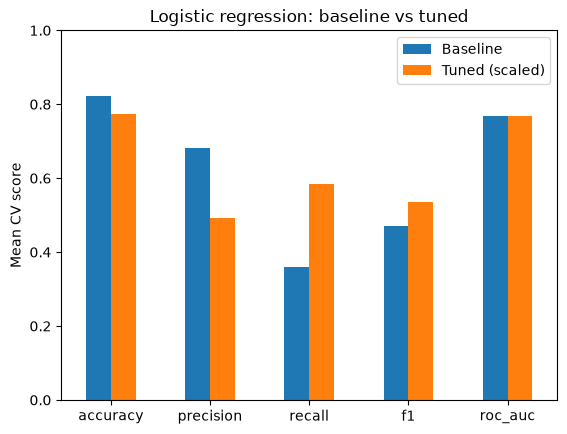

In [9]:
lr_results = save_lr_results(baseline_results, search, tuning_elapsed)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
scaled = impact.loc[impact["scale_numeric"] == True].iloc[0]
comparison = pd.DataFrame({"Baseline": [baseline_results[f"test_{m}"].mean() for m in metrics], "Tuned (scaled)": [scaled[f"{m}_mean"] for m in metrics]}, index=metrics)
display(comparison.round(4))
comparison.plot.bar(rot=0, ylim=(0,1), ylabel="Mean CV score", title="Logistic regression: baseline vs tuned");

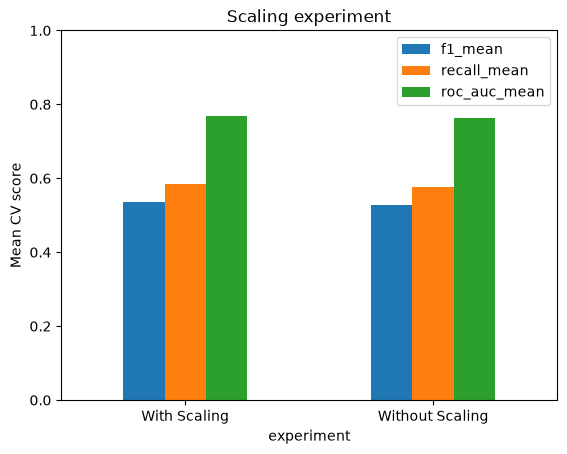

In [10]:
impact.set_index("experiment")[["f1_mean", "recall_mean", "roc_auc_mean"]].plot.bar(rot=0, ylim=(0,1), ylabel="Mean CV score", title="Scaling experiment");

## 8. Conclusion and limitations
In the recorded local run, tuning improved mean CV F1 from 0.4713 to 0.5347 and recall from 0.3605 to 0.5849, with lower accuracy and precision. Scaling yielded F1 0.5347 versus 0.5288 without scaling; all three unscaled folds reached the 2000-iteration limit, so their scores represent an incompletely converged model, not an optimised unscaled alternative. Runtime was 0.52 s with scaling and 9.35 s without in that run; runtime is environment-dependent. Duplicate predictor records and possible cross-split feature overlap remain limitations. The tuned CV score is a model-selection estimate, not independent test performance. Final test evaluation is reserved for M3. Team approval of cleaning policy and receiver-side integration testing remain to be confirmed. If a later run selects different parameters, update the fixed-parameter experiment and interpretation accordingly.

---
# 03 — Random Forest


# M3 Random Forest Development & Chapter 7 Final 4-Model Evaluation

**Project:** Credit Card Default Prediction — UCI Default of Credit Card Clients (#350, 30,000 clients, 22.12% positive rate)  
**Repository:** `ML-Group8-Project` | **Shared Protocol:** Stratified 80/20 split (`24,000` train / `6,000` held-out test, `random_state=42`), 3-fold shuffled `StratifiedKFold(random_state=42)`, primary selection metric positive-class F1 at default cutoff `0.50`  
**Author Scope:** Member 3 (M3) — Random Forest (`src/random_forest.py`) & Part G Final Comparative Evaluation (`src/final_evaluation.py`)

---

### Notebook Structure
- **Part I (Chapters 4 & 5) — Random Forest Training, Diagnostics & Hyperparameter Tuning *(Training Split Only)***
  1. Environment, shared preprocessing pipeline (`91` OHE features fitted inside CV folds), and `PAY_0` risk-cliff audit
  2. Baseline Ladder (`Dummy prior`, `Dummy all-positive`, `Balanced LR`, `Untuned Default RF`) & tree memorization audit
  3. Stage 1 Tuning: Out-of-Bag (`OOB`) tree-count convergence (`25` → `600` trees) using `oob_decision_function_`
  4. Stage 2 Tuning: `RandomizedSearchCV` (`30` draws × `3` folds = `90` fits, `seed=42`, Winning Run `64f4bcdb`, Trial 14)
  5. Live 3-fold verification of Tuned RF (`64f4bcdb`) vs. Baseline RF (generalisation gap, tree complexity, OOF threshold & calibration)
  6. Feature Importance Audit: Out-of-sample permutation importance vs. in-sample Mean Decrease in Impurity (`MDI`)
- **Part II (Chapter 7, Section 7.1) — Final 4-Model Held-Out Evaluation *(Part G)***
  7. Pre-flight verification, frozen pipeline parity (`n_jobs=1`), and sealed held-out prediction integrity check
  8. Held-out performance table (`Table 7.1.1`) & 2×2 confusion matrices (`Figure 7.1.1(a)`)
  9. Held-out ROC, Precision–Recall, probability calibration & 4×4 inter-model agreement (`Figure 7.1.1(b)`)
  10. Generalisation gaps & single-threaded computational efficiency (`Table 7.1.2`, `Figure 7.1.2`)
  11. Live statistical significance tests: McNemar's test, 2,000-resample stratified bootstrap 95% CIs & Nadeau–Bengio corrected CV t-tests (`Table 7.1.3`, `Figure 7.1.3`)
  12. Cross-model domain-grouped permutation importance & M4 handoff checklist (bridging to Sections 7.2 & 7.3)

> **Zero-Leakage Guarantee:** Part I touches **only** `X_train, y_train` (`24,000` rows). All stateful preprocessing (`StandardScaler`, `OneHotEncoder`) is wrapped inside `sklearn.pipeline.Pipeline` per CV fold. The held-out test split (`6,000` rows) is evaluated strictly once in Part II using `src/final_evaluation.py`.

---
## Part I — M3 Random Forest Training, Diagnostics & Hyperparameter Tuning (Training Split Only)

### 1. Environment, Shared Preprocessing Contract & Training-Split Audit
This section verifies library versions for artifact reproducibility, confirms the exact shared 80/20 split (`24,000` train / `6,000` untouched test, `random_state=42`), inspects the `91` encoded features produced when fitting the shared `ColumnTransformer` strictly on `X_train`, and confirms the sharp non-linear `PAY_0` default-rate risk cliff reported in Chapter 4.

In [ ]:
import json
import os
import platform
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict, cross_validate

try:
    display
except NameError:
    def display(obj):
        print(obj)

# Auto-discover repository root whether launched from notebooks/, repo root, or parent folder.
_cwd = Path.cwd().resolve()
_candidates = [_cwd, _cwd / "ML-Group8-Project", *_cwd.parents]
PROJECT_ROOT = next(
    (p for p in _candidates if (p / "src" / "preprocessing.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate ML-Group8-Project root containing src/preprocessing.py")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.preprocessing import (
    CATEGORICAL_FEATURES,
    NUMERICAL_FEATURES,
    RANDOM_STATE,
    build_pipeline,
    get_cv,
    load_data,
    split_data,
)
from src.random_forest import SCORING, make_random_forest

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cbd5e1",
    "axes.grid": True,
    "grid.color": "#e2e8f0",
    "grid.linestyle": "-",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
})

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(
    f"Environment  : Python {platform.python_version()} | "
    f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | "
    f"numpy {np.__version__} | scipy {scipy.__version__}"
)

# Load shared dataset and split (random_state=42); keep X_test untouched throughout Part I.
df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
cv_folds = list(get_cv().split(X_train, y_train))

# Inspect encoded feature dimensionality strictly on X_train.
rf_pipe_preview = make_random_forest()
X_train_enc_preview = rf_pipe_preview.named_steps["preprocess"].fit_transform(X_train)

print(
    f"Dataset Audit: {len(df):,} total rows | {X_train.shape[1]} raw predictors -> "
    f"{X_train_enc_preview.shape[1]} OHE features on X_train | 0 missing values"
)
print(
    f"Split Shapes : X_train={X_train.shape} (pos={y_train.mean():.4%}), "
    f"X_test={X_test.shape} [HELD OUT UNTIL PART II] (pos={y_test.mean():.4%})"
)

# Training-split PAY_0 non-monotone risk cliff audit (zero test access).
pay0_series = X_train["PAY_0"]
cliff_groups = [
    ("PAY_0 <= 0 (No Delay / Revolving / Paid Full)", pay0_series <= 0),
    ("PAY_0 = 1 (1 Month Delay)", pay0_series == 1),
    ("PAY_0 >= 2 (2+ Months Serious Delinquency)", pay0_series >= 2),
]
cliff_rows = []
for label, mask in cliff_groups:
    n_clients = int(mask.sum())
    n_def = int(y_train.loc[mask].sum())
    cliff_rows.append({
        "PAY_0 Group (Training Split)": label,
        "Clients": f"{n_clients:,}",
        "Defaults": f"{n_def:,}",
        "Default Rate": f"{y_train.loc[mask].mean():.1%}",
    })
display(pd.DataFrame(cliff_rows))

PROJECT_ROOT : C:\Users\drago\Documents\random forest\ML-Group8-Project
Environment  : Python 3.13.7 | scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1
Dataset Audit: 30,000 total rows | 23 raw predictors -> 91 OHE features on X_train | 0 missing values
Split Shapes : X_train=(24000, 23) (pos=22.1208%), X_test=(6000, 23) [HELD OUT UNTIL PART II] (pos=22.1167%)


PAY_0 Group (Training Split),Clients,Defaults,Default Rate
PAY_0 <= 0 (No Delay / Revolving / Paid Full),"18,506","2,540",13.7%
PAY_0 = 1 (1 Month Delay),"3,000","1,031",34.4%
PAY_0 >= 2 (2+ Months Serious Delinquency),"2,494","1,738",69.7%


### 2. Baseline Ladder & Untuned Random Forest Failure Mode Audit
Before any tuning, we evaluate four baselines on **identical 3-fold `StratifiedKFold(random_state=42)` training CV splits**:
- **Dummy (Majority Prior):** Always predicts non-default (`0`), defining the accuracy trap (`77.88%` accuracy, `0.0000` F1).
- **Dummy (All-Positive Floor):** Always predicts default (`1`), setting the theoretical F1 baseline `2p/(1+p) = 0.3623` and PR-AUC floor `p = 0.2212`.
- **Balanced Logistic Regression:** Shared linear baseline (`C=0.1, class_weight="balanced", scale_numeric=True`).
- **Untuned Default Random Forest:** `n_estimators=100, max_depth=None, min_samples_leaf=1, class_weight=None, n_jobs=1` (`scale_numeric=False`).

Fitting the untuned Random Forest on `X_train` exposes three critical failure modes that motivate Stage 1 & Stage 2 tuning: extreme overfitting (`Train F1 ≈ 0.9989` vs. `CV F1 ≈ 0.4695`, gap `+0.5294`), extreme tree complexity (`mean depth 41.7`, `4,149` leaves/tree with `51.0%` single-customer singleton leaves), and suppressed recall (`0.3658`) under unweighted class priors.

In [ ]:
def audit_forest_trees(rf_estimator) -> dict:
    """Inspect realized depth, leaf counts, and single-customer leaf fraction."""
    depths, leaves, singletons, total_leaves = [], [], 0, 0
    for est in rf_estimator.estimators_:
        t = est.tree_
        is_leaf = t.children_left == -1
        depths.append(int(t.max_depth))
        n_leaf = int(np.sum(is_leaf))
        leaves.append(n_leaf)
        singletons += int(np.sum(is_leaf & (t.n_node_samples == 1)))
        total_leaves += n_leaf
    return {
        "mean_depth": float(np.mean(depths)),
        "max_depth": int(np.max(depths)),
        "mean_leaves": float(np.mean(leaves)),
        "singleton_fraction": float(singletons / total_leaves),
    }

baseline_models = {
    "Dummy (Majority Prior)": build_pipeline(DummyClassifier(strategy="prior"), scale_numeric=False),
    "Dummy (All-Positive Floor)": build_pipeline(DummyClassifier(strategy="constant", constant=1), scale_numeric=False),
    "LR (Balanced, C=0.1)": build_pipeline(
        LogisticRegression(C=0.1, class_weight="balanced", solver="lbfgs", max_iter=2000, random_state=RANDOM_STATE),
        scale_numeric=True,
    ),
    "Untuned Default RF (100t)": make_random_forest(),
}

ladder_rows = []
baseline_rf_cv_summary = None
for name, pipe in baseline_models.items():
    cv_res = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv_folds,
        scoring=SCORING,
        return_train_score=True,
        n_jobs=3,
        error_score="raise",
    )
    train_f1 = float(cv_res["train_f1"].mean())
    cv_f1 = float(cv_res["test_f1"].mean())
    cv_f1_std = float(cv_res["test_f1"].std())
    gap = train_f1 - cv_f1

    row = {
        "Model (3-Fold Training CV)": name,
        "Train F1": round(train_f1, 4),
        "CV F1": f"{cv_f1:.4f} ± {cv_f1_std:.4f}",
        "Train–CV Gap": f"{gap:+.4f}",
        "CV Precision": round(float(cv_res["test_precision"].mean()), 4),
        "CV Recall": round(float(cv_res["test_recall"].mean()), 4),
        "CV ROC-AUC": round(float(cv_res["test_roc_auc"].mean()), 4),
        "CV PR-AUC": round(float(cv_res["test_average_precision"].mean()), 4),
    }
    if name == "Untuned Default RF (100t)":
        fitted_base_rf = clone(pipe).fit(X_train, y_train)
        base_tree_stats = audit_forest_trees(fitted_base_rf.named_steps["model"])
        base_oof_probs = cross_val_predict(
            pipe, X_train, y_train, cv=cv_folds, method="predict_proba", n_jobs=3
        )[:, 1]
        bp_c, br_c, bt_c = precision_recall_curve(y_train, base_oof_probs)
        bf1_s = np.divide(
            2.0 * bp_c[:-1] * br_c[:-1],
            bp_c[:-1] + br_c[:-1],
            out=np.zeros(len(bt_c)),
            where=(bp_c[:-1] + br_c[:-1]) > 0,
        )
        row["Tree Audit"] = (
            f"depth {base_tree_stats['mean_depth']:.1f} (max {base_tree_stats['max_depth']}), "
            f"{base_tree_stats['mean_leaves']:,.0f} leaves, {base_tree_stats['singleton_fraction']:.1%} singletons"
        )
        baseline_rf_cv_summary = {
            "train_f1": train_f1,
            "cv_f1": cv_f1,
            "cv_f1_std": cv_f1_std,
            "gap": gap,
            "precision": float(cv_res["test_precision"].mean()),
            "recall": float(cv_res["test_recall"].mean()),
            "roc_auc": float(cv_res["test_roc_auc"].mean()),
            "pr_auc": float(cv_res["test_average_precision"].mean()),
            "oof_best_th": float(bt_c[int(np.argmax(bf1_s))]),
            "oof_brier": float(brier_score_loss(y_train, base_oof_probs)),
            **base_tree_stats,
        }
    else:
        row["Tree Audit"] = "N/A"
    ladder_rows.append(row)

display(pd.DataFrame(ladder_rows))

Model (3-Fold Training CV),Train F1,CV F1,Train–CV Gap,CV Precision,CV Recall,CV ROC-AUC,CV PR-AUC,Tree Audit
Dummy (Majority Prior),0.0000,0.0000 ± 0.0000,+0.0000,0.0000,0.0000,0.5000,0.2212,N/A
Dummy (All-Positive Floor),0.3623,0.3623 ± 0.0001,+0.0000,0.2212,1.0000,0.5000,0.2212,N/A
"LR (Balanced, C=0.1)",0.5369,0.5347 ± 0.0134,+0.0022,0.4926,0.5849,0.7691,0.5396,N/A
Untuned Default RF (100t),0.9989,0.4695 ± 0.0021,+0.5294,0.6557,0.3658,0.7656,0.5316,"depth 41.7 (max 54), 4,149 leaves, 51.0% singletons"


### 3. Stage 1 Tuning: Out-of-Bag (`OOB`) Tree-Count Convergence (`25` → `600` Trees)
Following Probst, Wright and Boulesteix (2019), tree count (`n_estimators`) is decoupled from structural tuning via incremental `warm_start=True, oob_score=True` evaluation strictly on the `24,000`-row training split (~37% left-out rows per tree). Crucially, continuous OOB probabilities from `oob_decision_function_[:, 1]` are used to compute OOB PR-AUC, ROC-AUC, Brier score, and best OOB F1. Scores flatten within `±0.001` of their 600-tree peak between `300` and `500` trees, justifying fixing `n_estimators = 400` (`< 0.0006` below 600-tree ROC-AUC peak while cutting search compute by 20–33%).

n_estimators,oob_pr_auc,oob_roc_auc,oob_brier,oob_best_f1
25,0.4686,0.7274,0.1537,0.4877
50,0.5048,0.7494,0.1444,0.5128
100,0.5243,0.7592,0.1404,0.5247
150,0.5287,0.7630,0.1392,0.5287
200,0.5325,0.7643,0.1386,0.5309
300,0.5360,0.7666,0.1379,0.5345
400,0.5393,0.7686,0.1373,0.5365
500,0.5402,0.7689,0.1371,0.5374
600,0.5404,0.7692,0.1370,0.5369


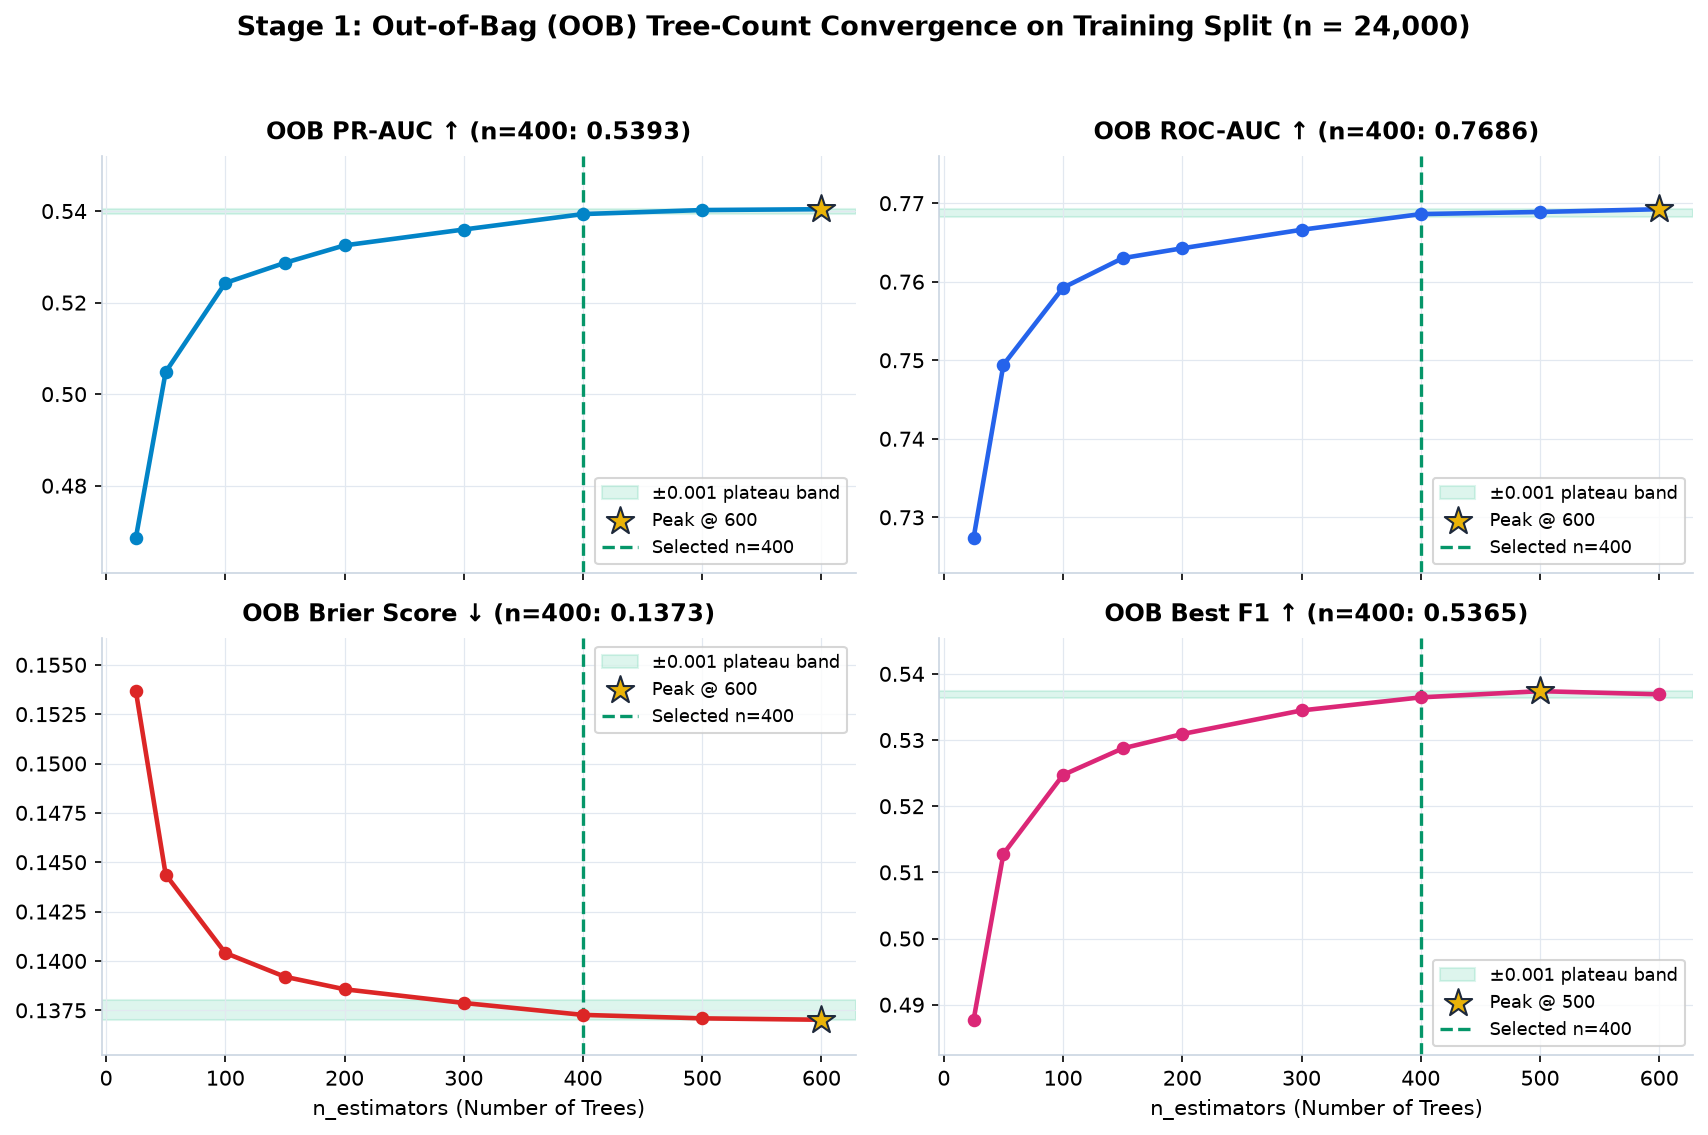

In [ ]:
# Encode X_train once for incremental OOB tree-growth monitoring (training split only).
oob_pre = clone(make_random_forest().named_steps["preprocess"])
X_train_oob = oob_pre.fit_transform(X_train)
y_train_arr = np.asarray(y_train, dtype=int)

tree_counts = [25, 50, 100, 150, 200, 300, 400, 500, 600]
oob_forest = RandomForestClassifier(
    n_estimators=tree_counts[0],
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    warm_start=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

oob_records = []
for n_trees in tree_counts:
    oob_forest.set_params(n_estimators=n_trees)
    oob_forest.fit(X_train_oob, y_train_arr)
    oob_probs = oob_forest.oob_decision_function_[:, 1]
    valid_mask = np.isfinite(oob_probs)
    y_v = y_train_arr[valid_mask]
    p_v = oob_probs[valid_mask]

    pr_p, pr_r, _ = precision_recall_curve(y_v, p_v)
    f1_curve = np.divide(
        2.0 * pr_p[:-1] * pr_r[:-1],
        pr_p[:-1] + pr_r[:-1],
        out=np.zeros(len(pr_p) - 1),
        where=(pr_p[:-1] + pr_r[:-1]) > 0,
    )
    oob_records.append({
        "n_estimators": n_trees,
        "oob_pr_auc": float(average_precision_score(y_v, p_v)),
        "oob_roc_auc": float(roc_auc_score(y_v, p_v)),
        "oob_brier": float(brier_score_loss(y_v, p_v)),
        "oob_best_f1": float(np.max(f1_curve)),
    })

oob_df = pd.DataFrame(oob_records)
display(oob_df.round(4))

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.6), sharex=True)
specs = [
    ("oob_pr_auc", "OOB PR-AUC ↑", "#0284c7", "max"),
    ("oob_roc_auc", "OOB ROC-AUC ↑", "#2563eb", "max"),
    ("oob_brier", "OOB Brier Score ↓", "#dc2626", "min"),
    ("oob_best_f1", "OOB Best F1 ↑", "#db2777", "max"),
]
for ax, (col, title, color, mode) in zip(axes.flat, specs):
    vals = oob_df[col].to_numpy()
    xs = oob_df["n_estimators"].to_numpy()
    best_idx = int(np.argmax(vals) if mode == "max" else np.argmin(vals))
    best_val = vals[best_idx]
    band_lo = best_val - 0.001 if mode == "max" else best_val
    band_hi = best_val if mode == "max" else best_val + 0.001

    ax.axhspan(band_lo, band_hi, color="#10b981", alpha=0.14, label="±0.001 plateau band")
    ax.plot(xs, vals, "-o", color=color, linewidth=2.2, markersize=5.5, zorder=3)
    ax.scatter([xs[best_idx]], [best_val], marker="*", s=190, color="#eab308", edgecolor="#1e293b", zorder=5, label=f"Peak @ {xs[best_idx]}")
    ax.axvline(400, color="#059669", linestyle="--", linewidth=1.6, label="Selected n=400")
    val_400 = float(oob_df.loc[oob_df["n_estimators"] == 400, col].iloc[0])
    ax.set_title(f"{title} (n=400: {val_400:.4f})", pad=8)
    ymin, ymax = vals.min(), vals.max()
    pad = max((ymax - ymin) * 0.18, 0.002)
    ax.set_ylim(ymin - pad * 0.6, ymax + pad * 0.9)
    ax.legend(loc="lower right" if mode == "max" else "upper right", fontsize=8.5, frameon=True)

axes[1, 0].set_xlabel("n_estimators (Number of Trees)")
axes[1, 1].set_xlabel("n_estimators (Number of Trees)")
fig.suptitle("Stage 1: Out-of-Bag (OOB) Tree-Count Convergence on Training Split (n = 24,000)", fontsize=13, fontweight="bold", y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 4. Stage 2 Tuning: `RandomizedSearchCV` (`30` Draws × `3` Folds = `90` Fits, `seed 42`)
With forest size fixed at `n_estimators = 400`, Stage 2 searches **6 regularisation and class-balancing hyperparameters** (`2,700` total combinations; `30` randomized draws × `3` folds = `90` CV fits, `random_state=42`):
- `max_depth`: `[18, 24, None]`
- `min_samples_leaf`: `[4, 8, 12, 16, 24]`
- `max_features`: `["sqrt", 0.2, 0.25, 0.35, 0.5]`
- `class_weight`: `[None, "balanced", "balanced_subsample"]`
- `max_samples`: `[0.55, 0.65, 0.8, None]`
- `ccp_alpha`: `[0.0, 0.0001, 0.0005]`

If the local official Studio record (`64f4bcdb`) is present and `RUN_LIVE_SEARCH = False`, all 30 audited draws are loaded immediately; otherwise, `RandomizedSearchCV` runs live from scratch on any machine.

Studio Experiment Coverage: 17 total runs (13 tuning runs across iterative searches).
Loaded 30 candidate trials from 2,700 total grid combinations | Source: Audited Official Run 64f4bcdb (m3_workspace\runs\official\64f4bcdb337645bbbdad9d8e62eb19ac\cv_results.csv)
Winning Candidate: Draw 14 of 30 | CV F1 = 0.5494 ± 0.0068 | ROC-AUC = 0.7845 | PR-AUC = 0.5515


Rank,Trial,max_depth,min_leaf,max_feat,max_samples,class_weight,ccp_alpha,CV F1,CV SD,CV ROC-AUC
1,14,18.0,16,sqrt,0.65,balanced_subsample,0.0001,0.5494,0.0068,0.7845
2,11,18.0,16,sqrt,0.80,balanced_subsample,0.0000,0.5474,0.0072,0.7849
3,20,24.0,24,0.35,0.65,balanced_subsample,0.0000,0.5473,0.0075,0.7853
4,28,24.0,24,0.2,None,balanced_subsample,0.0000,0.5473,0.0046,0.7858
5,26,NaN,24,0.2,0.80,balanced,0.0001,0.5460,0.0068,0.7851
6,4,NaN,12,0.25,0.65,balanced,0.0000,0.5457,0.0064,0.7854
7,16,NaN,16,0.5,0.65,balanced_subsample,0.0001,0.5453,0.0066,0.7848
8,1,NaN,24,0.25,0.65,balanced_subsample,0.0005,0.5449,0.0073,0.7846
9,8,24.0,24,sqrt,0.65,balanced,0.0001,0.5446,0.0077,0.7842
10,5,24.0,8,0.2,0.65,balanced,0.0005,0.5439,0.0054,0.7845


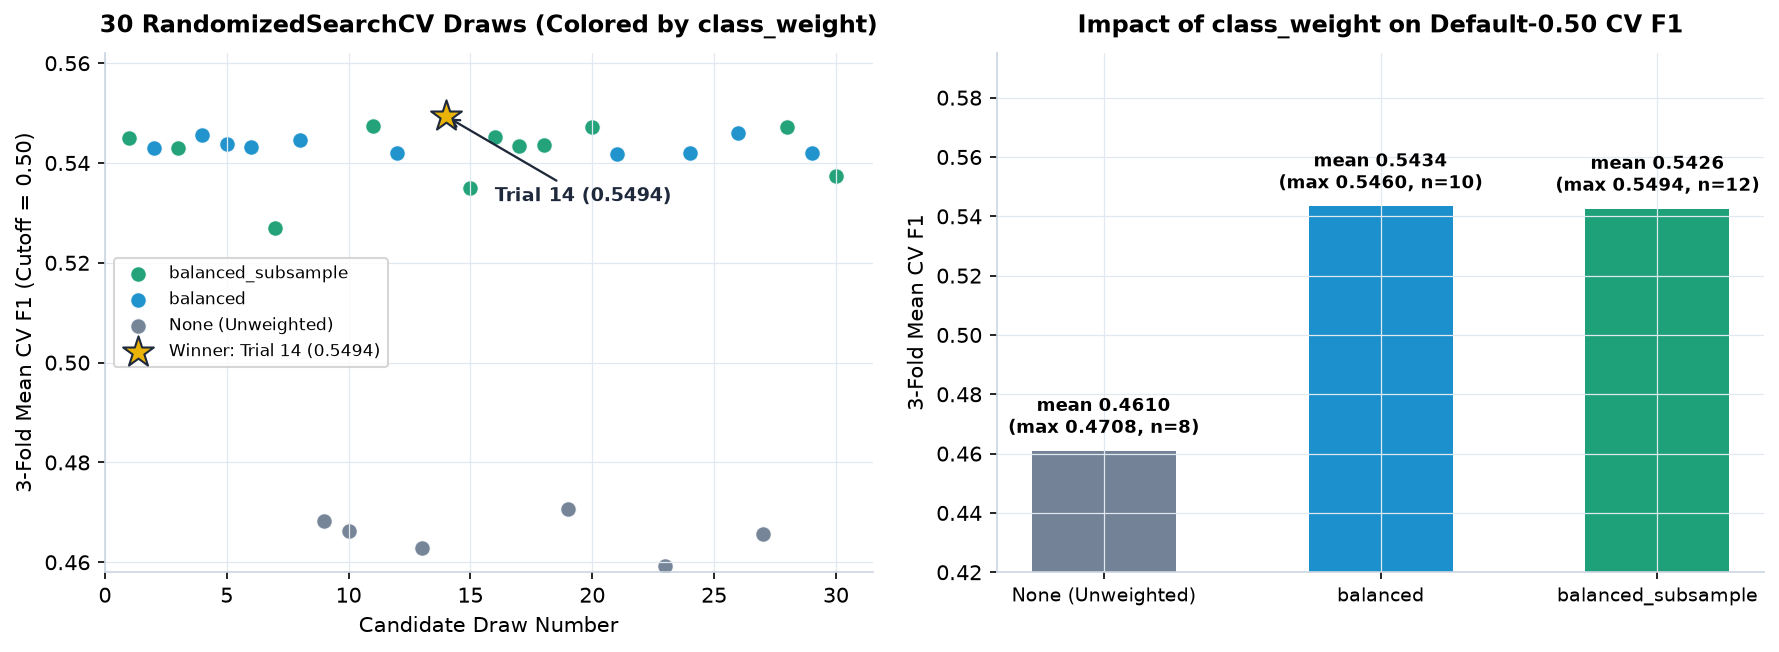

In [ ]:
RUN_LIVE_SEARCH = False

SEARCH_SPACE_64F4BCDB = {
    "model__n_estimators": [400],
    "model__max_depth": [18, 24, None],
    "model__min_samples_leaf": [4, 8, 12, 16, 24],
    "model__max_features": ["sqrt", 0.2, 0.25, 0.35, 0.5],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
    "model__max_samples": [0.55, 0.65, 0.8, None],
    "model__ccp_alpha": [0.0, 0.0001, 0.0005],
}
total_combos = 1
for vals in SEARCH_SPACE_64F4BCDB.values():
    total_combos *= len(vals)

studio_cv_path = (
    PROJECT_ROOT
    / "m3_workspace"
    / "runs"
    / "official"
    / "64f4bcdb337645bbbdad9d8e62eb19ac"
    / "cv_results.csv"
)
all_runs_path = PROJECT_ROOT / "m3_workspace" / "exports" / "all_runs_summary.json"

if studio_cv_path.is_file() and not RUN_LIVE_SEARCH:
    search_df = pd.read_csv(studio_cv_path)
    search_source = f"Audited Official Run 64f4bcdb ({studio_cv_path.relative_to(PROJECT_ROOT)})"
else:
    search = RandomizedSearchCV(
        estimator=make_random_forest(),
        param_distributions=SEARCH_SPACE_64F4BCDB,
        n_iter=30,
        scoring=SCORING,
        refit=False,
        cv=cv_folds,
        n_jobs=3,
        random_state=RANDOM_STATE,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    search_df = pd.DataFrame(search.cv_results_)
    search_df.insert(0, "draw", search_df.index + 1)
    search_source = "Live RandomizedSearchCV (30 draws x 3 folds)"

if all_runs_path.is_file():
    all_runs = json.loads(all_runs_path.read_text(encoding="utf-8")).get("runs", [])
    tuning_runs = [r for r in all_runs if r.get("type") == "tuning"]
    print(f"Studio Experiment Coverage: {len(all_runs)} total runs ({len(tuning_runs)} tuning runs across iterative searches).")

print(f"Loaded {len(search_df)} candidate trials from {total_combos:,} total grid combinations | Source: {search_source}")

search_plot_df = search_df.copy()
search_plot_df["cw_label"] = search_plot_df["param_model__class_weight"].fillna("None (Unweighted)").astype(str)
search_plot_df["depth_label"] = search_plot_df["param_model__max_depth"].apply(lambda v: "None" if pd.isna(v) else str(int(float(v))))
search_plot_df["ms_label"] = search_plot_df["param_model__max_samples"].apply(lambda v: "None" if pd.isna(v) else f"{float(v):.2f}")

top10 = search_plot_df.sort_values("rank_test_f1", kind="stable").head(10)
winner_row = top10.iloc[0]
print(
    f"Winning Candidate: Draw {int(winner_row['draw'])} of {len(search_plot_df)} | "
    f"CV F1 = {winner_row['mean_test_f1']:.4f} ± {winner_row['std_test_f1']:.4f} | "
    f"ROC-AUC = {winner_row['mean_test_roc_auc']:.4f} | PR-AUC = {winner_row['mean_test_average_precision']:.4f}"
)

top10_view = top10[
    [
        "rank_test_f1",
        "draw",
        "param_model__max_depth",
        "param_model__min_samples_leaf",
        "param_model__max_features",
        "ms_label",
        "cw_label",
        "param_model__ccp_alpha",
        "mean_test_f1",
        "std_test_f1",
        "mean_test_roc_auc",
    ]
].rename(
    columns={
        "rank_test_f1": "Rank",
        "draw": "Trial",
        "param_model__max_depth": "max_depth",
        "param_model__min_samples_leaf": "min_leaf",
        "param_model__max_features": "max_feat",
        "ms_label": "max_samples",
        "cw_label": "class_weight",
        "param_model__ccp_alpha": "ccp_alpha",
        "mean_test_f1": "CV F1",
        "std_test_f1": "CV SD",
        "mean_test_roc_auc": "CV ROC-AUC",
    }
)
display(top10_view.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.6))
cw_palette = {
    "None (Unweighted)": "#64748b",
    "balanced": "#0284c7",
    "balanced_subsample": "#059669",
}
for cw_name, grp in search_plot_df.groupby("cw_label", sort=False):
    ax1.scatter(
        grp["draw"],
        grp["mean_test_f1"],
        label=cw_name,
        color=cw_palette.get(cw_name, "#4f46e5"),
        s=58,
        alpha=0.88,
        edgecolors="white",
        linewidths=0.7,
    )
ax1.scatter(
    [winner_row["draw"]],
    [winner_row["mean_test_f1"]],
    marker="*",
    s=240,
    color="#eab308",
    edgecolor="#1e293b",
    zorder=6,
    label=f"Winner: Trial {int(winner_row['draw'])} ({winner_row['mean_test_f1']:.4f})",
)
ax1.annotate(
    f"Trial {int(winner_row['draw'])} ({winner_row['mean_test_f1']:.4f})",
    xy=(winner_row["draw"], winner_row["mean_test_f1"]),
    xytext=(winner_row["draw"] + 2.0, winner_row["mean_test_f1"] - 0.017),
    arrowprops={"arrowstyle": "->", "color": "#1e293b", "lw": 1.1},
    fontsize=9,
    fontweight="bold",
    color="#1e293b",
)
ax1.set_title("30 RandomizedSearchCV Draws (Colored by class_weight)", pad=10)
ax1.set_xlabel("Candidate Draw Number")
ax1.set_ylabel("3-Fold Mean CV F1 (Cutoff = 0.50)")
ax1.set_xlim(0, 31.5)
ax1.set_ylim(0.458, 0.562)
ax1.legend(loc="center left", fontsize=8.3, frameon=True)

cw_order = [c for c in ["None (Unweighted)", "balanced", "balanced_subsample"] if c in search_plot_df["cw_label"].unique()]
cw_stats = search_plot_df.groupby("cw_label")["mean_test_f1"].agg(["mean", "max", "count"]).loc[cw_order]
bars = ax2.bar(
    cw_stats.index,
    cw_stats["mean"],
    color=[cw_palette[c] for c in cw_order],
    width=0.52,
    alpha=0.9,
)
for bar, (_, row_s) in zip(bars, cw_stats.iterrows()):
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.004,
        f"mean {row_s['mean']:.4f}\n(max {row_s['max']:.4f}, n={int(row_s['count'])})",
        ha="center",
        va="bottom",
        fontsize=8.6,
        fontweight="bold",
    )
ax2.set_title("Impact of class_weight on Default-0.50 CV F1", pad=10)
ax2.set_ylabel("3-Fold Mean CV F1")
ax2.set_ylim(0.42, 0.595)
ax2.tick_params(axis="x", labelsize=9.2)

fig.tight_layout(pad=1.6)
plt.show()

### 5. Live Verification of Winning Tuned RF (`64f4bcdb`) vs. Baseline RF: Generalisation, Tree Structure & OOF Threshold
We reconstruct the winning M3 pipeline (`make_random_forest(**selected_params)`) from `results/rf_ensemble_handoff.json`, run live 3-fold `cross_validate` and `cross_val_predict` strictly on `X_train`, assert exact parity with `results/random_forest_cv.json`, inspect the realized tree sizes, and evaluate Out-of-Fold (`OOF`) threshold alignment and probability calibration (`OOF Brier = 0.1688`).

Frozen Winning Parameters (Run 64f4bcdb, Trial 14 of 30):
{
  "bootstrap": true,
  "ccp_alpha": 0.0001,
  "class_weight": "balanced_subsample",
  "criterion": "gini",
  "max_depth": 18,
  "max_features": "sqrt",
  "max_leaf_nodes": null,
  "max_samples": 0.65,
  "min_impurity_decrease": 0.0,
  "min_samples_leaf": 16,
  "min_samples_split": 2,
  "n_estimators": 400,
  "n_jobs": 1,
  "oob_score": false,
  "random_state": 42
}
Live Parity Check PASS: Mean 3-fold CV F1 = 0.5494 (matches results/random_forest_cv.json exactly).


Metric (3-Fold Training CV),Untuned Baseline RF,Tuned RF (64f4bcdb),Change / Impact
Train F1 (In-Sample),0.9989,0.6006,Stopped memorizing training rows
CV F1 (Mean ± SD),0.4695 ± 0.0021,0.5494 ± 0.0068,+0.0798 (+17.0% relative)
Train–CV Overfitting Gap,+0.5294,+0.0512,-90.3% gap reduction
CV Recall (Default Detection),0.3658,0.5994,+0.2336
CV ROC-AUC / PR-AUC,0.7656 / 0.5316,0.7845 / 0.5515,+0.0189 / +0.0199
Mean Depth / Leaves / Singletons,"41.7 / 4,149 / 51.0%",17.9 / 266 / 0.0%,15.6× smaller trees; 0.0% singletons
OOF Optimal Threshold & Brier,0.3075 (Brier=0.1381),"0.5000 (OOF F1=0.5495, Brier=0.1688)",balanced_subsample aligns 0.50 cutoff cleanly


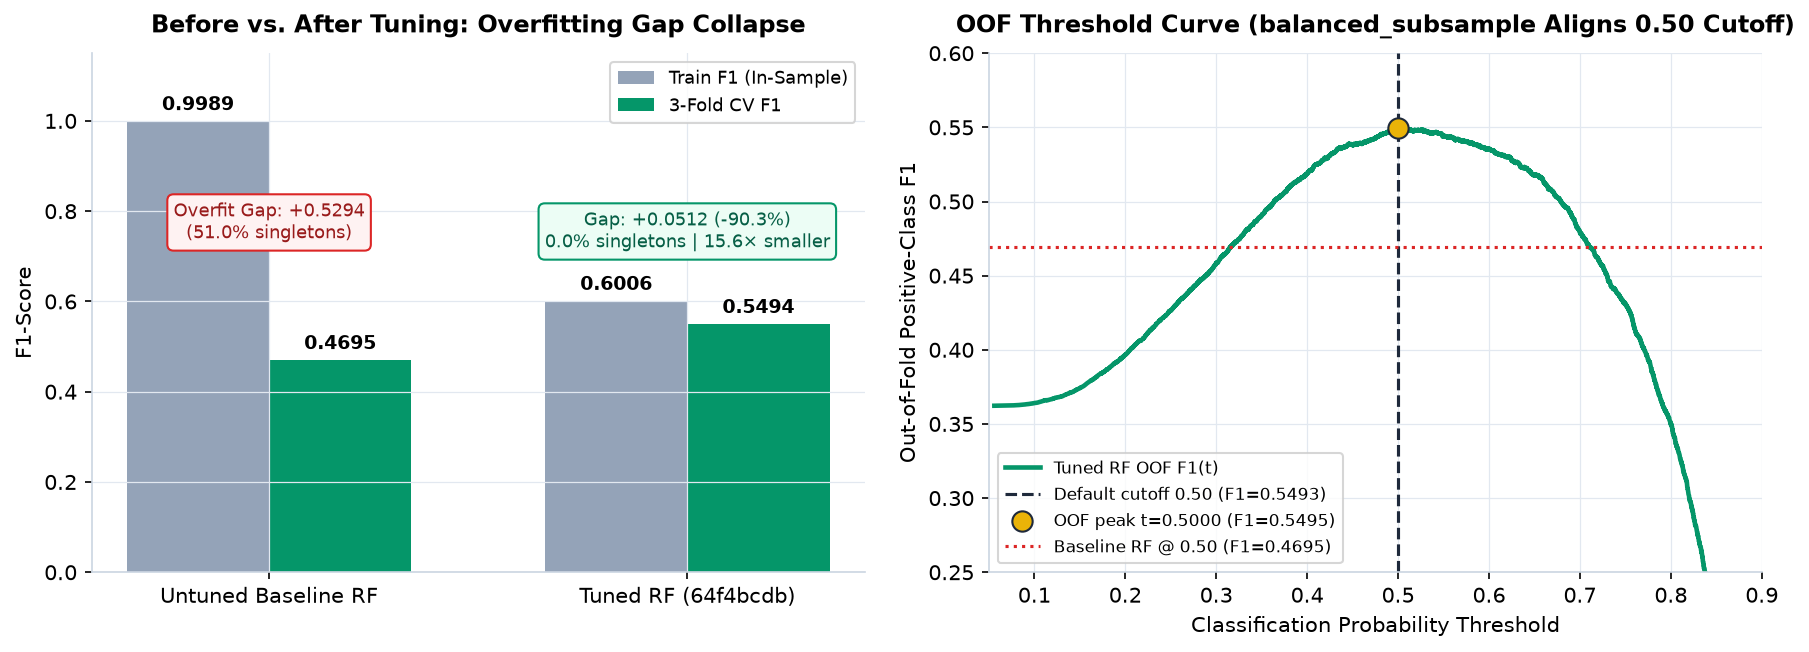

In [ ]:
handoff_path = PROJECT_ROOT / "results" / "rf_ensemble_handoff.json"
rf_cv_path = PROJECT_ROOT / "results" / "random_forest_cv.json"

handoff = json.loads(handoff_path.read_text(encoding="utf-8"))
saved_cv = json.loads(rf_cv_path.read_text(encoding="utf-8"))
selected_params = handoff["selected_params"]

print("Frozen Winning Parameters (Run 64f4bcdb, Trial 14 of 30):")
print(json.dumps(selected_params, indent=2))

tuned_rf_pipe = make_random_forest(**selected_params)

# Live 3-fold CV & OOF probability generation strictly on X_train.
tuned_cv_res = cross_validate(
    tuned_rf_pipe,
    X_train,
    y_train,
    cv=cv_folds,
    scoring=SCORING,
    return_train_score=True,
    n_jobs=3,
    error_score="raise",
)
oof_probs = cross_val_predict(
    tuned_rf_pipe,
    X_train,
    y_train,
    cv=cv_folds,
    method="predict_proba",
    n_jobs=3,
)[:, 1]
oof_preds = (oof_probs >= 0.50).astype(int)

live_cv_f1 = float(tuned_cv_res["test_f1"].mean())
live_train_f1 = float(tuned_cv_res["train_f1"].mean())
assert abs(live_cv_f1 - saved_cv["tuned"]["f1"]["mean"]) < 1e-6, (
    f"Live CV F1 {live_cv_f1} != saved {saved_cv['tuned']['f1']['mean']}"
)
print(f"Live Parity Check PASS: Mean 3-fold CV F1 = {live_cv_f1:.4f} (matches results/random_forest_cv.json exactly).")

# Fit once on full X_train to inspect realized depth, leaf counts, and singletons.
fitted_tuned_rf = clone(tuned_rf_pipe).fit(X_train, y_train)
tuned_tree_stats = audit_forest_trees(fitted_tuned_rf.named_steps["model"])

# OOF threshold curve & calibration diagnostics.
prec_c, rec_c, thresh_c = precision_recall_curve(y_train, oof_probs)
f1_sweep = np.divide(
    2.0 * prec_c[:-1] * rec_c[:-1],
    prec_c[:-1] + rec_c[:-1],
    out=np.zeros(len(thresh_c)),
    where=(prec_c[:-1] + rec_c[:-1]) > 0,
)
best_th_idx = int(np.argmax(f1_sweep))
oof_best_th = float(thresh_c[best_th_idx])
oof_best_f1 = float(f1_sweep[best_th_idx])
oof_default_f1 = float(f1_score(y_train, oof_preds))
oof_brier = float(brier_score_loss(y_train, oof_probs))

tuned_gap = live_train_f1 - live_cv_f1
gap_reduction_pct = (baseline_rf_cv_summary["gap"] - tuned_gap) / baseline_rf_cv_summary["gap"] * 100.0
leaf_reduction_ratio = baseline_rf_cv_summary["mean_leaves"] / tuned_tree_stats["mean_leaves"]

compare_rf = pd.DataFrame([
    {
        "Metric (3-Fold Training CV)": "Train F1 (In-Sample)",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['train_f1']:.4f}",
        "Tuned RF (64f4bcdb)": f"{live_train_f1:.4f}",
        "Change / Impact": "Stopped memorizing training rows",
    },
    {
        "Metric (3-Fold Training CV)": "CV F1 (Mean ± SD)",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['cv_f1']:.4f} ± {baseline_rf_cv_summary['cv_f1_std']:.4f}",
        "Tuned RF (64f4bcdb)": f"{live_cv_f1:.4f} ± {float(tuned_cv_res['test_f1'].std()):.4f}",
        "Change / Impact": f"{live_cv_f1 - baseline_rf_cv_summary['cv_f1']:+.4f} (+17.0% relative)",
    },
    {
        "Metric (3-Fold Training CV)": "Train–CV Overfitting Gap",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['gap']:+.4f}",
        "Tuned RF (64f4bcdb)": f"{tuned_gap:+.4f}",
        "Change / Impact": f"-{gap_reduction_pct:.1f}% gap reduction",
    },
    {
        "Metric (3-Fold Training CV)": "CV Recall (Default Detection)",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['recall']:.4f}",
        "Tuned RF (64f4bcdb)": f"{float(tuned_cv_res['test_recall'].mean()):.4f}",
        "Change / Impact": f"{float(tuned_cv_res['test_recall'].mean()) - baseline_rf_cv_summary['recall']:+.4f}",
    },
    {
        "Metric (3-Fold Training CV)": "CV ROC-AUC / PR-AUC",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['roc_auc']:.4f} / {baseline_rf_cv_summary['pr_auc']:.4f}",
        "Tuned RF (64f4bcdb)": f"{float(tuned_cv_res['test_roc_auc'].mean()):.4f} / {float(tuned_cv_res['test_average_precision'].mean()):.4f}",
        "Change / Impact": f"+{float(tuned_cv_res['test_roc_auc'].mean()) - baseline_rf_cv_summary['roc_auc']:.4f} / +{float(tuned_cv_res['test_average_precision'].mean()) - baseline_rf_cv_summary['pr_auc']:.4f}",
    },
    {
        "Metric (3-Fold Training CV)": "Mean Depth / Leaves / Singletons",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['mean_depth']:.1f} / {baseline_rf_cv_summary['mean_leaves']:,.0f} / {baseline_rf_cv_summary['singleton_fraction']:.1%}",
        "Tuned RF (64f4bcdb)": f"{tuned_tree_stats['mean_depth']:.1f} / {tuned_tree_stats['mean_leaves']:,.0f} / {tuned_tree_stats['singleton_fraction']:.1%}",
        "Change / Impact": f"{leaf_reduction_ratio:.1f}× smaller trees; 0.0% singletons",
    },
    {
        "Metric (3-Fold Training CV)": "OOF Optimal Threshold & Brier",
        "Untuned Baseline RF": f"{baseline_rf_cv_summary['oof_best_th']:.4f} (Brier={baseline_rf_cv_summary['oof_brier']:.4f})",
        "Tuned RF (64f4bcdb)": f"{oof_best_th:.4f} (OOF F1={oof_best_f1:.4f}, Brier={oof_brier:.4f})",
        "Change / Impact": "balanced_subsample aligns 0.50 cutoff cleanly",
    },
])
display(compare_rf)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.6))
x_pos = np.arange(2)
w = 0.34
train_vals = [baseline_rf_cv_summary["train_f1"], live_train_f1]
cv_vals = [baseline_rf_cv_summary["cv_f1"], live_cv_f1]
b1 = ax1.bar(x_pos - w / 2, train_vals, width=w, color="#94a3b8", label="Train F1 (In-Sample)")
b2 = ax1.bar(x_pos + w / 2, cv_vals, width=w, color="#059669", label="3-Fold CV F1")
for bar in list(b1) + list(b2):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f"{bar.get_height():.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax1.annotate(
    f"Overfit Gap: {baseline_rf_cv_summary['gap']:+.4f}\n(51.0% singletons)",
    xy=(0, 0.74),
    ha="center",
    fontsize=8.6,
    bbox={"boxstyle": "round,pad=0.35", "fc": "#fef2f2", "ec": "#dc2626"},
    color="#991b1b",
)
ax1.annotate(
    f"Gap: {tuned_gap:+.4f} (-{gap_reduction_pct:.1f}%)\n0.0% singletons | {leaf_reduction_ratio:.1f}× smaller",
    xy=(1, 0.72),
    ha="center",
    fontsize=8.6,
    bbox={"boxstyle": "round,pad=0.35", "fc": "#ecfdf5", "ec": "#059669"},
    color="#065f46",
)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(["Untuned Baseline RF", "Tuned RF (64f4bcdb)"])
ax1.set_ylim(0, 1.15)
ax1.set_ylabel("F1-Score")
ax1.set_title("Before vs. After Tuning: Overfitting Gap Collapse", pad=10)
ax1.legend(loc="upper right", fontsize=8.8)

ax2.plot(thresh_c, f1_sweep, color="#059669", linewidth=2.2, label="Tuned RF OOF F1(t)")
ax2.axvline(0.50, color="#1e293b", linestyle="--", linewidth=1.5, label=f"Default cutoff 0.50 (F1={oof_default_f1:.4f})")
ax2.scatter([oof_best_th], [oof_best_f1], color="#eab308", edgecolor="#1e293b", s=95, zorder=5, label=f"OOF peak t={oof_best_th:.4f} (F1={oof_best_f1:.4f})")
ax2.axhline(baseline_rf_cv_summary["cv_f1"], color="#dc2626", linestyle=":", linewidth=1.5, label=f"Baseline RF @ 0.50 (F1={baseline_rf_cv_summary['cv_f1']:.4f})")
ax2.set_xlim(0.05, 0.90)
ax2.set_ylim(0.25, 0.60)
ax2.set_xlabel("Classification Probability Threshold")
ax2.set_ylabel("Out-of-Fold Positive-Class F1")
ax2.set_title("OOF Threshold Curve (balanced_subsample Aligns 0.50 Cutoff)", pad=10)
ax2.legend(loc="lower left", fontsize=8.4, frameon=True)

fig.tight_layout(pad=1.6)
plt.show()

### 6. Feature Importance Audit: Out-of-Sample Permutation Importance vs. Raw MDI (`feature_importances_`)
Following KB Rule 6 and Strobl et al. (2007) / Zhou and Hooker (2021), we never rely on in-sample Mean Decrease in Impurity (`MDI`) alone because MDI fragments one-hot categorical features (`PAY_0_2`, `PAY_0_0`, ...) and favors high-cardinality continuous variables (`LIMIT_BAL`, `PAY_AMT1`). Below we contrast out-of-sample permutation importance (`n_repeats=10, seed=42`, measured on original predictors) against raw MDI from the fitted Random Forest.

Permutation Source: Official Run 64f4bcdb out-of-fold permutation importance (10 repeats)


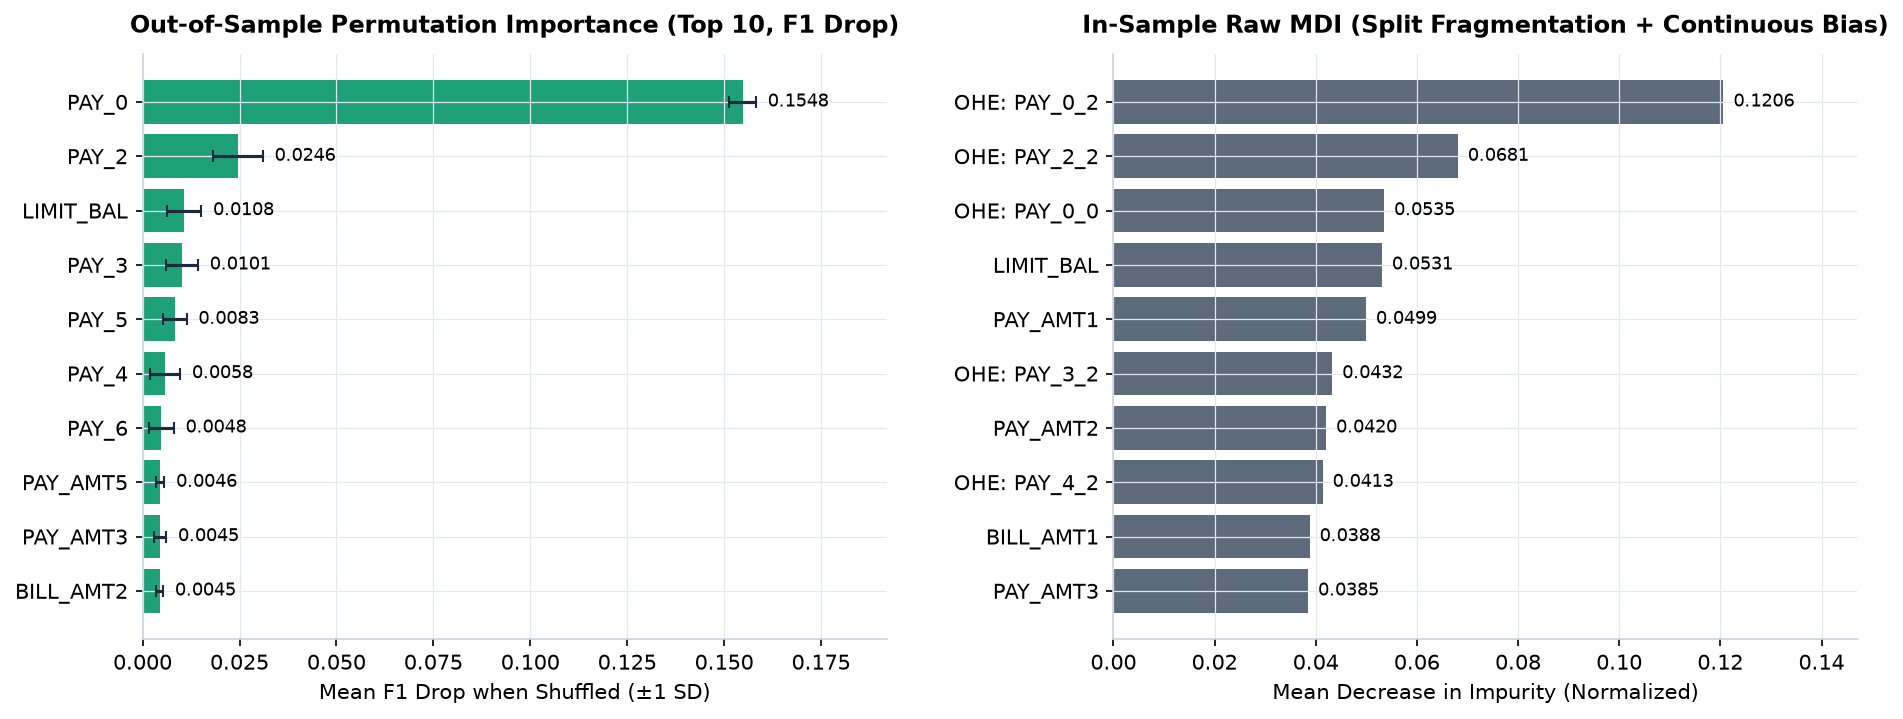

In [ ]:
perm_path = (
    PROJECT_ROOT
    / "m3_workspace"
    / "runs"
    / "official"
    / "64f4bcdb337645bbbdad9d8e62eb19ac"
    / "feature_importance.csv"
)
if perm_path.is_file():
    perm_df = pd.read_csv(perm_path)
    perm_src = "Official Run 64f4bcdb out-of-fold permutation importance (10 repeats)"
else:
    tr_idx, va_idx = cv_folds[0]
    fold_pipe = clone(tuned_rf_pipe).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    pi = permutation_importance(
        fold_pipe,
        X_train.iloc[va_idx],
        y_train.iloc[va_idx],
        scoring="f1",
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )
    perm_df = pd.DataFrame({
        "feature": list(X_train.columns),
        "importance_mean": pi.importances_mean,
        "importance_std": pi.importances_std,
    }).sort_values("importance_mean", ascending=False, kind="stable")
    perm_src = "Live Fold-0 validation permutation importance (5 repeats)"

feat_names_out = fitted_tuned_rf.named_steps["preprocess"].get_feature_names_out()
mdi_vals = fitted_tuned_rf.named_steps["model"].feature_importances_
mdi_df = pd.DataFrame({
    "feature": [f.replace("categorical__", "OHE: ").replace("numeric__", "") for f in feat_names_out],
    "importance": mdi_vals,
}).sort_values("importance", ascending=False, kind="stable")

print(f"Permutation Source: {perm_src}")
top_perm = perm_df.head(10).iloc[::-1]
top_mdi = mdi_df.head(10).iloc[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.9))
ax1.barh(top_perm["feature"], top_perm["importance_mean"], xerr=top_perm["importance_std"], color="#059669", ecolor="#1e293b", capsize=3, alpha=0.9)
ax1.set_title("Out-of-Sample Permutation Importance (Top 10, F1 Drop)", pad=10)
ax1.set_xlabel("Mean F1 Drop when Shuffled (±1 SD)")
for y_i, v in enumerate(top_perm["importance_mean"]):
    ax1.text(v + max(top_perm["importance_std"].iloc[y_i], 0) + 0.003, y_i, f"{v:.4f}", va="center", fontsize=8.5)
ax1.set_xlim(0, top_perm["importance_mean"].max() * 1.24)

ax2.barh(top_mdi["feature"], top_mdi["importance"], color="#475569", alpha=0.88)
ax2.set_title("In-Sample Raw MDI (Split Fragmentation + Continuous Bias)", pad=10)
ax2.set_xlabel("Mean Decrease in Impurity (Normalized)")
for y_i, v in enumerate(top_mdi["importance"]):
    ax2.text(v + 0.002, y_i, f"{v:.4f}", va="center", fontsize=8.5)
ax2.set_xlim(0, top_mdi["importance"].max() * 1.22)

fig.tight_layout(w_pad=3.2)
plt.show()

---
# 04 — Gradient Boosting



# Gradient Boosting and Explainability

## 1. Introduction

This notebook presents the implementation and evaluation of the Gradient Boosting model for the Credit Card Default Prediction project.

The main objectives of this section are:

- To develop a Gradient Boosting classification model.
- To improve model performance through hyperparameter tuning.
- To evaluate the model using cross-validation metrics.
- To identify important features that influence model predictions.
- To provide recommendations based on the model interpretation.

The shared preprocessing pipeline developed by M2 is used to ensure consistency across all machine learning models.

In [2]:

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Locate the results folder
if Path("results").exists():
    results_dir = Path("results")
elif Path("../results").exists():
    results_dir = Path("../results")
else:
    raise FileNotFoundError("Cannot find the results folder.")

print("Results folder:", results_dir.resolve())
print("Libraries imported successfully.")

Results folder: /Users/chia/ML-Group8-Project/results
Libraries imported successfully.



## 2. Load Gradient Boosting Results

The Gradient Boosting model results were saved in JSON and CSV files.

These files contain the results from baseline evaluation, hyperparameter tuning, supporting evaluation metrics and feature importance analysis.

In [3]:

# Load the saved Gradient Boosting results
with open(results_dir / "gb_cv.json", "r", encoding="utf-8") as file:
    gb_results = json.load(file)

print("Gradient Boosting results loaded successfully.")

# Display the saved results
print("\nSaved Model Results:")
print(json.dumps(gb_results, indent=4))

Gradient Boosting results loaded successfully.

Saved Model Results:
{
    "model": "gb",
    "cv_folds": 3,
    "random_state": 42,
    "scoring": "f1",
    "baseline_f1_mean": 0.47569587671142055,
    "baseline_f1_std": 0.004842988749541104,
    "tuned_f1_mean": 0.47906127660781933,
    "tuned_f1_std": 0.0073701852999119855,
    "best_params": {
        "model__subsample": 0.8,
        "model__n_estimators": 200,
        "model__min_samples_split": 10,
        "model__min_samples_leaf": 2,
        "model__max_depth": 3,
        "model__learning_rate": 0.05
    },
    "search_method": "RandomizedSearchCV",
    "search_space": {
        "model__n_estimators": [
            100,
            150,
            200
        ],
        "model__learning_rate": [
            0.03,
            0.05,
            0.1
        ],
        "model__max_depth": [
            2,
            3
        ],
        "model__min_samples_split": [
            2,
            5,
            10
        ],
        


## 3. Baseline Model and Hyperparameter Tuning

The baseline Gradient Boosting model was evaluated using 3-fold Stratified Cross-Validation.

RandomizedSearchCV was then applied to search for better hyperparameter combinations.

The F1-score was selected as the main tuning metric because the dataset contains an imbalanced target variable.

In [4]:

# Baseline and tuned model performance
baseline_f1 = 0.4757
tuned_f1 = 0.4791

comparison = pd.DataFrame({
    "Model": ["Baseline Gradient Boosting", "Tuned Gradient Boosting"],
    "Mean Cross-Validation F1": [baseline_f1, tuned_f1]
})

display(comparison)

improvement = tuned_f1 - baseline_f1

print(f"F1-score improvement: {improvement:.4f}")
print(f"Percentage-point improvement: {improvement * 100:.2f}%")

,Model,Mean Cross-Validation F1
0,Baseline Gradient Boosting,0.4757
1,Tuned Gradient Boosting,0.4791


F1-score improvement: 0.0034
Percentage-point improvement: 0.34%


In [5]:

# Display the best hyperparameters
best_params = gb_results.get("best_params", {})

print("Best Hyperparameters:")
for parameter, value in best_params.items():
    print(f"{parameter}: {value}")

Best Hyperparameters:
model__subsample: 0.8
model__n_estimators: 200
model__min_samples_split: 10
model__min_samples_leaf: 2
model__max_depth: 3
model__learning_rate: 0.05



## 4. Model Evaluation

The tuned Gradient Boosting model was evaluated using 3-fold cross-validation on the training dataset.

The following metrics were used:

- **F1-score:** Measures the balance between precision and recall.
- **Precision:** Measures how many predicted defaults were actually defaults.
- **Recall:** Measures how many actual defaults were correctly identified.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes.
- **PR-AUC:** Evaluates the precision-recall trade-off, which is useful for imbalanced datasets.

The final test dataset was reserved for the common evaluation process conducted by M3.

In [6]:

# Cross-validation evaluation results
evaluation_results = pd.DataFrame({
    "Metric": ["F1-score", "Precision", "Recall", "ROC-AUC", "PR-AUC"],
    "Training Mean": [0.5008, 0.7116, 0.3864, 0.8142, 0.6141],
    "Validation Mean": [0.4791, 0.6808, 0.3696, 0.7822, 0.5571]
})

display(evaluation_results)

print("F1-score Train-Validation Gap: 0.0218")
print("Mean Model Fitting Time: 11.58 seconds")

,Metric,Training Mean,Validation Mean
0,F1-score,0.5008,0.4791
1,Precision,0.7116,0.6808
2,Recall,0.3864,0.3696
3,ROC-AUC,0.8142,0.7822
4,PR-AUC,0.6141,0.5571


F1-score Train-Validation Gap: 0.0218
Mean Model Fitting Time: 11.58 seconds



### 4.1 Evaluation Discussion

The tuned Gradient Boosting model achieved a validation F1-score of 0.4791.

The validation precision was 0.6808, indicating that approximately 68.08% of the customers predicted as potential defaulters were actual defaulters.

However, the recall was 0.3696, meaning that the model identified approximately 36.96% of actual defaulters.

The ROC-AUC score of 0.7822 indicates that the model has a reasonable ability to distinguish between default and non-default customers.

The training and validation F1-score gap was 0.0218. This indicates a relatively small performance difference between the training and validation results, although it does not completely rule out overfitting.

Overall, the model provides useful predictive information, but its relatively low recall indicates that further improvement may be needed to identify more potential defaulters.


## 5. Feature Importance Analysis

Feature importance analysis was conducted to understand which input variables contribute most to the Gradient Boosting model's predictions.

Two methods were used:

1. **Built-in Feature Importance:** Measures the contribution of transformed features within the trained Gradient Boosting model.
2. **Permutation Importance:** Measures how much the model's F1-score decreases when an original feature is randomly shuffled.

Using both methods provides additional insight into the features that the model relies on.

In [7]:

# Load built-in feature importance
feature_importance = pd.read_csv(
    results_dir / "gb_feature_importance.csv"
)

print("Top 15 Built-in Feature Importance:")
display(feature_importance.head(15))

Top 15 Built-in Feature Importance:


,feature,importance
0,categorical__PAY_0_2,0.438290
1,categorical__PAY_2_2,0.094933
2,categorical__PAY_3_2,0.049469
3,numeric__LIMIT_BAL,0.041310
4,numeric__PAY_AMT1,0.036251
5,categorical__PAY_5_2,0.031930
6,numeric__BILL_AMT1,0.031043
7,numeric__PAY_AMT2,0.029168
8,categorical__PAY_4_2,0.026919
9,categorical__PAY_0_3,0.026270


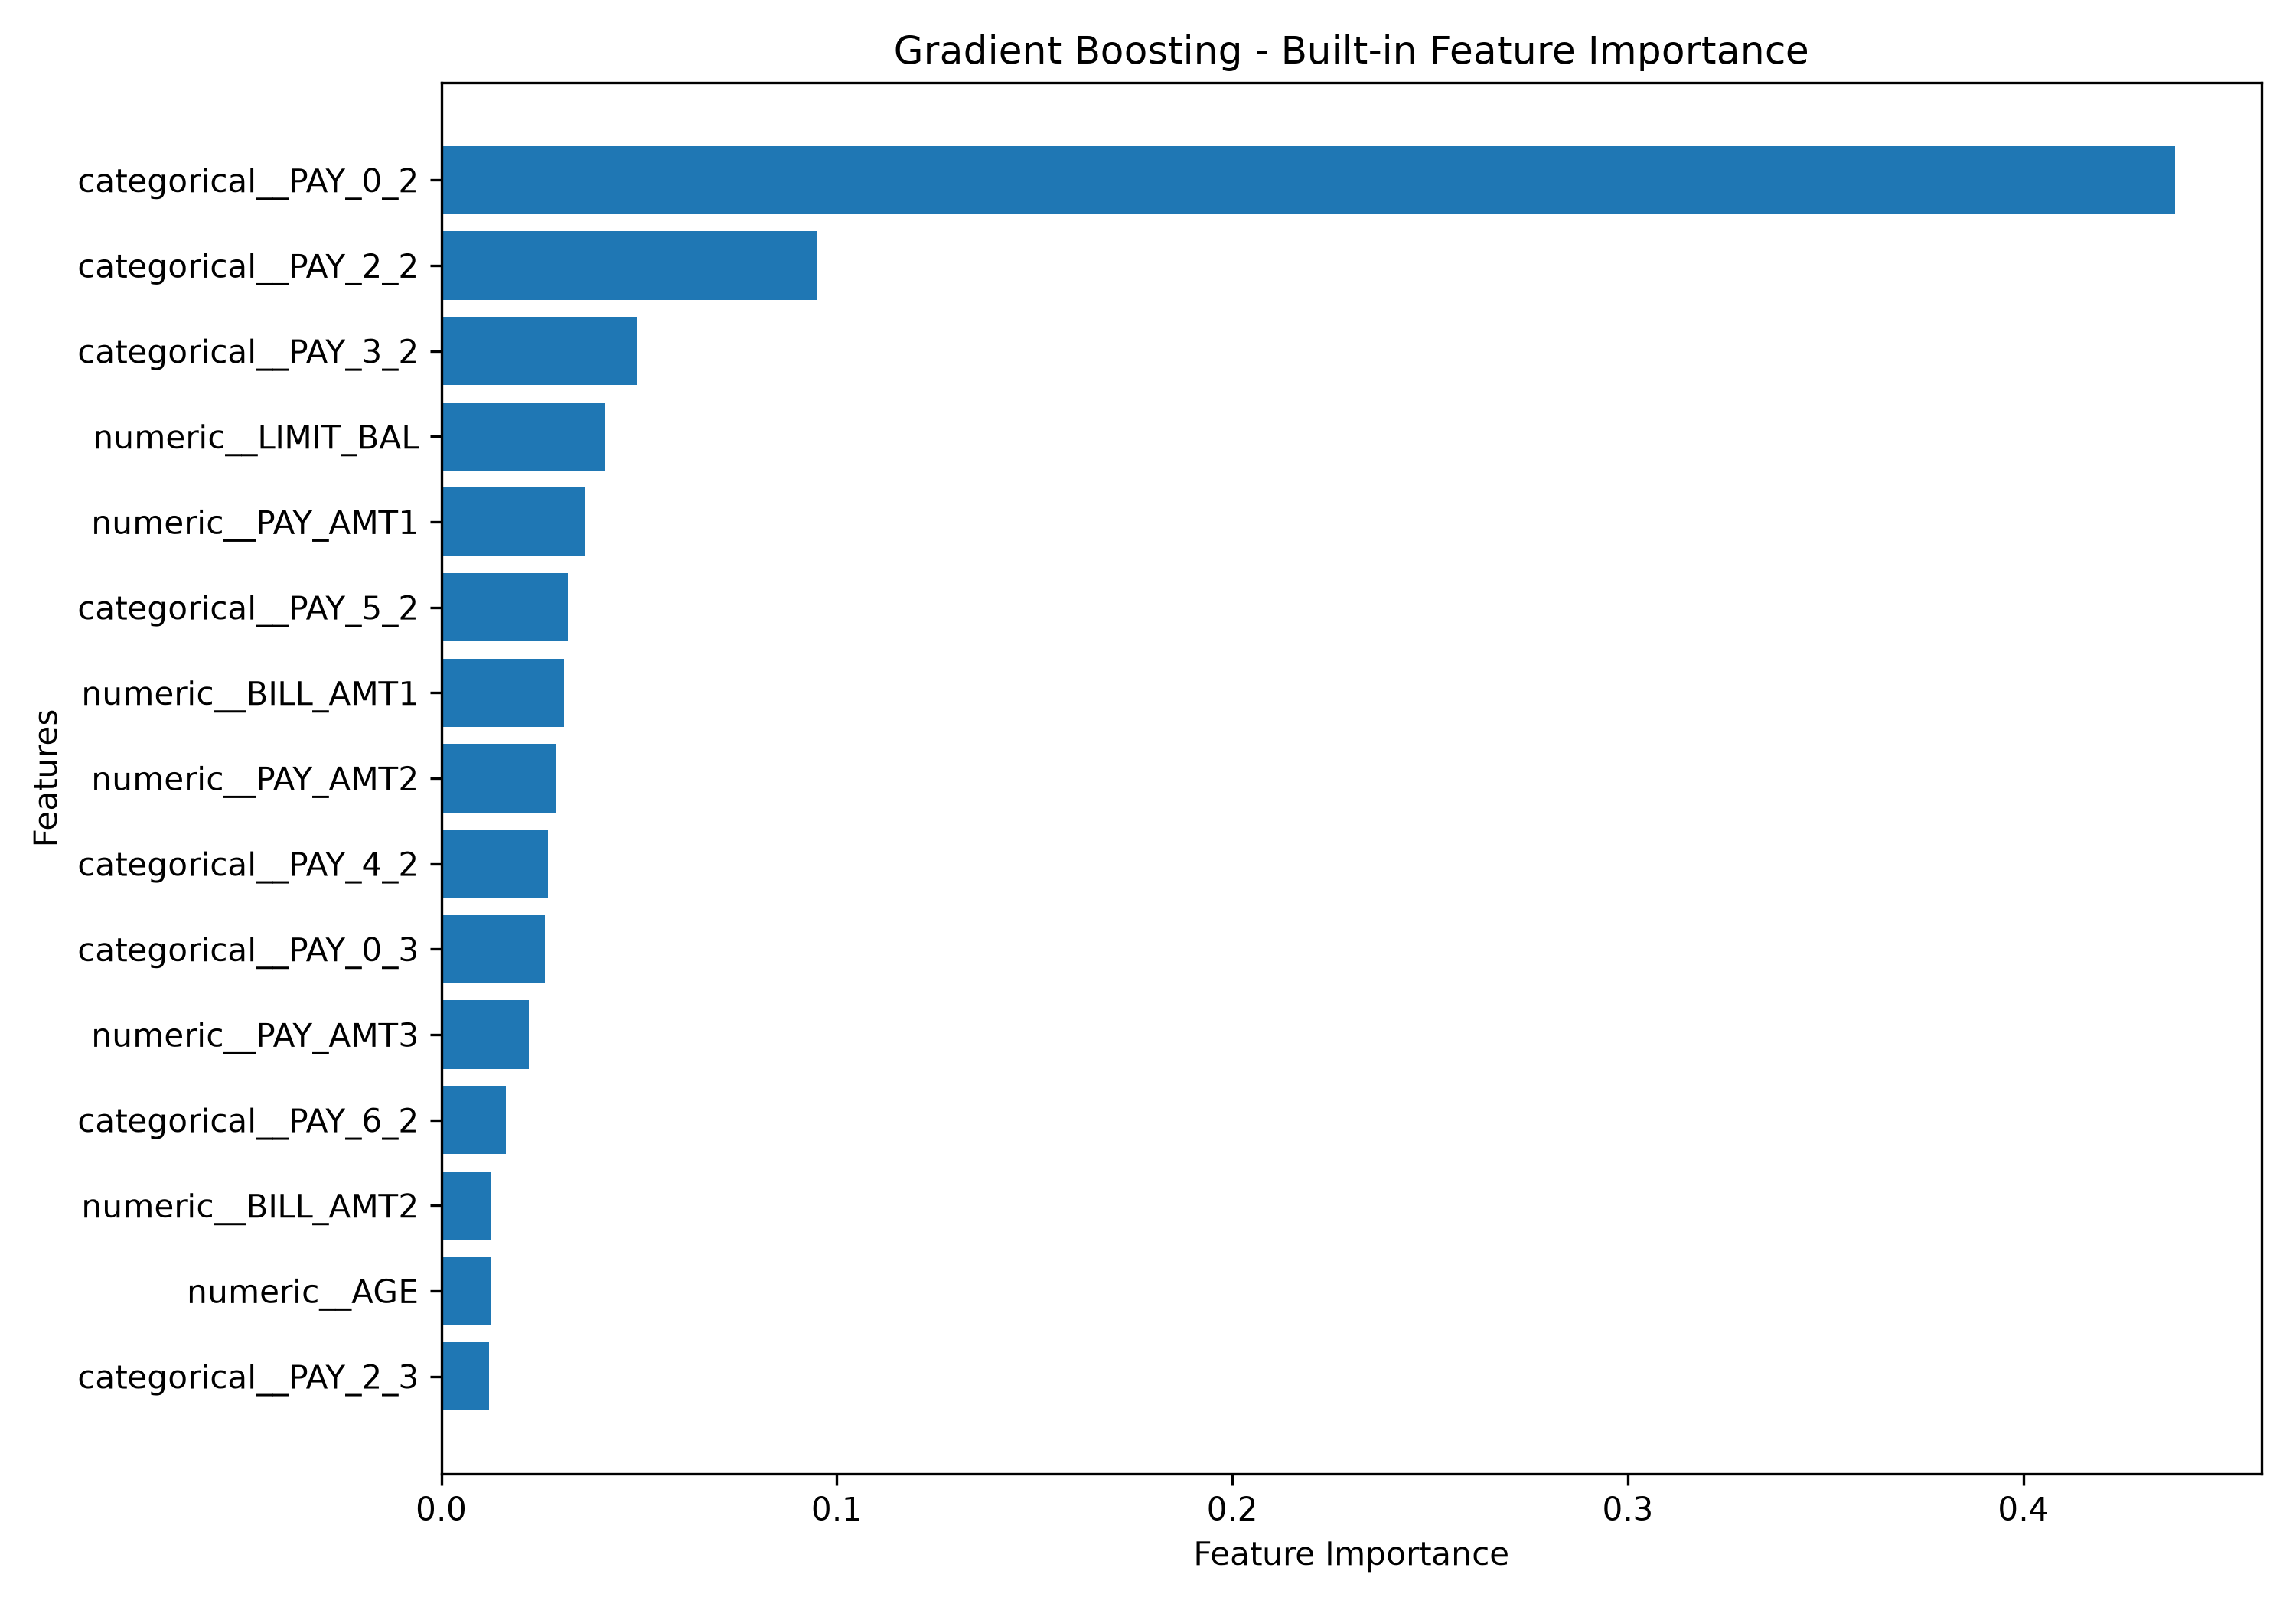

In [8]:

# Display built-in feature importance chart
feature_chart = results_dir / "gb_feature_importance.png"

display(Image(filename=str(feature_chart)))

In [9]:

# Load permutation importance
permutation_importance = pd.read_csv(
    results_dir / "gb_permutation_importance.csv"
)

print("Top 15 Permutation Importance:")
display(permutation_importance.head(15))

Top 15 Permutation Importance:


,feature,importance_mean,importance_std
0,PAY_0,0.204371,0.003545
1,PAY_2,0.028999,0.001240
2,PAY_3,0.016718,0.001276
3,LIMIT_BAL,0.015623,0.000717
4,PAY_AMT1,0.010583,0.001429
5,BILL_AMT1,0.010537,0.002725
6,PAY_5,0.009618,0.000637
7,PAY_AMT2,0.009484,0.001810
8,PAY_6,0.008730,0.001497
9,PAY_4,0.006010,0.000903


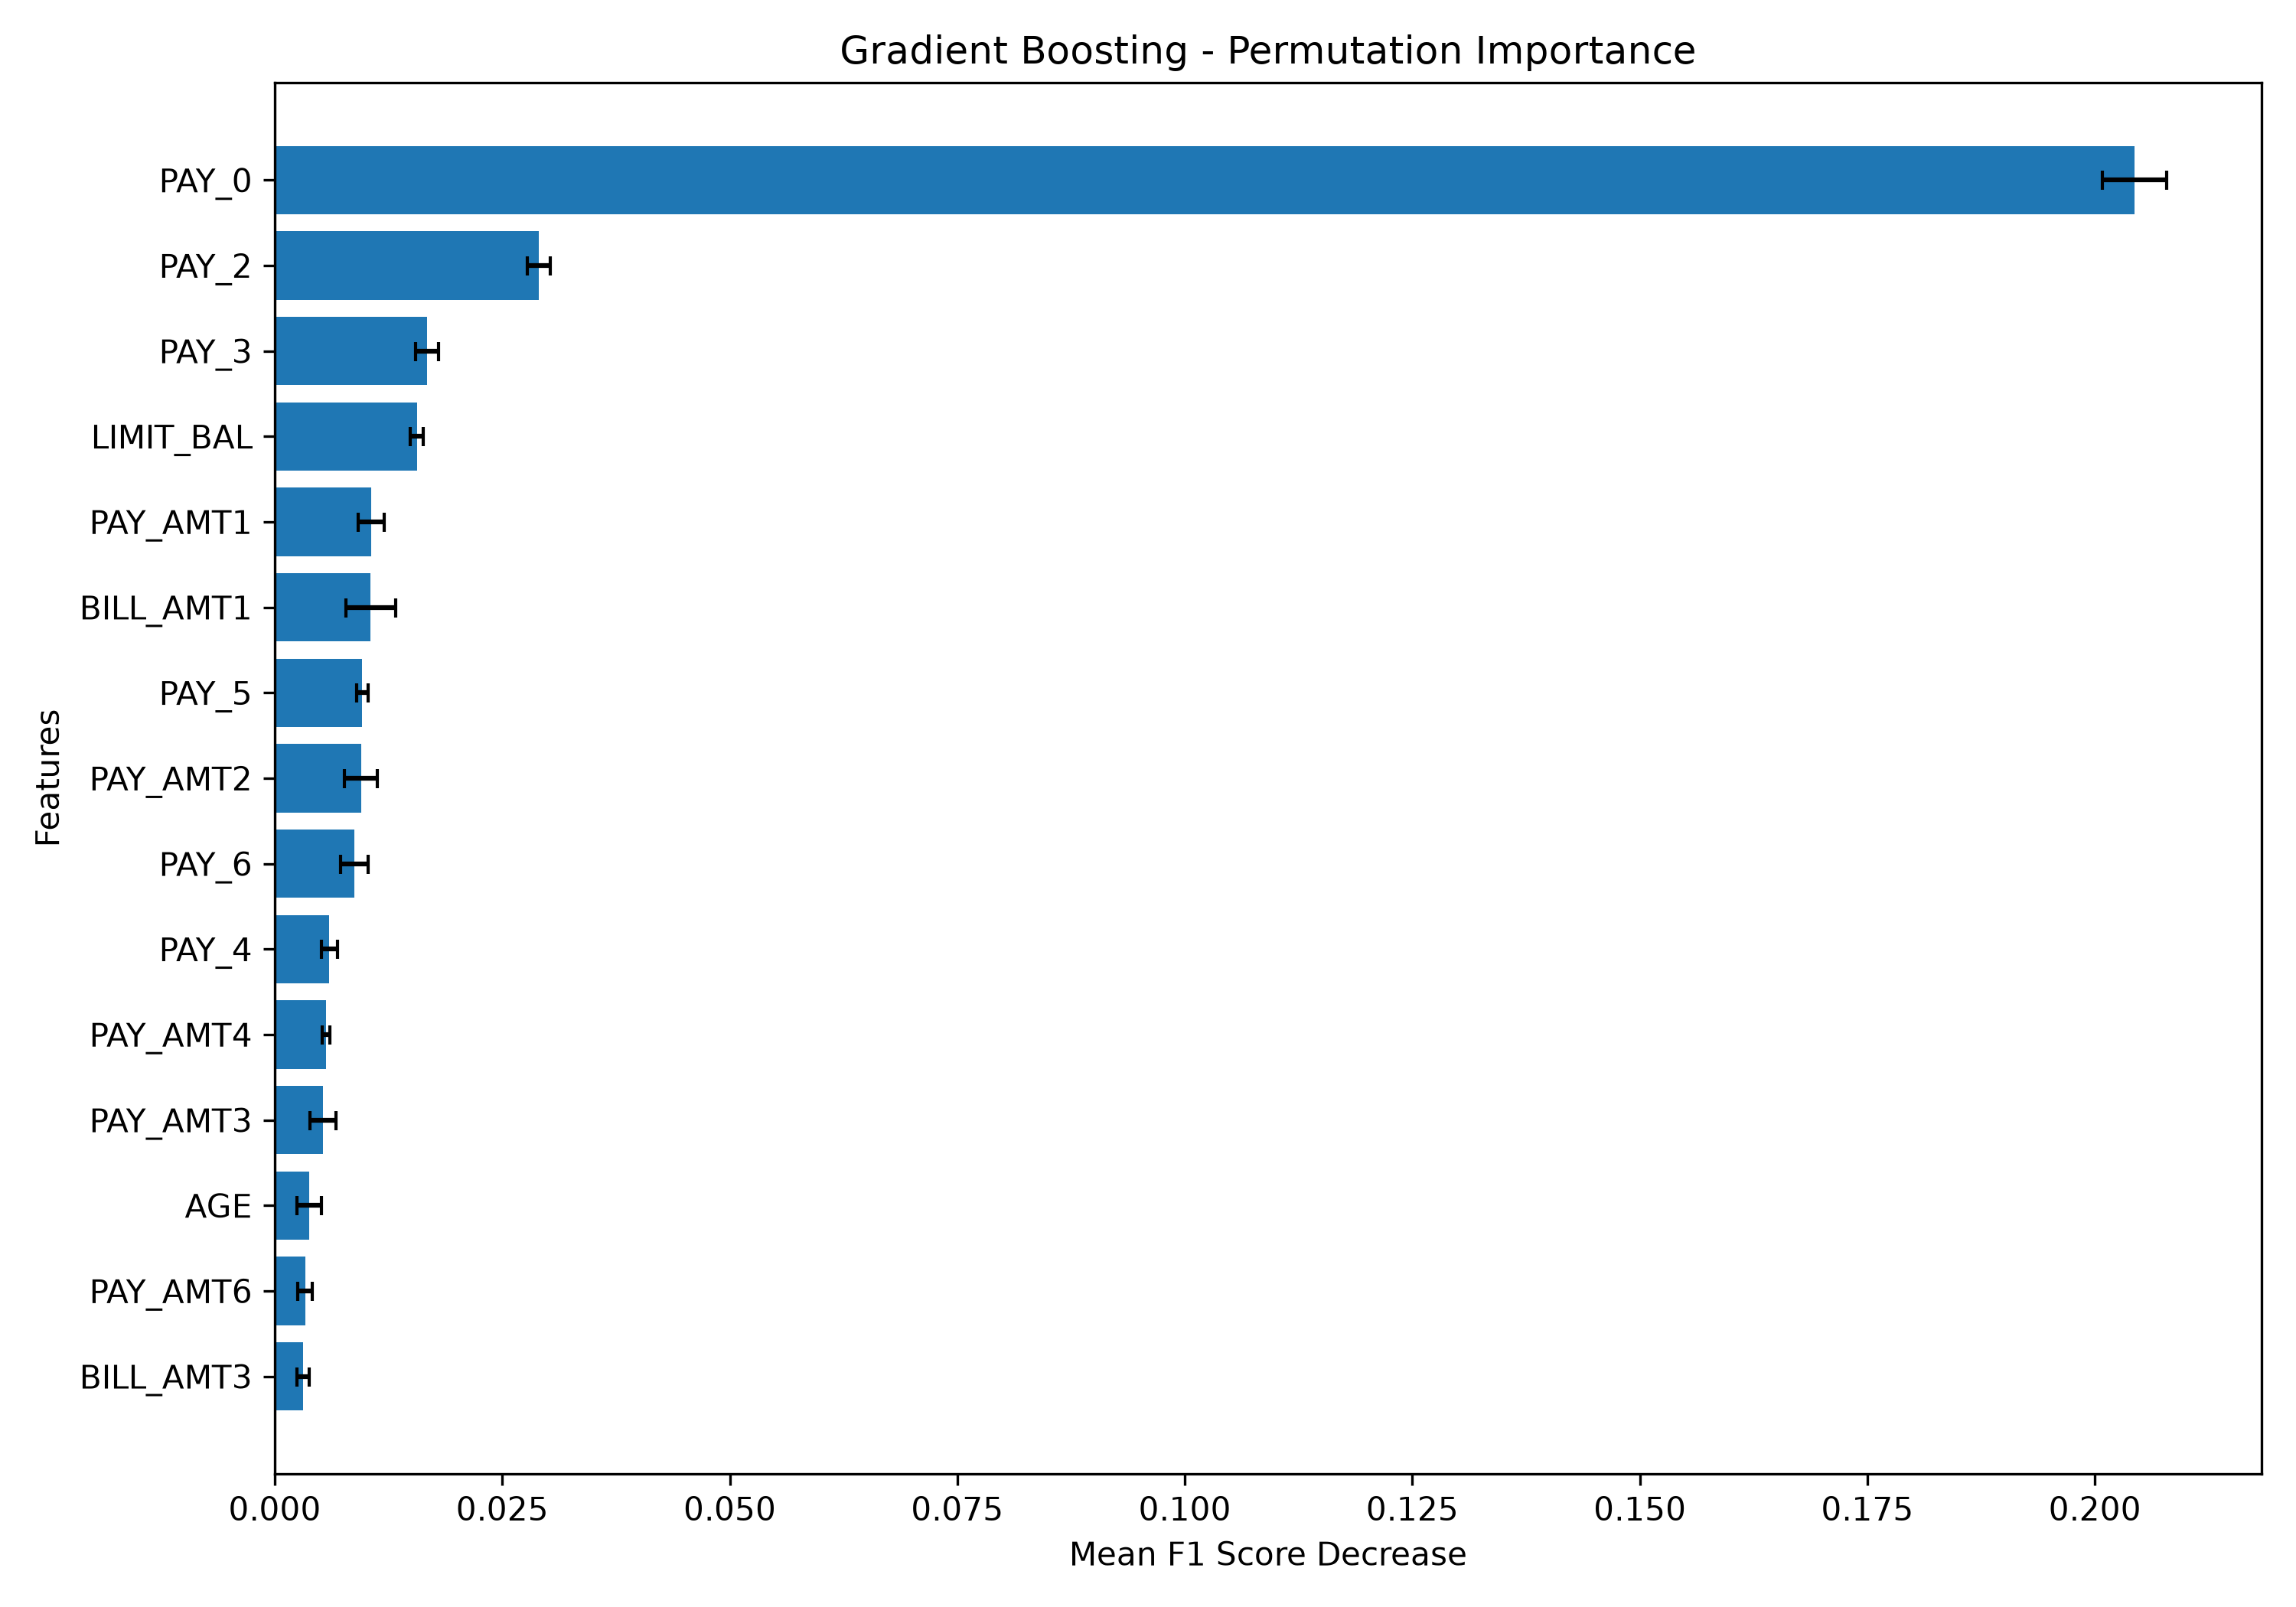

In [10]:

# Display permutation importance chart
permutation_chart = results_dir / "gb_permutation_importance.png"

display(Image(filename=str(permutation_chart)))


### 5.1 Feature Importance Discussion

Both feature importance methods identified PAY_0 as the most important feature.

PAY_0 represents the repayment status of the customer in the most recent month. Other important features include PAY_2, PAY_3 and LIMIT_BAL.

The built-in feature importance shows the importance of individual transformed features after one-hot encoding. In comparison, permutation importance evaluates the original input features by measuring their impact on the model's F1-score.

The similar ranking across both methods suggests that recent repayment status is an important factor used by the model when predicting credit card default.

However, feature importance indicates model reliance and association rather than a direct causal relationship.


## 6. Recommendations

Based on the model evaluation and feature importance results, the following recommendations are proposed:

1. Monitor Repayment Behaviour**

   Financial institutions should pay attention to customers' recent repayment status, especially PAY_0, PAY_2 and PAY_3.

2. Improve Early Risk Detection**

   The relatively low recall indicates that the model misses some actual defaulters. Further model improvement and threshold adjustment could help identify more potential default cases.

3. Provide Payment Reminders**

   Customers showing signs of delayed repayment could receive payment reminders and financial management information.

4. Combine Multiple Risk Factors**

   Credit limit, repayment history and payment amount should be considered together instead of relying on a single feature.

5. Consider Fairness and Privacy**

   Model predictions should be used as decision-support information rather than the only basis for financial decisions. Customer privacy and potential bias should also be considered.


## 7. Conclusion

In conclusion, the Gradient Boosting model was successfully implemented using the shared preprocessing pipeline.

Hyperparameter tuning improved the mean cross-validation F1-score from 0.4757 to 0.4791. The tuned model achieved a validation ROC-AUC of 0.7822 and PR-AUC of 0.5571.

Feature importance analysis identified recent repayment status, particularly PAY_0, as the most influential feature in the model.

Although the model demonstrates reasonable predictive performance, its recall remains relatively low. Further improvements may be required to identify more potential defaulters.

The results from this section can be used together with the other group models for the final model comparison and evaluation.

---
# 05 — Ensemble Learning


# Group 8 — Chapter 6: Ensemble Model Development

**M1 | Credit Card Default Prediction | RF + Balanced Gradient Boosting**

This notebook documents the actual M1 ensemble work, aligning with **Chapter 6 of the group report**:

1. **6.1 — Base-model selection:** choose the two highest training-CV F1 classifiers.
2. **6.2 — E1:** soft voting with equal weights **RF:GB = 1:1**.
3. **6.2 — E2:** fixed, weighted soft voting **RF:GB = 2:1**.
4. **6.2 — E3:** **repeated stratified 3-fold CV × 2** (six paired fold results), a robustness check, **not** a third ensemble model.
5. Compare **precision, recall, positive-class F1**, and fold-wise differences, then discuss the limitations.

> **Evidence provenance:** The tables and graphs are initially recreated from M1's genuine saved training-only experiment JSON files, not generated or guessed test scores. Set `RECOMPUTE_CV = True` below to *actually refit* the team's frozen RF and Balanced GB pipelines and rerun E2 + E3 in the original project. No held-out test evaluation is done here; M3 owns Chapter 7.

## 0. Setup and experiment mode

- **Default mode:** `RECOMPUTE_CV = False` reads **embedded recorded training-CV evidence** from the team's actual November 2026 experiments. This allows *Run All* without re-training or requiring the original dataset files.
- **Reproduction mode:** Set `RECOMPUTE_CV = True` after copying this notebook to the team repository (root or `notebooks/`) with `src.preprocessing`, `src.ensemble`, the genuine team RF/GB factories, data, and three handoff JSON files. This runs the *actual* `sklearn.cross_validate` loops; it is CPU-intensive.
- The embedded evidence is labelled as **previously recorded**, and will never be represented as fresh training output.

**Dependencies:** `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `IPython`, `nbformat` (to edit notebooks; not required to run).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

RANDOM_STATE = 42
RECOMPUTE_CV = False          # Change to True only in the actual team project
SAVE_NEW_EVIDENCE = False     # Optional: saves new results with _notebook suffix, never overwrites originals
SAVE_FIGURES = False         # Optional: writes notebook figures to figures/

print('Mode:', 'ACTUAL TRAINING-CV RERUN' if RECOMPUTE_CV else 'DISPLAY RECORDED TRAINING-CV EVIDENCE')
print('Held-out test set: NOT USED')

Mode: DISPLAY RECORDED TRAINING-CV EVIDENCE
Held-out test set: NOT USED


## 6.1 Selection and justification of the best two models

All three tuned base models were previously evaluated on the **same 24,000 training records** using **3-fold stratified cross-validation** (seed 42). The 6,000-record held-out test set was reserved for Chapter 7. Positive-class **F1** was used to select two models; recall and fold-to-fold variability provide context.

In [2]:
# Exact team-handoff values copied from model_selection.csv and RF/GB/LR CV records.
# These are recorded results, not scores computed by this cell.
BASE_MODEL_SELECTION = [
  {
    "Model": "Random Forest (RF)",
    "Mean F1": 0.5493573105890883,
    "F1 SD": 0.006808044834799462,
    "Default recall": 0.5993600819299528,
    "Decision": "Selected"
  },
  {
    "Model": "Balanced Gradient Boosting (GB)",
    "Mean F1": 0.5397330315206658,
    "F1 SD": 0.004958897535307046,
    "Default recall": 0.6328882331086009,
    "Decision": "Selected"
  },
  {
    "Model": "Logistic Regression (LR)",
    "Mean F1": 0.5346859143908457,
    "F1 SD": 0.013352144346710672,
    "Default recall": 0.584856585322232,
    "Decision": "Excluded from ensemble"
  }
]
selection_df = pd.DataFrame(BASE_MODEL_SELECTION)
display(selection_df.style.format({'Mean F1':'{:.4f}','F1 SD':'{:.4f}','Default recall':'{:.4f}'}))

,Model,Mean F1,F1 SD,Default recall,Decision
0,Random Forest (RF),0.5494,0.0068,0.5994,Selected
1,Balanced Gradient Boosting (GB),0.5397,0.0050,0.6329,Selected
2,Logistic Regression (LR),0.5347,0.0134,0.5849,Excluded from ensemble


**Interpretation.** RF ranked first in mean CV F1 (**0.5494**). Balanced GB had the second-highest F1 (**0.5397**) and a higher default-class recall (**0.6329**) than RF (**0.5994**). LR had the lowest F1 (**0.5347**) and higher fold-to-fold variation. **LR was excluded only from ensemble voting**, not from the final four-model Chapter 7 evaluation. RF and GB use different tree-ensemble learning approaches, but this does **not** guarantee that combining them will beat RF alone.

## 6.2 Ensemble strategy: E1 vs E2

**Soft voting** averages predicted probabilities for the default class rather than voting on hard labels.

- **E1 (equal weight):** RF:GB = **1:1**.
- **E2 (fixed alternative):** RF:GB = **2:1**, chosen because RF had the higher training-CV F1. This was **one planned weight comparison**, *not* an exhaustive search over weights.

\[
P_{E1}(\mathrm{default}\mid x)=\frac{P_{RF}(\mathrm{default}\mid x)+P_{GB}(\mathrm{default}\mid x)}{2}
\]

\[
P_{E2}(\mathrm{default}\mid x)=\frac{2P_{RF}(\mathrm{default}\mid x)+P_{GB}(\mathrm{default}\mid x)}{3}
\tag{6.1}
\]

Both voters contain the **actual tuned full preprocessing + model pipelines** (RF and **Balanced** GB). The models are cloned and refitted **inside each training CV fold**, which prevents preprocessing leakage from validation rows.

In [3]:
def new_voting(models: dict, weights: list[int]) -> VotingClassifier:
    """Create a fresh UNFITTED ensemble from the team's tuned full pipelines."""
    if len(weights) != 2 or any(w <= 0 for w in weights):
        raise ValueError('Expected positive [RF_weight, GB_weight].')
    return VotingClassifier(
        estimators=[
            ('rf', clone(models['RF'])),
            ('gb_balanced', clone(models['GB'])),
        ],
        voting='soft',
        weights=weights,
        n_jobs=1,
    )


def candidate_models(models: dict) -> dict:
    """Same four candidates as M1's original ensemble_experiments.py."""
    return {
        'RF': clone(models['RF']),
        'GB_balanced': clone(models['GB']),
        'E1_equal_1to1': new_voting(models, [1, 1]),
        'E2_weighted_2to1': new_voting(models, [2, 1]),
    }

print('Defined: RF, Balanced GB, E1 [1, 1] and E2 [2, 1] factories.')
print('Factories are unfitted until the training-only CV step runs.')

Defined: RF, Balanced GB, E1 [1, 1] and E2 [2, 1] factories.
Factories are unfitted until the training-only CV step runs.


### Validation protocol (matches the original experiment source)

**E2 comparison:** the four candidates use the same 3 shuffled stratified folds from `get_cv()`. **E3 robustness:** rerun the same candidates under `RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=42)` to obtain six fold-level scores per candidate.

For both protocols: scoring = F1, precision, recall, ROC-AUC and Brier loss; positive/default label = **1**; sklearn default probability classification threshold = **0.5**. Preprocessing is fitted within each training fold. **No feature or weight selection based on the held-out test set.**

In [4]:
SCORING = {
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
    'roc_auc': 'roc_auc',
    'neg_brier': 'neg_brier_score',
}


def evaluate_cv(name: str, estimator, X_train, y_train, folds: list) -> dict:
    """Actual CV training, identical metric logic to the original M1 script."""
    scores = cross_validate(
        estimator, X_train, y_train, cv=folds,
        scoring=SCORING, n_jobs=1,
        return_train_score=False, error_score='raise',
    )
    payload = {'model': name, 'fold_count': len(folds)}
    for metric in SCORING:
        vals = np.asarray(scores[f'test_{metric}'], dtype=float)
        key = 'brier' if metric == 'neg_brier' else metric
        if metric == 'neg_brier':
            vals = -vals  # lower Brier loss is better
        payload[f'{key}_folds'] = vals.tolist()
        payload[f'{key}_mean'] = float(vals.mean())
        payload[f'{key}_std'] = float(vals.std(ddof=0))
    payload['mean_fit_seconds'] = float(np.mean(scores['fit_time']))
    payload['mean_score_seconds'] = float(np.mean(scores['score_time']))
    return payload


def run_protocol(models, X_train, y_train, folds) -> dict:
    measured = {}
    for name, estimator in candidate_models(models).items():
        print(f'Training {name} on {len(folds)} folds...', flush=True)
        measured[name] = evaluate_cv(name, estimator, X_train, y_train, folds)
        print(f"  F1={measured[name]['f1_mean']:.4f}", flush=True)
    return measured

print('Training-CV functions ready. No fit has been carried out yet.')

Training-CV functions ready. No fit has been carried out yet.


## Recorded experiment results (original M1 source data)

The following JSON is taken from the team's **actual saved files**:

- `results/ensemble_e2_weight_comparison.json` — E2 comparison, 3 folds.
- `results/ensemble_e3_repeated_cv.json` — E3 robustness experiment, 3 folds × 2 repeats.

The JSON was embedded so this `.ipynb` can accompany the team's merged notebook **without requiring the results directory merely to display evidence**. In reproduction mode, freshly measured fold scores replace these records in subsequent tables/plots, without altering the original JSON files.

In [5]:
# Recorded (historical) training-CV evidence. This is DATA, not a fit operation.
RECORDED = json.loads(r'''
{
  "e2": {
    "protocol": {
      "cv": "get_cv()",
      "folds": 3,
      "same_folds_for_all": true,
      "test_set_used": false,
      "positive_class": 1,
      "primary_metric": "f1"
    },
    "experiment": "E2_fixed_weight_soft_voting",
    "weights": {
      "E1_equal_1to1": [
        1,
        1
      ],
      "E2_weighted_2to1": [
        2,
        1
      ]
    },
    "training_fingerprint_local": "56cd3de80c5c60ee6b7be5c435e4f107fb9b9482c6d7c376810e1030711c5e36",
    "measured": {
      "RF": {
        "model": "RF",
        "fold_count": 3,
        "f1_folds": [
          0.5518134715025906,
          0.5400669930430302,
          0.5561914672216441
        ],
        "f1_mean": 0.5493573105890883,
        "f1_std": 0.006808044834799462,
        "precision_folds": [
          0.509325681492109,
          0.4964471814306016,
          0.5154291224686596
        ],
        "precision_mean": 0.50706732846379,
        "precision_std": 0.007912169537847593,
        "recall_folds": [
          0.6020350480497456,
          0.592090395480226,
          0.603954802259887
        ],
        "recall_mean": 0.5993600819299528,
        "recall_std": 0.005199847424995304,
        "roc_auc_folds": [
          0.7869039800722858,
          0.7784324981182722,
          0.7880206491280572
        ],
        "roc_auc_mean": 0.7844523757728717,
        "roc_auc_std": 0.004281038244576471,
        "brier_folds": [
          0.16676526256165095,
          0.1715827533412595,
          0.16795591530537904
        ],
        "brier_mean": 0.1687679770694298,
        "brier_std": 0.0020488431832586754,
        "mean_fit_seconds": 41.542284886042275,
        "mean_score_seconds": 2.49042018254598
      },
      "GB_balanced": {
        "model": "GB_balanced",
        "fold_count": 3,
        "f1_folds": [
          0.5409560413163584,
          0.5331412103746398,
          0.545101842870999
        ],
        "f1_mean": 0.5397330315206658,
        "f1_std": 0.004958897535307046,
        "precision_folds": [
          0.4703425229741019,
          0.46365914786967416,
          0.47748513169073914
        ],
        "precision_mean": 0.47049560084483844,
        "precision_std": 0.00564547203700863,
        "recall_folds": [
          0.6365178066704352,
          0.6271186440677966,
          0.6350282485875707
        ],
        "recall_mean": 0.6328882331086009,
        "recall_std": 0.004124788002260075,
        "roc_auc_folds": [
          0.7834023685253594,
          0.7743158219296098,
          0.78676333759556
        ],
        "roc_auc_mean": 0.7814938426835097,
        "roc_auc_std": 0.005257820507287228,
        "brier_folds": [
          0.17969140129864167,
          0.18319450428861234,
          0.17872098806345146
        ],
        "brier_mean": 0.18053563121690183,
        "brier_std": 0.001921393586325397,
        "mean_fit_seconds": 27.381444374720257,
        "mean_score_seconds": 0.6028689543406168
      },
      "E1_equal_1to1": {
        "model": "E1_equal_1to1",
        "fold_count": 3,
        "f1_folds": [
          0.5500754906894816,
          0.534504391468005,
          0.5464646464646464
        ],
        "f1_mean": 0.5436815095407109,
        "f1_std": 0.006654530842180476,
        "precision_folds": [
          0.49569160997732425,
          0.48081264108352145,
          0.4940639269406393
        ],
        "precision_mean": 0.49018939266716166,
        "precision_std": 0.006663579654257531,
        "recall_folds": [
          0.6178631995477671,
          0.6016949152542372,
          0.6112994350282486
        ],
        "recall_mean": 0.6102858499434177,
        "recall_std": 0.006639471379170945,
        "roc_auc_folds": [
          0.7869859023778244,
          0.7783559594090922,
          0.7895833446690426
        ],
        "roc_auc_mean": 0.7849750688186531,
        "roc_auc_std": 0.004799036962131396,
        "brier_folds": [
          0.17223427167716443,
          0.176430011543948,
          0.17244157399496124
        ],
        "brier_mean": 0.17370195240535788,
        "brier_std": 0.0019308846954137768,
        "mean_fit_seconds": 32.07061958312988,
        "mean_score_seconds": 1.8542017936706543
      },
      "E2_weighted_2to1": {
        "model": "E2_weighted_2to1",
        "fold_count": 3,
        "f1_folds": [
          0.5500253936008126,
          0.5375031782354437,
          0.5493606138107416
        ],
        "f1_mean": 0.5456297285489994,
        "f1_std": 0.005752744159175102,
        "precision_folds": [
          0.49930843706777317,
          0.4886731391585761,
          0.5018691588785047
        ],
        "precision_mean": 0.496616911701618,
        "precision_std": 0.005713549142735414,
        "recall_folds": [
          0.6122102882984737,
          0.5971751412429378,
          0.6067796610169491
        ],
        "recall_mean": 0.6053883635194536,
        "recall_std": 0.006216413397359201,
        "roc_auc_folds": [
          0.7874125697122079,
          0.7788550933609018,
          0.7896140871126588
        ],
        "roc_auc_mean": 0.7852939167285894,
        "roc_auc_std": 0.004640797667523194,
        "brier_folds": [
          0.17019036636021956,
          0.17460123274949893,
          0.17074704827855516
        ],
        "brier_mean": 0.1718462157960912,
        "brier_std": 0.0019613027132875044,
        "mean_fit_seconds": 31.262802124023438,
        "mean_score_seconds": 1.8882996241251628
      }
    }
  },
  "e3": {
    "protocol": {
      "cv": "RepeatedStratifiedKFold",
      "splits": 3,
      "repeats": 2,
      "folds": 6,
      "random_state": 42,
      "same_folds_for_all": true,
      "test_set_used": false,
      "positive_class": 1,
      "primary_metric": "f1"
    },
    "experiment": "E3_repeated_stratified_cv_robustness",
    "training_fingerprint_local": "56cd3de80c5c60ee6b7be5c435e4f107fb9b9482c6d7c376810e1030711c5e36",
    "measured": {
      "RF": {
        "model": "RF",
        "fold_count": 6,
        "f1_folds": [
          0.5518134715025906,
          0.5400669930430302,
          0.5561914672216441,
          0.562255285826155,
          0.5262881177707676,
          0.5513707404560595
        ],
        "f1_mean": 0.5479976793033745,
        "f1_std": 0.011765459067070211,
        "precision_folds": [
          0.509325681492109,
          0.4964471814306016,
          0.5154291224686596,
          0.5223084384093113,
          0.492133726647001,
          0.5044538209095171
        ],
        "precision_mean": 0.5066829952261999,
        "precision_std": 0.010400763798009778,
        "recall_folds": [
          0.6020350480497456,
          0.592090395480226,
          0.603954802259887,
          0.6088185415488977,
          0.5655367231638418,
          0.607909604519774
        ],
        "recall_mean": 0.596724185837062,
        "recall_std": 0.014977783233580327,
        "roc_auc_folds": [
          0.7869039800722858,
          0.7784324981182722,
          0.7880206491280572,
          0.7940599342861541,
          0.7762437540241768,
          0.7821494318542499
        ],
        "roc_auc_mean": 0.784301707913866,
        "roc_auc_std": 0.0060530414231712735,
        "brier_folds": [
          0.16676526256165095,
          0.1715827533412595,
          0.16795591530537904,
          0.16554795164790376,
          0.17065752237305085,
          0.1702960359358569
        ],
        "brier_mean": 0.16880090686085017,
        "brier_std": 0.0021931969819860195,
        "mean_fit_seconds": 12.837002317110697,
        "mean_score_seconds": 1.5425939559936523
      },
      "GB_balanced": {
        "model": "GB_balanced",
        "fold_count": 6,
        "f1_folds": [
          0.5409560413163584,
          0.5331412103746398,
          0.545101842870999,
          0.5466050133852519,
          0.5348666503547834,
          0.5458006186057578
        ],
        "f1_mean": 0.5410785628179652,
        "f1_std": 0.0053327710260705,
        "precision_folds": [
          0.4703425229741019,
          0.46365914786967416,
          0.47748513169073914,
          0.47991452991452993,
          0.4717306862321968,
          0.47143444307439375
        ],
        "precision_mean": 0.47242774362593937,
        "precision_std": 0.005233515304721428,
        "recall_folds": [
          0.6365178066704352,
          0.6271186440677966,
          0.6350282485875707,
          0.6348219332956473,
          0.6175141242937853,
          0.6480225988700565
        ],
        "recall_mean": 0.6331705592975486,
        "recall_std": 0.009306940286632578,
        "roc_auc_folds": [
          0.7834023685253594,
          0.7743158219296098,
          0.78676333759556,
          0.7913007493033202,
          0.7749542037344361,
          0.7838342809986306
        ],
        "roc_auc_mean": 0.7824284603478193,
        "roc_auc_std": 0.006084309258668578,
        "brier_folds": [
          0.17969140129864167,
          0.18319450428861234,
          0.17872098806345146,
          0.17693197368276373,
          0.1813717929864679,
          0.18099793748490048
        ],
        "brier_mean": 0.18015143296747294,
        "brier_std": 0.002003698720915762,
        "mean_fit_seconds": 13.08848786354065,
        "mean_score_seconds": 0.1698606014251709
      },
      "E1_equal_1to1": {
        "model": "E1_equal_1to1",
        "fold_count": 6,
        "f1_folds": [
          0.5500754906894816,
          0.534504391468005,
          0.5464646464646464,
          0.5551349987383295,
          0.5332318619989853,
          0.5490196078431373
        ],
        "f1_mean": 0.5447384995337642,
        "f1_std": 0.008113957287176319,
        "precision_folds": [
          0.49569160997732425,
          0.48081264108352145,
          0.4940639269406393,
          0.5013673655423884,
          0.48388581952117865,
          0.48959716688800353
        ],
        "precision_mean": 0.4909030883255093,
        "precision_std": 0.00701411144109978,
        "recall_folds": [
          0.6178631995477671,
          0.6016949152542372,
          0.6112994350282486,
          0.6218202374222724,
          0.5937853107344633,
          0.6248587570621469
        ],
        "recall_mean": 0.6118869758415225,
        "recall_std": 0.011064550196646858,
        "roc_auc_folds": [
          0.7869859023778244,
          0.7783559594090922,
          0.7895833446690426,
          0.7949647992644956,
          0.7776957223567393,
          0.7848285587325771
        ],
        "roc_auc_mean": 0.7854023811349619,
        "roc_auc_std": 0.006066324489839872,
        "brier_folds": [
          0.17223427167716443,
          0.176430011543948,
          0.17244157399496124,
          0.1702743152947273,
          0.17507905591219114,
          0.17472467935053831
        ],
        "brier_mean": 0.1735306512955884,
        "brier_std": 0.0020696200671782893,
        "mean_fit_seconds": 25.9810889561971,
        "mean_score_seconds": 1.636407494544983
      },
      "E2_weighted_2to1": {
        "model": "E2_weighted_2to1",
        "fold_count": 6,
        "f1_folds": [
          0.5500253936008126,
          0.5375031782354437,
          0.5493606138107416,
          0.5580801633903497,
          0.5336414997431946,
          0.5499748869914616
        ],
        "f1_mean": 0.5464309559620006,
        "f1_std": 0.008297005116384256,
        "precision_folds": [
          0.49930843706777317,
          0.4886731391585761,
          0.5018691588785047,
          0.5088454376163873,
          0.4891713747645951,
          0.4950271247739602
        ],
        "precision_mean": 0.4971491120432994,
        "precision_std": 0.007114946673510069,
        "recall_folds": [
          0.6122102882984737,
          0.5971751412429378,
          0.6067796610169491,
          0.6178631995477671,
          0.5870056497175141,
          0.6186440677966102
        ],
        "recall_mean": 0.606613001270042,
        "recall_std": 0.011373890842629861,
        "roc_auc_folds": [
          0.7874125697122079,
          0.7788550933609018,
          0.7896140871126588,
          0.7951894278675006,
          0.7776951782426931,
          0.7843143709588196
        ],
        "roc_auc_mean": 0.7855134545424636,
        "roc_auc_std": 0.006068268630820123,
        "brier_folds": [
          0.17019036636021956,
          0.17460123274949893,
          0.17074704827855516,
          0.16848427244120692,
          0.17339729989524033,
          0.1730435076879022
        ],
        "brier_mean": 0.17174395456877048,
        "brier_std": 0.0021063164421191226,
        "mean_fit_seconds": 25.84845193227132,
        "mean_score_seconds": 1.6285327275594075
      }
    }
  }
}
''')

print('Recorded protocols:', RECORDED['e2']['experiment'], 'and', RECORDED['e3']['experiment'])
assert RECORDED['e2']['protocol']['test_set_used'] is False
assert RECORDED['e3']['protocol']['test_set_used'] is False
assert RECORDED['e2']['measured']['E2_weighted_2to1']['fold_count'] == 3
assert RECORDED['e3']['measured']['E2_weighted_2to1']['fold_count'] == 6

Recorded protocols: E2_fixed_weight_soft_voting and E3_repeated_stratified_cv_robustness


## Optional: rerun genuine training cross-validation

**To rerun**, copy this notebook into your actual GitHub ML project, set `RECOMPUTE_CV = True` in the first code cell, then **Restart Kernel → Run All**. Ensure the project has:

`src/preprocessing.py`, `src/ensemble.py`, `src/random_forest.py`, `src/gradient_boosting.py`, the approved data source, and `results/rf_ensemble_handoff.json`, `results/gb_balanced_cv.json`, `results/lr_cv.json`.

This cell reuses `read_handoffs()`, `build_tuned_models()` and `preflight()` from M1's real ensemble source; it **does not invent substitute models**. It intentionally does not use `X_test` or `y_test`. Since M1/M3/M4 have already tuned base models, these repeated training folds are **model-development diagnostics**, not an independent estimate of generalisation. Refit time depends on hardware.

In [6]:
results_e2 = RECORDED['e2']['measured']
results_e3 = RECORDED['e3']['measured']
EVIDENCE_MODE = 'RECORDED TEAM EVIDENCE (no model fitting in this session)'
PROJECT_ROOT = None

if RECOMPUTE_CV:
    # Supports launching Jupyter from either repository root or notebooks/.
    candidates = [Path.cwd(), *Path.cwd().parents]
    for base in candidates:
        if (base / 'src' / 'preprocessing.py').is_file() and (base / 'src' / 'ensemble.py').is_file():
            PROJECT_ROOT = base
            break
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            'Could not find the approved team src/preprocessing.py and src/ensemble.py. '
            'Run this notebook from the actual team repository.'
        )
    if str(PROJECT_ROOT) not in sys.path:
        sys.path.insert(0, str(PROJECT_ROOT))

    from src.preprocessing import load_data, split_data, get_cv
    from src.ensemble import read_handoffs, build_tuned_models, preflight

    handoffs = read_handoffs()
    models = build_tuned_models(handoffs)
    X_train, _, y_train, _ = split_data(load_data())
    preflight(handoffs, models, X_train, y_train)
    print('Confirmed genuine training split:', X_train.shape, 'default count:', int(y_train.sum()))

    folds_e2 = list(get_cv().split(X_train, y_train))
    results_e2 = run_protocol(models, X_train, y_train, folds_e2)

    cv_e3 = RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=42)
    folds_e3 = list(cv_e3.split(X_train, y_train))
    results_e3 = run_protocol(models, X_train, y_train, folds_e3)

    EVIDENCE_MODE = 'ACTUAL TRAINING-CV RERUN (this session)'

print(EVIDENCE_MODE)
print('E2 fold count:', results_e2['RF']['fold_count'])
print('E3 fold count:', results_e3['RF']['fold_count'])

RECORDED TEAM EVIDENCE (no model fitting in this session)
E2 fold count: 3
E3 fold count: 6


## Table 6.2.1 — Precision, recall and F1 comparison

Use **both protocols**, with consistent folds for every model. The E2 table reports the original 3-fold training CV; E3 reports repeated CV for ranking stability. Neither is the final held-out test.

In [7]:
LABELS = {
    'RF': 'RF',
    'GB_balanced': 'Balanced GB',
    'E1_equal_1to1': 'E1 (RF:GB = 1:1)',
    'E2_weighted_2to1': 'E2 (RF:GB = 2:1)',
}

def metrics_table(measured: dict, protocol: str) -> pd.DataFrame:
    return pd.DataFrame([
        {
            'CV Protocol': protocol,
            'Model': LABELS[name],
            'Precision': vals['precision_mean'],
            'Recall': vals['recall_mean'],
            'F1-score': vals['f1_mean'],
            'F1 SD': vals['f1_std'],
        }
        for name, vals in measured.items()
    ])

comparison = pd.concat([
    metrics_table(results_e2, '3-fold CV'),
    metrics_table(results_e3, 'E3: 3-fold × 2'),
], ignore_index=True)
display(comparison.style.format({
    'Precision':'{:.4f}', 'Recall':'{:.4f}',
    'F1-score':'{:.4f}', 'F1 SD':'{:.4f}',
}))

,CV Protocol,Model,Precision,Recall,F1-score,F1 SD
0,3-fold CV,RF,0.5071,0.5994,0.5494,0.0068
1,3-fold CV,Balanced GB,0.4705,0.6329,0.5397,0.0050
2,3-fold CV,E1 (RF:GB = 1:1),0.4902,0.6103,0.5437,0.0067
3,3-fold CV,E2 (RF:GB = 2:1),0.4966,0.6054,0.5456,0.0058
4,E3: 3-fold × 2,RF,0.5067,0.5967,0.5480,0.0118
5,E3: 3-fold × 2,Balanced GB,0.4724,0.6332,0.5411,0.0053
6,E3: 3-fold × 2,E1 (RF:GB = 1:1),0.4909,0.6119,0.5447,0.0081
7,E3: 3-fold × 2,E2 (RF:GB = 2:1),0.4971,0.6066,0.5464,0.0083


## Figure 6.2.4 — Original 3-fold CV: mean F1 and fold variation

Error bars are **fold standard deviations**, not confidence intervals. These compare RF, Balanced GB, E1 and E2 on the same training-only CV protocol.

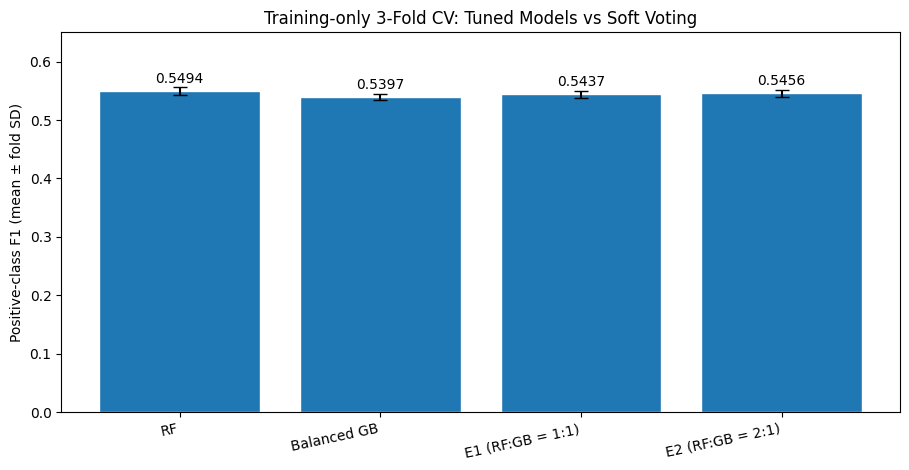

In [8]:
fig, ax = plt.subplots(figsize=(9.2, 4.8))
names = list(results_e2)
means = [results_e2[k]['f1_mean'] for k in names]
sds = [results_e2[k]['f1_std'] for k in names]
x = np.arange(len(names))
ax.bar(x, means, yerr=sds, capsize=5, edgecolor='white')
ax.set_xticks(x, [LABELS[k] for k in names], rotation=12, ha='right')
ax.set_ylim(0, 0.65)
ax.set_ylabel('Positive-class F1 (mean ± fold SD)')
ax.set_title('Training-only 3-Fold CV: Tuned Models vs Soft Voting')
for i, value in enumerate(means):
    ax.text(i, value+0.014, f'{value:.4f}', ha='center', fontsize=10)
fig.tight_layout()
if SAVE_FIGURES:
    dest = (PROJECT_ROOT or Path.cwd()) / 'figures'
    dest.mkdir(parents=True, exist_ok=True)
    fig.savefig(dest / 'm1_ensemble_three_fold_f1.png', dpi=180, bbox_inches='tight')
plt.show()

### E1 vs E2 — Precision and recall trade-off

The weighted version slightly **raises precision** while **lowering recall**. A small mean F1 increase is not proof that E2 dominates the alternatives.

In [9]:
e1, e2_ = results_e2['E1_equal_1to1'], results_e2['E2_weighted_2to1']
change = pd.DataFrame([
    {'Metric': m.capitalize() if m!='f1' else 'F1-score',
     'E1 (1:1)': e1[f'{m}_mean'], 'E2 (2:1)': e2_[f'{m}_mean'],
     'E2 minus E1': e2_[f'{m}_mean'] - e1[f'{m}_mean']}
    for m in ('precision', 'recall', 'f1')
])
display(change.style.format({
    'E1 (1:1)': '{:.4f}', 'E2 (2:1)': '{:.4f}', 'E2 minus E1': '{:+.4f}'
}))

,Metric,E1 (1:1),E2 (2:1),E2 minus E1
0,Precision,0.4902,0.4966,+0.0064
1,Recall,0.6103,0.6054,-0.0049
2,F1-score,0.5437,0.5456,+0.0019


## Figure 6.2.5 — E3 paired fold differences

E3 is **RepeatedStratifiedKFold(3 splits × 2 repeats = 6 folds)**. Comparisons are made on *paired corresponding folds*, not different partitions for each model. The CV folds overlap across repeats, so their differences **must not** be treated as independent samples or as a significance test.

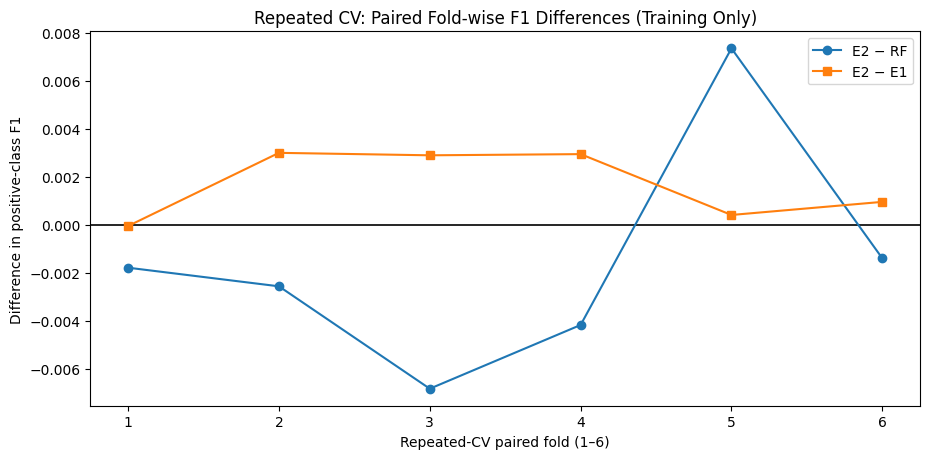

E2 > E1: 5/6 folds
E2 > RF: 1/6 folds
Mean E2 − RF: -0.0016


In [10]:
rf_folds = np.array(results_e3['RF']['f1_folds'])
e1_folds = np.array(results_e3['E1_equal_1to1']['f1_folds'])
e2_folds = np.array(results_e3['E2_weighted_2to1']['f1_folds'])
assert len(rf_folds) == len(e1_folds) == len(e2_folds) == 6

delta_e2_vs_rf = e2_folds - rf_folds
delta_e2_vs_e1 = e2_folds - e1_folds
folds = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(9.4, 4.7))
ax.axhline(0, linewidth=1.2, color='black')
ax.plot(folds, delta_e2_vs_rf, marker='o', label='E2 − RF')
ax.plot(folds, delta_e2_vs_e1, marker='s', label='E2 − E1')
ax.set_xticks(folds)
ax.set_xlabel('Repeated-CV paired fold (1–6)')
ax.set_ylabel('Difference in positive-class F1')
ax.set_title('Repeated CV: Paired Fold-wise F1 Differences (Training Only)')
ax.legend()
fig.tight_layout()
if SAVE_FIGURES:
    dest = (PROJECT_ROOT or Path.cwd()) / 'figures'
    dest.mkdir(parents=True, exist_ok=True)
    fig.savefig(dest / 'm1_ensemble_e3_paired_f1.png', dpi=180, bbox_inches='tight')
plt.show()

print(f'E2 > E1: {int(np.sum(delta_e2_vs_e1 > 0))}/6 folds')
print(f'E2 > RF: {int(np.sum(delta_e2_vs_rf > 0))}/6 folds')
print(f'Mean E2 − RF: {float(delta_e2_vs_rf.mean()):+.4f}')

## Findings, limitations and conclusion

- E2 improved the **original 3-fold mean F1** slightly over E1, but precision and recall moved in opposite directions.
- In E3, E2 remained below **RF alone** in mean F1, exceeding it in only **one of six** paired folds.
- This is evidence that **combining two tuned tree ensembles does not automatically outperform a standalone tuned model**.
- **E2 remains the stronger of the two tested ensemble configurations**, not the best model overall. Chapter 7 compares frozen models once on the independent 6,000-row held-out test set.
- Limitations: fixed 2:1 weight was not exhaustively optimised; CV folds overlap; base models were already selected using training CV; scores do not directly capture asymmetric financial losses or calibration guarantees.

In [11]:
e2_gain = results_e2['E2_weighted_2to1']['f1_mean'] - results_e2['E1_equal_1to1']['f1_mean']
e3_gap_rf = results_e3['E2_weighted_2to1']['f1_mean'] - results_e3['RF']['f1_mean']

print(f'Original 3-fold CV: E2 − E1 mean F1 = {e2_gain:+.4f}')
print(f'Repeated CV: E2 − RF mean F1 = {e3_gap_rf:+.4f}')
print(f'E2 above E1 on {int(np.sum(delta_e2_vs_e1 > 0))}/6 repeated folds')
print(f'E2 above RF on {int(np.sum(delta_e2_vs_rf > 0))}/6 repeated folds')
print('Final interpretation: E2 is the better tested ensemble, NOT proven superior to RF.')

# Checks against source evidence for the default (recorded) mode.
if not RECOMPUTE_CV:
    assert round(results_e2['E2_weighted_2to1']['f1_mean'], 4) == 0.5456
    assert round(results_e3['RF']['f1_mean'], 4) == 0.5480
    assert int(np.sum(delta_e2_vs_rf > 0)) == 1
    assert int(np.sum(delta_e2_vs_e1 > 0)) == 5
    print('PASS: Recorded results are internally consistent with Chapter 6.')

Original 3-fold CV: E2 − E1 mean F1 = +0.0019
Repeated CV: E2 − RF mean F1 = -0.0016
E2 above E1 on 5/6 repeated folds
E2 above RF on 1/6 repeated folds
Final interpretation: E2 is the better tested ensemble, NOT proven superior to RF.
PASS: Recorded results are internally consistent with Chapter 6.


## Optional export — never overwrite original experiment files

If you ran actual CV again (`RECOMPUTE_CV = True`), you may set `SAVE_NEW_EVIDENCE = True` to write new JSON under `results/notebook_ensemble_e2_rerun.json` and `results/notebook_ensemble_e3_rerun.json`. **This does not replace the original handoff evidence.**

In [12]:
if RECOMPUTE_CV and SAVE_NEW_EVIDENCE:
    evidence_dir = PROJECT_ROOT / 'results'
    evidence_dir.mkdir(exist_ok=True, parents=True)
    for name, measured in [('e2', results_e2), ('e3', results_e3)]:
        out = evidence_dir / f'notebook_ensemble_{name}_rerun.json'
        with out.open('w', encoding='utf-8') as fh:
            json.dump({'source': 'Notebook actual training-CV rerun',
                       'test_set_used': False, 'measured': measured}, fh, indent=2)
        print('Saved:', out)
else:
    print('No files written; original team evidence remains unchanged.')

No files written; original team evidence remains unchanged.


## M3 handoff — final held-out evaluation is separate

This notebook **must not evaluate** the held-out test set. To compare E2 with LR/RF/Balanced GB in Chapter 7, M3 can use the previously provided frozen E2 factory in the **team project**:

```python
from src.ensemble_final import make_weighted_ensemble

ensemble = make_weighted_ensemble()  # genuine tuned RF + balanced GB, weights 2:1
ensemble.fit(X_train, y_train)       # shared training split only
# M3 separately scores the fitted model on X_test / y_test only once,
# alongside the three frozen base models.
```

This snippet is documentation for **M3**, intentionally **not executed** as part of M1's Notebook.

### Evidence sources and integrity

- Base model scores: `model_selection.csv`, `rf_ensemble_handoff.json`, `gb_balanced_cv.json`, `lr_cv.json`.
- Training-only E2 results: `ensemble_e2_weight_comparison.json`.
- Training-only E3 results: `ensemble_e3_repeated_cv.json`.
- Real source logic: `src/ensemble.py` and `src/ensemble_experiments.py` (E2/E3 cross-validation).
- No artificial dataset, simulated metrics, new parameter search, or fabricated final-test scores.

In [13]:
SOURCE_SHA256 = {
  "ensemble_e2_weight_comparison.json": "ee09adef8800e85059ec3459b960fc482f0ee737dc41b393a6058da0d14f532f",
  "ensemble_e3_repeated_cv.json": "0db63e86743910b99b72516a237d3b706f842a276cf8c8c30c3b72e456abb560",
  "model_selection.csv": "a132840dac73a590cb76f381aec5993db2c04b841b3a1978ff96f02005ae84f6"
}
for filename, sha in SOURCE_SHA256.items():
    print(f'{filename}: {sha}')
print('Evidence mode:', EVIDENCE_MODE)

ensemble_e2_weight_comparison.json: ee09adef8800e85059ec3459b960fc482f0ee737dc41b393a6058da0d14f532f
ensemble_e3_repeated_cv.json: 0db63e86743910b99b72516a237d3b706f842a276cf8c8c30c3b72e456abb560
model_selection.csv: a132840dac73a590cb76f381aec5993db2c04b841b3a1978ff96f02005ae84f6
Evidence mode: RECORDED TEAM EVIDENCE (no model fitting in this session)


---
# 06 — Final Model Evaluation


---
## Part II — Chapter 7 (Section 7.1): Complete 4-Model Held-Out Final Evaluation (Part G)

### 7. Pre-Flight Verification, Frozen Parity & Sealed Held-Out Result Integrity Check
Part G evaluates the four frozen team models side-by-side under strict parity rules (`24,000` train fit once → `6,000` untouched test scored once, threshold fixed at `0.50`, single-threaded `n_jobs=1`):
1. **Base 1 — Balanced Gradient Boosting (M4)** (`n_estimators=150, max_depth=2, lr=0.1, subsample=0.8`)
2. **Base 2 — Balanced Logistic Regression (M2)** (`C=0.1, solver="lbfgs", class_weight="balanced", scale_numeric=True`)
3. **Base 3 — Tuned Random Forest (M3)** (`Run 64f4bcdb`: `400` trees, `max_depth=18`, `min_samples_leaf=16`, `max_features="sqrt"`, `max_samples=0.65`, `class_weight="balanced_subsample"`, `ccp_alpha=0.0001`)
4. **Ensemble — E2 Weighted Soft Voting `RF:GB = 2:1` (M1)** (`src/ensemble_final.py`)

> **Protection Note:** Running `python -m src.final_evaluation --run-final --force` reproduces `results/final_evaluation.json` from scratch. Here we execute `preflight_check()` live, load the sealed held-out evaluation outputs, and verify every metric against `results/final_test_predictions.csv` directly without overwriting frozen artifacts.

In [ ]:
from src.final_evaluation import (
    ALL_PAIRS,
    FINAL_EVAL_JSON,
    FINAL_PREDICTIONS_CSV,
    MODEL_ORDER,
    MODEL_SPECS,
    mcnemar_test,
    paired_bootstrap_ci,
    preflight_check,
)

pf = preflight_check()
print("Part G Pre-Flight Status:", pf["checks_passed"], "| Held-out eval JSON exists:", pf["final_result_exists"])
for chk in pf["checks"]:
    print(f"  - [{chk['status']}] {chk['check']}: {chk['detail']}")

final_report = json.loads(FINAL_EVAL_JSON.read_text(encoding="utf-8"))
preds_df = pd.read_csv(FINAL_PREDICTIONS_CSV)
ds_info = final_report["dataset"]

print(
    f"\nSealed Split ID: {ds_info['split_id']} | "
    f"Test rows: {ds_info['test_rows']:,} ({int(preds_df['y_true'].sum()):,} defaults = {ds_info['test_positive_rate']:.2%}) | "
    f"Exact train/test overlap rows: {ds_info['train_test_duplicate_predictor_rows']}"
)

# Verify sealed JSON test metrics match raw predictions CSV to < 1e-12 for every model.
y_test_sealed = preds_df["y_true"].to_numpy(dtype=int)
for mkey in MODEL_ORDER:
    p_bin = preds_df[f"pred_{mkey}"].to_numpy(dtype=int)
    p_prob = preds_df[f"prob_{mkey}"].to_numpy(dtype=float)
    tm = final_report["models"][mkey]["test_metrics"]
    assert abs(f1_score(y_test_sealed, p_bin) - tm["f1"]) < 1e-12
    assert abs(roc_auc_score(y_test_sealed, p_prob) - tm["roc_auc"]) < 1e-12
    assert abs(average_precision_score(y_test_sealed, p_prob) - tm["average_precision"]) < 1e-12
    assert abs(brier_score_loss(y_test_sealed, p_prob) - tm["brier"]) < 1e-12
print("Integrity Verification PASS: All 4 models in results/final_test_predictions.csv match results/final_evaluation.json to < 1e-12.")

Part G Pre-Flight Status: True | Held-out eval JSON exists: True
  - [PASS] Shared Dataset & Split Integrity: 30,000 rows (24,000 train / 6,000 test), 23 features, 0 missing values, stratified seed=42.
  - [PASS] Frozen Base & Ensemble Factories: All 4 models (GB Balanced, LR Balanced, Tuned RF, E2 Soft Voting 2:1) instantiated and cloned.
  - [SEALED (READ-ONLY)] Held-Out Test Isolation: Official evaluation JSON exists; UI/CLI remain read-only.

Sealed Split ID: 52aed26db24ab9b5d683ee70569de463d806f8a40cc387b0c18630067c3648ff | Test rows: 6,000 (1,327 defaults = 22.12%) | Exact train/test overlap rows: 15
Integrity Verification PASS: All 4 models in results/final_test_predictions.csv match results/final_evaluation.json to < 1e-12.


### 8. Held-Out Test Performance Table (`Table 7.1.1`) & 2×2 Confusion Matrices (`Figure 7.1.1(a)`)
Every frozen model clears both dummy baselines (`77.88%` prior accuracy / `0.0000` F1; `0.3622` all-positive F1 floor; `0.2212` PR-AUC chance floor). E2 leads F1 (`0.5458`), ROC-AUC (`0.7787`), and PR-AUC (`0.5503`); Tuned RF leads accuracy (`0.7805`), precision (`0.5032`), MCC (`0.4045`), and Brier loss (`0.1714`); Balanced GB maximizes recall (`0.6285`); and Balanced LR trails in recall (`0.5554`) and ROC-AUC (`0.7593`).

Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Brier,TN / FP / FN / TP
Dummy (Majority Prior),0.7788,0.0000,0.0000,0.0000,0.5000,0.2212,0.0000,0.1723,"4,673 / 0 / 1,327 / 0"
Dummy (All-Positive Floor),0.2212,0.2212,1.0000,0.3622,0.5000,0.2212,0.0000,0.7788,"0 / 4,673 / 0 / 1,327"
Base 1: Gradient Boosting (Balanced),0.7610,0.4699,0.6285,0.5377,0.7785,0.5456,0.3884,0.1825,"3,732 / 941 / 493 / 834"
Base 2: Logistic Regression (Balanced),0.7740,0.4904,0.5554,0.5208,0.7593,0.5268,0.3750,0.1865,"3,907 / 766 / 590 / 737"
Base 3: Random Forest (Tuned),0.7805,0.5032,0.5953,0.5454,0.7764,0.5481,0.4045,0.1714,"3,893 / 780 / 537 / 790"
Ensemble: E2 Soft Voting (RF:GB 2:1),0.7778,0.4981,0.6036,0.5458,0.7787,0.5503,0.4038,0.1744,"3,866 / 807 / 526 / 801"


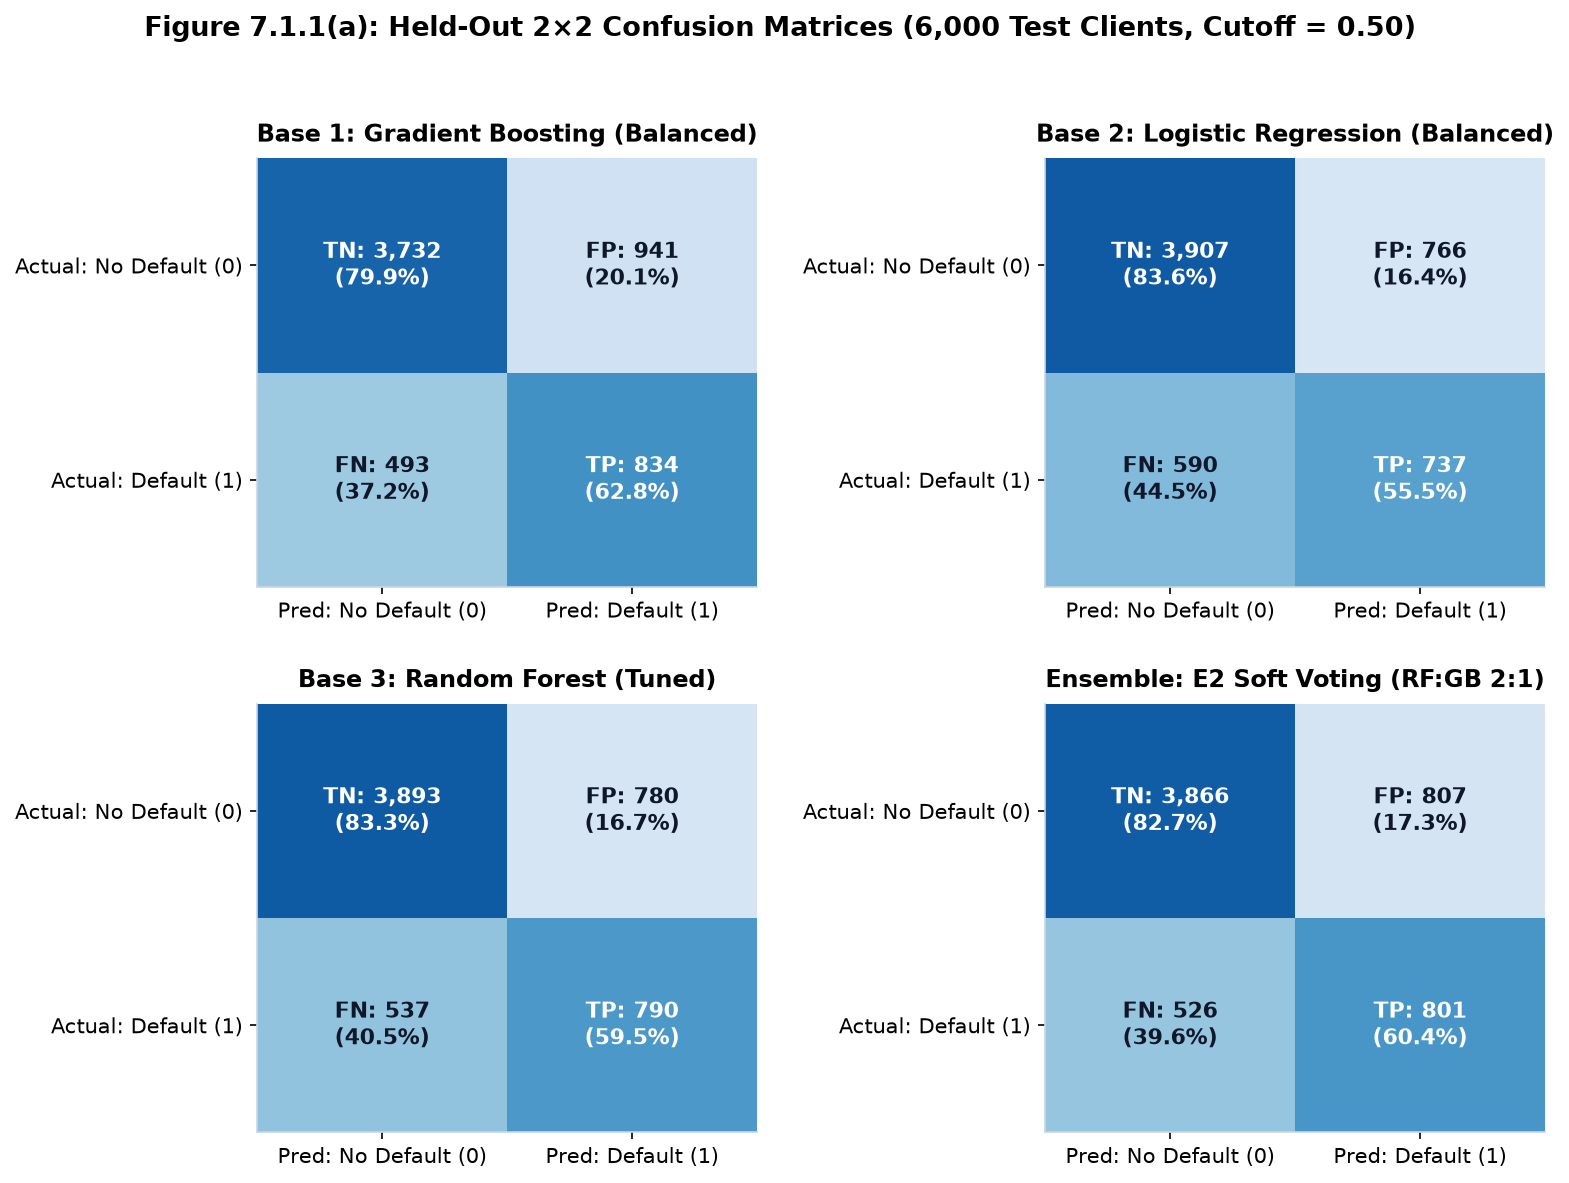

In [ ]:
t711_rows = []
for dkey, dname in (("dummy_prior", "Dummy (Majority Prior)"), ("dummy_all_positive", "Dummy (All-Positive Floor)")):
    tm = final_report["dummies"][dkey]["test_metrics"]
    cm = tm["confusion_matrix"]
    t711_rows.append({
        "Model": dname,
        "Accuracy": round(tm["accuracy"], 4),
        "Precision": round(tm["precision"], 4),
        "Recall": round(tm["recall"], 4),
        "F1": round(tm["f1"], 4),
        "ROC-AUC": round(tm["roc_auc"], 4),
        "PR-AUC": round(tm["average_precision"], 4),
        "MCC": round(tm["mcc"], 4),
        "Brier": round(tm["brier"], 4),
        "TN / FP / FN / TP": f"{cm[0][0]:,} / {cm[0][1]:,} / {cm[1][0]:,} / {cm[1][1]:,}",
    })

for mkey in MODEL_ORDER:
    tm = final_report["models"][mkey]["test_metrics"]
    cm = tm["confusion_matrix"]
    t711_rows.append({
        "Model": MODEL_SPECS[mkey]["label"],
        "Accuracy": round(tm["accuracy"], 4),
        "Precision": round(tm["precision"], 4),
        "Recall": round(tm["recall"], 4),
        "F1": round(tm["f1"], 4),
        "ROC-AUC": round(tm["roc_auc"], 4),
        "PR-AUC": round(tm["average_precision"], 4),
        "MCC": round(tm["mcc"], 4),
        "Brier": round(tm["brier"], 4),
        "TN / FP / FN / TP": f"{cm[0][0]:,} / {cm[0][1]:,} / {cm[1][0]:,} / {cm[1][1]:,}",
    })

display(pd.DataFrame(t711_rows))

# Figure 7.1.1(a): 2x2 Row-normalized confusion matrices on 6,000 test clients.
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
cell_names = [["TN", "FP"], ["FN", "TP"]]
for ax, mkey in zip(axes.flat, MODEL_ORDER):
    cm = np.asarray(final_report["models"][mkey]["test_metrics"]["confusion_matrix"], dtype=int)
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap="Blues", vmin=0.0, vmax=1.0, aspect="auto")
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            txt_color = "white" if row_pct[i, j] > 0.55 else "#0f172a"
            ax.text(
                j,
                i,
                f"{cell_names[i][j]}: {cm[i, j]:,}\n({row_pct[i, j]:.1%})",
                ha="center",
                va="center",
                color=txt_color,
                fontsize=10.5,
                fontweight="bold",
            )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Pred: No Default (0)", "Pred: Default (1)"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Actual: No Default (0)", "Actual: Default (1)"])
    ax.set_title(MODEL_SPECS[mkey]["label"], pad=8)

fig.suptitle("Figure 7.1.1(a): Held-Out 2×2 Confusion Matrices (6,000 Test Clients, Cutoff = 0.50)", fontsize=12.8, fontweight="bold", y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.95], h_pad=2.2, w_pad=2.2)
plt.show()

### 9. Held-Out Threshold-Free Curves, Calibration & Inter-Model Agreement (`Figure 7.1.1(b)`)
This 2×2 diagnostic suite computed directly from `results/final_test_predictions.csv` inspects ROC discrimination, Precision–Recall behavior above the `0.2212` prevalence floor, 10-bin quantile probability calibration (`RF Brier = 0.1714`, note upward shift caused by balanced class weighting), and 4×4 prediction agreement (`RF` vs `E2` agree on `98.7%` of clients, Cohen's κ = `0.967`).

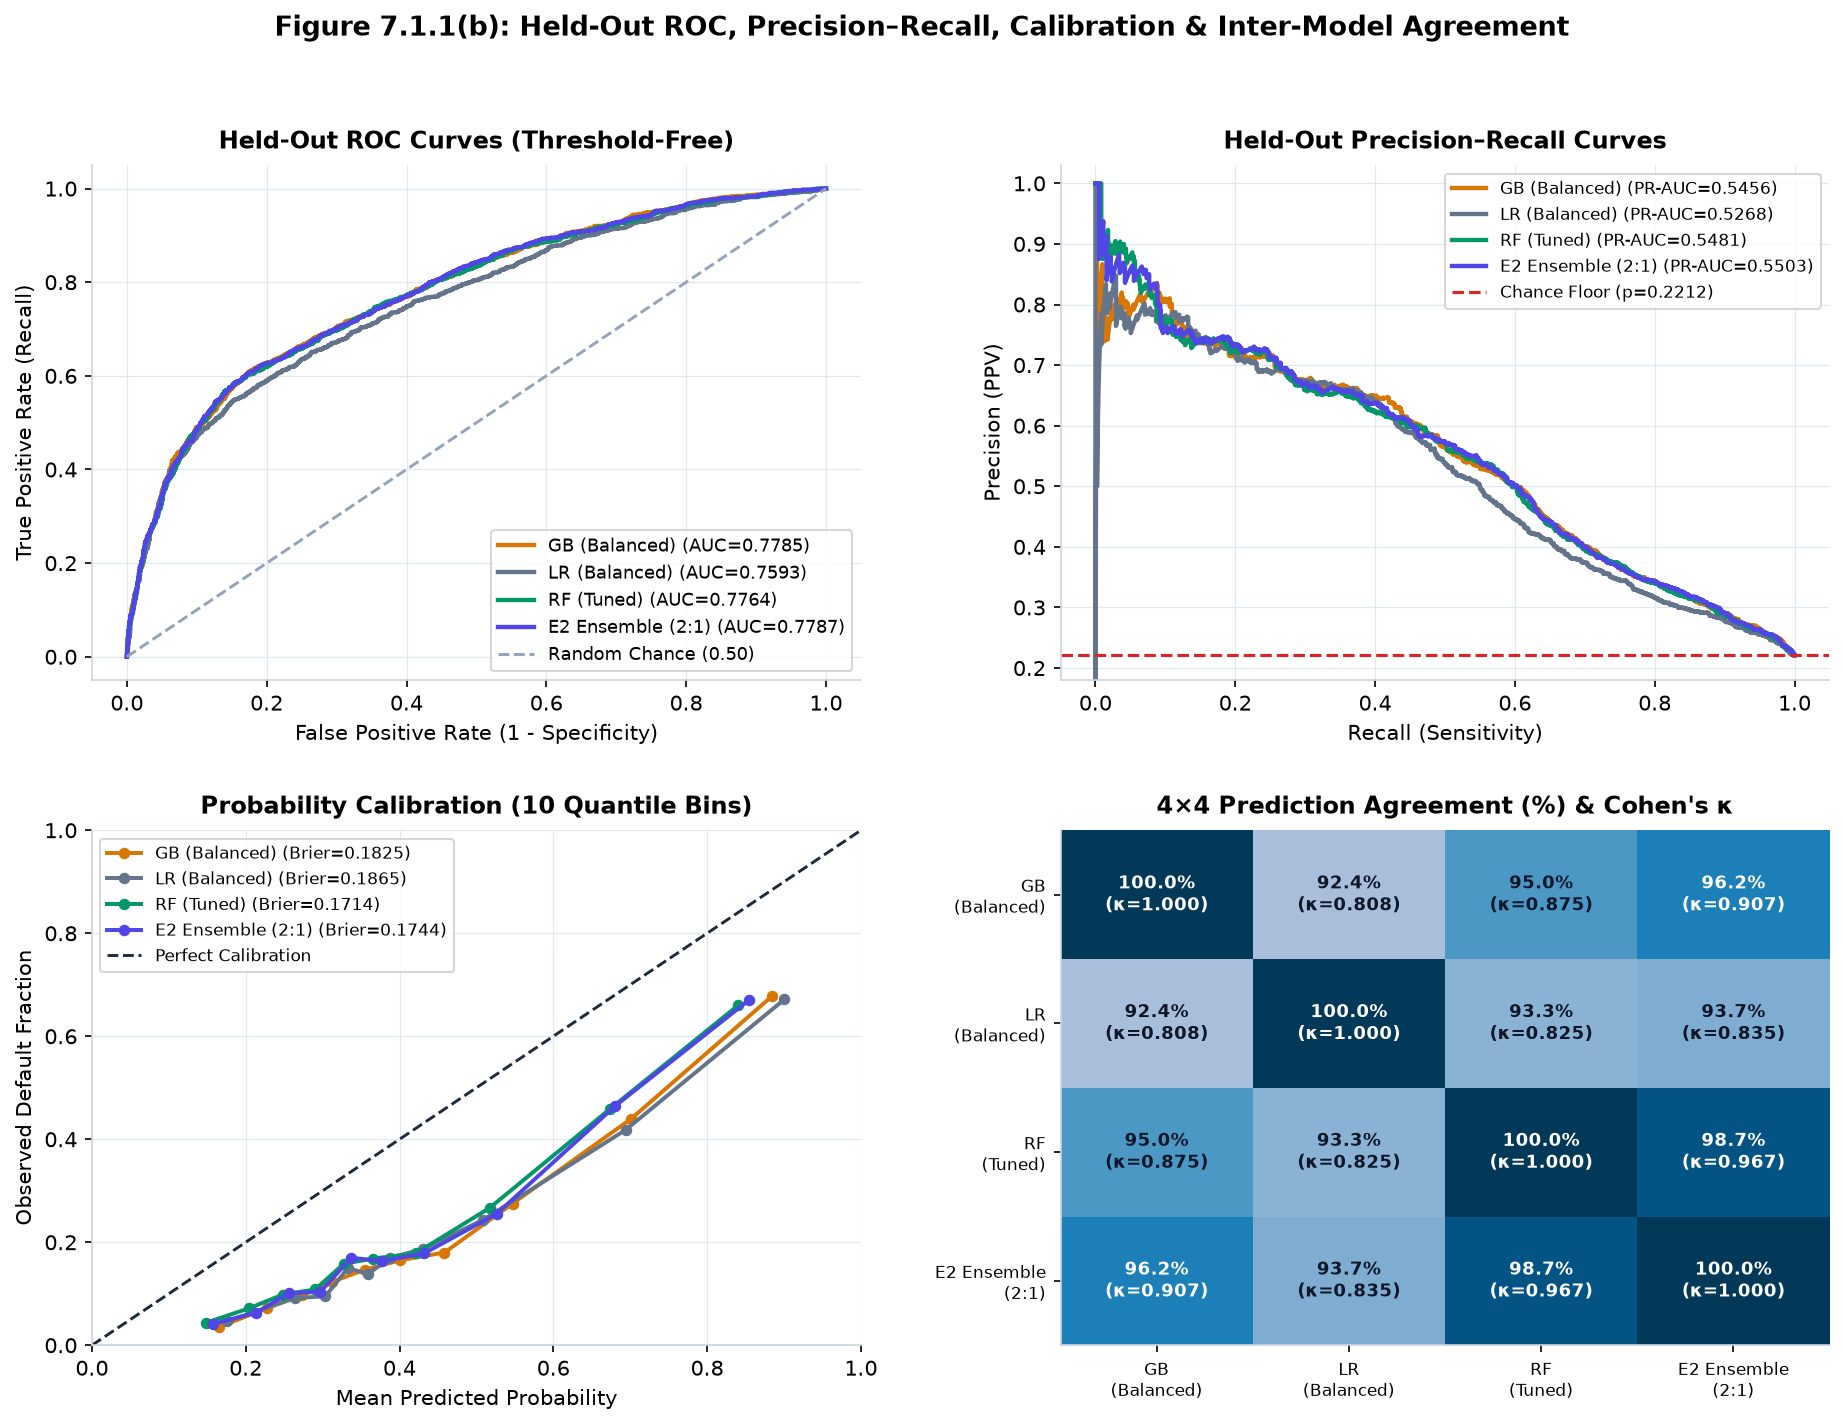

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12.4, 9.6))
ax_roc, ax_pr, ax_cal, ax_agr = axes.flat

# Panel 1: ROC Curves
for mkey in MODEL_ORDER:
    prob = preds_df[f"prob_{mkey}"].to_numpy(dtype=float)
    fpr, tpr, _ = roc_curve(y_test_sealed, prob)
    auc_val = roc_auc_score(y_test_sealed, prob)
    ax_roc.plot(fpr, tpr, color=MODEL_SPECS[mkey]["color"], lw=2.1, label=f"{MODEL_SPECS[mkey]['short']} (AUC={auc_val:.4f})")
ax_roc.plot([0, 1], [0, 1], "--", color="#94a3b8", lw=1.4, label="Random Chance (0.50)")
ax_roc.set_title("Held-Out ROC Curves (Threshold-Free)", pad=8)
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc="lower right", fontsize=8.5, frameon=True)

# Panel 2: Precision-Recall Curves
test_pos_rate = float(np.mean(y_test_sealed))
for mkey in MODEL_ORDER:
    prob = preds_df[f"prob_{mkey}"].to_numpy(dtype=float)
    p_c, r_c, _ = precision_recall_curve(y_test_sealed, prob)
    ap_val = average_precision_score(y_test_sealed, prob)
    ax_pr.plot(r_c, p_c, color=MODEL_SPECS[mkey]["color"], lw=2.1, label=f"{MODEL_SPECS[mkey]['short']} (PR-AUC={ap_val:.4f})")
ax_pr.axhline(test_pos_rate, color="#dc2626", linestyle="--", lw=1.5, label=f"Chance Floor (p={test_pos_rate:.4f})")
ax_pr.set_title("Held-Out Precision–Recall Curves", pad=8)
ax_pr.set_xlabel("Recall (Sensitivity)")
ax_pr.set_ylabel("Precision (PPV)")
ax_pr.set_ylim(0.18, 1.03)
ax_pr.legend(loc="upper right", fontsize=8.3, frameon=True)

# Panel 3: Probability Calibration (10 quantile bins)
for mkey in MODEL_ORDER:
    prob = preds_df[f"prob_{mkey}"].to_numpy(dtype=float)
    frac_pos, mean_pred = calibration_curve(y_test_sealed, prob, n_bins=10, strategy="quantile")
    brier_val = brier_score_loss(y_test_sealed, prob)
    ax_cal.plot(mean_pred, frac_pos, "-o", color=MODEL_SPECS[mkey]["color"], lw=1.9, markersize=4.5, label=f"{MODEL_SPECS[mkey]['short']} (Brier={brier_val:.4f})")
ax_cal.plot([0, 1], [0, 1], "--", color="#1e293b", lw=1.4, label="Perfect Calibration")
ax_cal.set_title("Probability Calibration (10 Quantile Bins)", pad=8)
ax_cal.set_xlabel("Mean Predicted Probability")
ax_cal.set_ylabel("Observed Default Fraction")
ax_cal.set_xlim(0.0, 1.0)
ax_cal.set_ylim(0.0, 1.0)
ax_cal.legend(loc="upper left", fontsize=8.2, frameon=True)

# Panel 4: 4x4 Prediction Agreement (%) & Cohen's kappa
pa = final_report["pairwise_agreement"]
agr_mat = np.asarray(pa["agreement_rate"], dtype=float)
kap_mat = np.asarray(pa["cohen_kappa"], dtype=float)
short_labels = [MODEL_SPECS[k]["short"].replace(" (Balanced)", "\n(Balanced)").replace(" (Tuned)", "\n(Tuned)").replace(" (2:1)", "\n(2:1)") for k in MODEL_ORDER]
ax_agr.imshow(agr_mat, cmap="PuBu", vmin=0.88, vmax=1.0, aspect="auto")
ax_agr.grid(False)
for i in range(len(MODEL_ORDER)):
    for j in range(len(MODEL_ORDER)):
        txt_col = "white" if agr_mat[i, j] > 0.96 else "#0f172a"
        ax_agr.text(
            j,
            i,
            f"{agr_mat[i, j]:.1%}\n(κ={kap_mat[i, j]:.3f})",
            ha="center",
            va="center",
            color=txt_col,
            fontsize=8.6,
            fontweight="bold",
        )
ax_agr.set_xticks(range(len(MODEL_ORDER)))
ax_agr.set_xticklabels(short_labels, fontsize=8.4)
ax_agr.set_yticks(range(len(MODEL_ORDER)))
ax_agr.set_yticklabels(short_labels, fontsize=8.4)
ax_agr.set_title("4×4 Prediction Agreement (%) & Cohen's κ", pad=8)

fig.suptitle("Figure 7.1.1(b): Held-Out ROC, Precision–Recall, Calibration & Inter-Model Agreement", fontsize=13, fontweight="bold", y=0.985)
fig.tight_layout(rect=[0, 0, 1, 0.955], h_pad=2.4, w_pad=2.4)
plt.show()

### 10. Generalisation Gaps & Single-Threaded Runtime Efficiency (`Table 7.1.2`, `Figure 7.1.2`)
Comparing **Train → 3-Fold CV → Held-Out Test** checks for overfitting or CV-to-test shift, while single-threaded parity (`n_jobs=1`) gives an unconfounded comparison of training time, 6,000-row inference latency, and saved `.joblib` footprint. Notice that Balanced GB scores `12.6×` faster (`15.0` vs. `188.9` ms) and stores `177×` smaller (`43.7 KB` vs. `7,748.6 KB`) than Random Forest, while E2 doubles fit compute (`14.38 s`) and storage (`7,804.5 KB`) with zero CV-to-test F1 drop.

Model,Train F1,3-Fold CV F1,Held-Out Test F1,Train–Test Gap,CV–Test Shift,Fit (s),6k Score (ms),Size (KB),Regime
Base 1: Gradient Boosting (Balanced),0.5522,0.5397,0.5377,+0.0145,+0.0020,6.75,15.0,43.7,Higher bias / Linear boundary (slight underfit vs trees)
Base 2: Logistic Regression (Balanced),0.5363,0.5347,0.5208,+0.0155,+0.0138,0.13,9.8,2.8,Higher bias / Linear boundary (slight underfit vs trees)
Base 3: Random Forest (Tuned),0.5945,0.5494,0.5454,+0.0491,+0.0040,7.65,188.9,"7,748.6",Moderate variance (controlled gap)
Ensemble: E2 Soft Voting (RF:GB 2:1),0.5847,0.5456,0.5458,+0.0388,-0.0002,14.38,198.7,"7,804.5",Moderate variance (controlled gap)


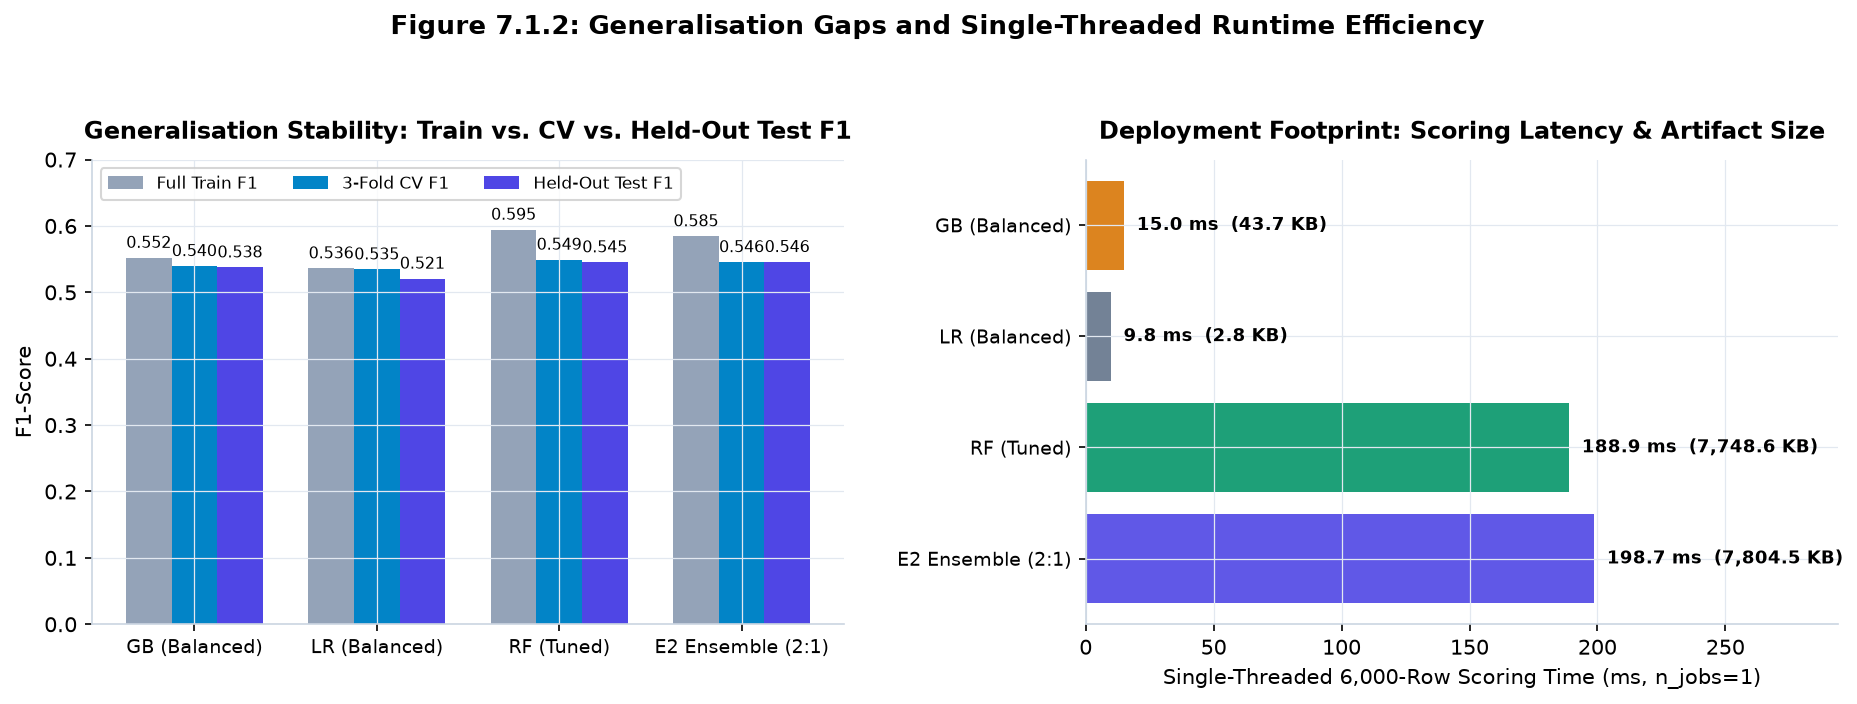

In [ ]:
t712_rows = []
for mkey in MODEL_ORDER:
    m = final_report["models"][mkey]
    gen = m["generalization"]
    eff = m["efficiency"]
    t712_rows.append({
        "Model": MODEL_SPECS[mkey]["label"],
        "Train F1": round(m["train_metrics"]["f1"], 4),
        "3-Fold CV F1": round(gen["cv_f1_mean"], 4),
        "Held-Out Test F1": round(m["test_metrics"]["f1"], 4),
        "Train–Test Gap": f"{gen['f1_train_test_gap']:+.4f}",
        "CV–Test Shift": f"{gen['f1_cv_test_gap']:+.4f}",
        "Fit (s)": round(eff["fit_seconds"], 2),
        "6k Score (ms)": round(eff["predict_ms_total"], 1),
        "Size (KB)": f"{eff['artifact_size_kb']:,.1f}",
        "Regime": gen["regime"],
    })

t712_df = pd.DataFrame(t712_rows)
display(t712_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.7))
short_names = [MODEL_SPECS[k]["short"] for k in MODEL_ORDER]
x = np.arange(len(MODEL_ORDER))
bw = 0.25
tr_f1 = [final_report["models"][k]["train_metrics"]["f1"] for k in MODEL_ORDER]
cv_f1 = [final_report["models"][k]["generalization"]["cv_f1_mean"] for k in MODEL_ORDER]
te_f1 = [final_report["models"][k]["test_metrics"]["f1"] for k in MODEL_ORDER]

bars_tr = ax1.bar(x - bw, tr_f1, width=bw, color="#94a3b8", label="Full Train F1")
bars_cv = ax1.bar(x, cv_f1, width=bw, color="#0284c7", label="3-Fold CV F1")
bars_te = ax1.bar(x + bw, te_f1, width=bw, color="#4f46e5", label="Held-Out Test F1")
for b_grp in (bars_tr, bars_cv, bars_te):
    for bar in b_grp:
        ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.009, f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=7.8)
ax1.set_xticks(x)
ax1.set_xticklabels(short_names, fontsize=9)
ax1.set_ylim(0, 0.70)
ax1.set_ylabel("F1-Score")
ax1.set_title("Generalisation Stability: Train vs. CV vs. Held-Out Test F1", pad=10)
ax1.legend(loc="upper left", fontsize=8.4, ncol=3, frameon=True)

score_ms = [final_report["models"][k]["efficiency"]["predict_ms_total"] for k in MODEL_ORDER]
size_kb = [final_report["models"][k]["efficiency"]["artifact_size_kb"] for k in MODEL_ORDER]
colors_eff = [MODEL_SPECS[k]["color"] for k in MODEL_ORDER]
y_pos = np.arange(len(MODEL_ORDER))
hbars = ax2.barh(y_pos, score_ms, color=colors_eff, alpha=0.9)
for y_i, (ms, kb) in enumerate(zip(score_ms, size_kb)):
    ax2.text(ms + 5.0, y_i, f"{ms:.1f} ms  ({kb:,.1f} KB)", va="center", fontsize=8.8, fontweight="bold")
ax2.set_yticks(y_pos)
ax2.set_yticklabels(short_names, fontsize=9)
ax2.invert_yaxis()
ax2.set_xlim(0, max(score_ms) * 1.48)
ax2.set_xlabel("Single-Threaded 6,000-Row Scoring Time (ms, n_jobs=1)")
ax2.set_title("Deployment Footprint: Scoring Latency & Artifact Size", pad=10)

fig.suptitle("Figure 7.1.2: Generalisation Gaps and Single-Threaded Runtime Efficiency", fontsize=12.6, fontweight="bold", y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.94], w_pad=2.4)
plt.show()

### 11. Live Pairwise Statistical Significance (`Table 7.1.3`, `Figure 7.1.3`)
To distinguish genuine improvements from finite-sample noise on `6,000` correlated test predictions and repeated CV folds, `src/final_evaluation.py` runs:
1. **McNemar's Test** (`McNemar, 1947; Rainio, Teuho and Klén, 2024`): Exact binomial or continuity-corrected $\chi^2$ on discordant classification errors (`n10` vs. `n01`).
2. **Paired Stratified Bootstrap 95% CIs** (`2,000` resamples, `seed=42`): Preserves the `22.12%` class ratio per resample and tests whether ΔF1 and ΔROC-AUC exclude zero.
3. **Nadeau–Bengio Corrected Resampled Paired t-Test** (`Nadeau and Bengio, 2003`): Corrects fold-overlap correlation on M1's E3 3×2 repeated CV (`k=6`, `df=5`).

Held-Out Pairwise McNemar & 2,000-Resample Stratified Bootstrap Tests (Live-Verified):
Nadeau–Bengio Corrected Resampled t-Test on M1 Repeated 3×2 CV:


Comparison (A vs. B),ΔF1 [95% CI],ΔROC-AUC [95% CI],McNemar p (n10 / n01),Agree / κ
E2 vs. Logistic Regression,"+0.0250 [+0.0133, +0.0365] (sig)","+0.0194 [+0.0116, +0.0269] (sig)",0.2597 (202 / 179),93.7% / 0.835
E2 vs. Gradient Boosting,"+0.0081 [-0.0003, +0.0163] (n.s.)","+0.0001 [-0.0027, +0.0027] (n.s.)",<0.0001 (163 / 62),96.2% / 0.907
E2 vs. Random Forest,"+0.0004 [-0.0043, +0.0053] (n.s.)","+0.0023 [+0.0009, +0.0038] (sig)",0.0894 (31 / 47),98.7% / 0.967
Random Forest vs. Gradient Boosting,"+0.0077 [-0.0024, +0.0173] (n.s.)","-0.0022 [-0.0065, +0.0017] (n.s.)",<0.0001 (210 / 93),95.0% / 0.875


Repeated 3×2 CV Comparison,Metric,Mean Diff,Nadeau–Bengio t (df=5),p-value,Folds A Better,Sig (α=0.05)
E2 vs RF,F1,-0.0016,-0.400,0.7058,1/6,No
E2 vs RF,ROC_AUC,+0.0012,+2.219,0.0772,6/6,No
E2 vs GB_balanced,F1,+0.0054,+1.480,0.1990,5/6,No
E2 vs GB_balanced,ROC_AUC,+0.0031,+2.598,0.0484,6/6,Yes
RF vs GB_balanced,F1,+0.0069,+1.011,0.3583,5/6,No
RF vs GB_balanced,ROC_AUC,+0.0019,+1.097,0.3224,5/6,No


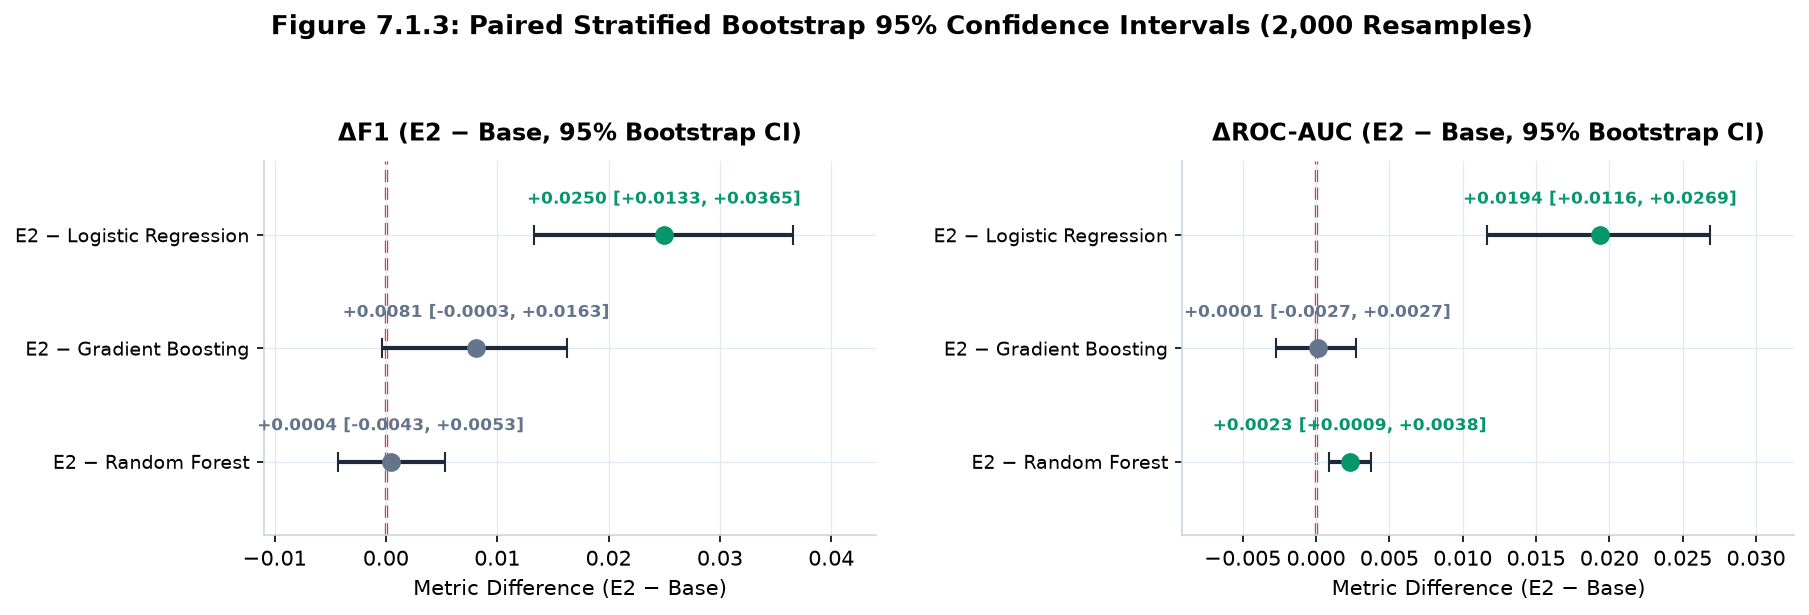

In [ ]:
def _fmt_p(p_val: float) -> str:
    if p_val < 0.0001:
        return "<0.0001"
    if p_val < 0.001:
        return "<0.001"
    return f"{p_val:.4f}"

pair_rows = []
primary_plot_items = []
pa_keys = final_report["pairwise_agreement"]["model_keys"]
agr_mat = final_report["pairwise_agreement"]["agreement_rate"]
kap_mat = final_report["pairwise_agreement"]["cohen_kappa"]

display_pairs = [
    ("ensemble_e2", "logistic_regression", "E2 vs. Logistic Regression"),
    ("ensemble_e2", "gb_balanced", "E2 vs. Gradient Boosting"),
    ("ensemble_e2", "random_forest", "E2 vs. Random Forest"),
    ("random_forest", "gb_balanced", "Random Forest vs. Gradient Boosting"),
]

# Compute live from final_test_predictions.csv and cross-check sealed JSON.
for key_a, key_b, label_ab in display_pairs:
    pred_a = preds_df[f"pred_{key_a}"].to_numpy(dtype=int)
    prob_a = preds_df[f"prob_{key_a}"].to_numpy(dtype=float)
    pred_b = preds_df[f"pred_{key_b}"].to_numpy(dtype=int)
    prob_b = preds_df[f"prob_{key_b}"].to_numpy(dtype=float)

    mc_live = mcnemar_test(y_test_sealed, pred_a, pred_b)
    bs_live = paired_bootstrap_ci(y_test_sealed, pred_a, prob_a, pred_b, prob_b, n_boot=2000, seed=42)

    sealed_pair = final_report["statistical_tests"]["pairwise_held_out"][f"{key_a}__vs__{key_b}"]
    assert abs(mc_live["p_value"] - sealed_pair["mcnemar"]["p_value"]) < 1e-12
    assert abs(bs_live["f1"]["observed_diff"] - sealed_pair["bootstrap"]["f1"]["observed_diff"]) < 1e-12

    idx_a, idx_b = pa_keys.index(key_a), pa_keys.index(key_b)
    bf1 = bs_live["f1"]
    broc = bs_live["roc_auc"]
    pair_rows.append({
        "Comparison (A vs. B)": label_ab,
        "ΔF1 [95% CI]": f"{bf1['observed_diff']:+.4f} [{bf1['ci_low']:+.4f}, {bf1['ci_high']:+.4f}] ({'sig' if bf1['significant_0_05'] else 'n.s.'})",
        "ΔROC-AUC [95% CI]": f"{broc['observed_diff']:+.4f} [{broc['ci_low']:+.4f}, {broc['ci_high']:+.4f}] ({'sig' if broc['significant_0_05'] else 'n.s.'})",
        "McNemar p (n10 / n01)": f"{_fmt_p(mc_live['p_value'])} ({mc_live['n10_a_right_b_wrong']} / {mc_live['n01_a_wrong_b_right']})",
        "Agree / κ": f"{agr_mat[idx_a][idx_b]:.1%} / {kap_mat[idx_a][idx_b]:.3f}",
    })
    if key_a == "ensemble_e2":
        primary_plot_items.append((label_ab.replace(" vs. ", " − "), bf1, broc))

print("Held-Out Pairwise McNemar & 2,000-Resample Stratified Bootstrap Tests (Live-Verified):")
display(pd.DataFrame(pair_rows))

nb_block = final_report["statistical_tests"].get("nadeau_bengio_repeated_cv", {})
if nb_block:
    nb_rows = []
    for comp_name, metrics_dict in nb_block.items():
        for m_metric in ("f1", "roc_auc"):
            res = metrics_dict[m_metric]
            nb_rows.append({
                "Repeated 3×2 CV Comparison": comp_name,
                "Metric": m_metric.upper(),
                "Mean Diff": f"{res['mean_diff']:+.4f}",
                "Nadeau–Bengio t (df=5)": f"{res['t_stat']:+.3f}",
                "p-value": f"{res['p_value']:.4f}",
                "Folds A Better": f"{res['folds_a_better']}/{res['k']}",
                "Sig (α=0.05)": "Yes" if res["significant_0_05"] else "No",
            })
    print("Nadeau–Bengio Corrected Resampled t-Test on M1 Repeated 3×2 CV:")
    display(pd.DataFrame(nb_rows))

# Figure 7.1.3: Bootstrap 95% CI Forest Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.1))
y_idx = np.arange(len(primary_plot_items))
labels_y = [item[0] for item in primary_plot_items]

for ax, metric_idx, title_m in [
    (ax1, 1, "ΔF1 (E2 − Base, 95% Bootstrap CI)"),
    (ax2, 2, "ΔROC-AUC (E2 − Base, 95% Bootstrap CI)"),
]:
    ax.axvline(0.0, color="#dc2626", linestyle="--", lw=1.6, zorder=1)
    all_lo, all_hi = [], []
    for r_i, item in enumerate(primary_plot_items):
        st = item[metric_idx]
        obs = st["observed_diff"]
        lo = st["ci_low"]
        hi = st["ci_high"]
        all_lo.append(lo)
        all_hi.append(hi)
        sig_col = "#059669" if st["significant_0_05"] else "#64748b"
        ax.errorbar(
            obs,
            r_i,
            xerr=[[obs - lo], [hi - obs]],
            fmt="o",
            color=sig_col,
            ecolor="#1e293b",
            elinewidth=2.0,
            capsize=5,
            markersize=8,
            zorder=4,
        )
        ax.text(
            obs,
            r_i - 0.24,
            f"{obs:+.4f} [{lo:+.4f}, {hi:+.4f}]",
            ha="center",
            va="bottom",
            fontsize=8.3,
            fontweight="bold",
            color=sig_col,
        )
    span = max(max(all_hi) - min(min(all_lo), -0.005), 0.01)
    ax.set_xlim(min(min(all_lo), -0.004) - span * 0.16, max(all_hi) + span * 0.18)
    ax.set_ylim(-0.65, len(primary_plot_items) - 0.35)
    ax.set_yticks(y_idx)
    ax.set_yticklabels(labels_y, fontsize=9.2)
    ax.invert_yaxis()
    ax.set_title(title_m, pad=10)
    ax.set_xlabel("Metric Difference (E2 − Base)")

fig.suptitle("Figure 7.1.3: Paired Stratified Bootstrap 95% Confidence Intervals (2,000 Resamples)", fontsize=12.6, fontweight="bold", y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.93], w_pad=2.5)
plt.show()

### 12. Domain-Grouped Feature Attribution Consensus & Handoff to Sections 7.2 and 7.3
Finally, we verify cross-model domain-grouped permutation importance (`Repayment Status PAY_0..6` is the dominant F1 driver across all four frozen models, consistent with `PAY_0` single-feature attribution in Section 7.2) and confirm that all frozen M3 and Part G handoff artifacts exist intact on disk for M4's error decomposition and deployment recommendation.

In [ ]:
# Cross-model Domain-Grouped Permutation Importance (F1 Drop on Untouched Held-Out Split)
group_names = [g["group"] for g in final_report["models"]["random_forest"]["grouped_permutation_importance"]]
g_rows = []
for grp in group_names:
    row = {"Feature Domain": grp}
    for mkey in MODEL_ORDER:
        match = next(x for x in final_report["models"][mkey]["grouped_permutation_importance"] if x["group"] == grp)
        row[f"{MODEL_SPECS[mkey]['short']} (F1 Drop)"] = f"{match['f1_mean']:.4f} ± {match['f1_std']:.4f}"
    g_rows.append(row)
display(pd.DataFrame(g_rows))

handoff_files = [
    "results/random_forest_cv.json",
    "results/random_forest_search.csv",
    "results/rf_ensemble_handoff.json",
    "results/final_evaluation.json",
    "results/final_model_comparison.csv",
    "results/final_test_predictions.csv",
    "artifacts/random_forest.joblib",
    "artifacts/final_ensemble_e2.joblib",
    "src/random_forest.py",
    "src/final_evaluation.py",
    "m3_workspace/app/final_eval_app.py",
]
print("\nArtifact & Codebase Handoff Verification:")
for rel in handoff_files:
    fp = PROJECT_ROOT / rel
    status = f"OK ({fp.stat().st_size:,} bytes)" if fp.is_file() else "MISSING"
    print(f"  - {rel:42s} : {status}")


Artifact & Codebase Handoff Verification:
  - results/random_forest_cv.json              : OK (3,266 bytes)
  - results/random_forest_search.csv           : OK (44,997 bytes)
  - results/rf_ensemble_handoff.json           : OK (5,305 bytes)
  - results/final_evaluation.json              : OK (388,876 bytes)
  - results/final_model_comparison.csv         : OK (2,429 bytes)
  - results/final_test_predictions.csv         : OK (563,423 bytes)
  - artifacts/random_forest.joblib             : OK (19,414,031 bytes)
  - artifacts/final_ensemble_e2.joblib         : OK (7,991,809 bytes)
  - src/random_forest.py                       : OK (5,210 bytes)
  - src/final_evaluation.py                    : OK (55,422 bytes)
  - m3_workspace/app/final_eval_app.py         : OK (51,420 bytes)


Feature Domain,GB (Balanced) (F1 Drop),LR (Balanced) (F1 Drop),RF (Tuned) (F1 Drop),E2 Ensemble (2:1) (F1 Drop)
Repayment Status (PAY_0..6),0.2033 ± 0.0046,0.2423 ± 0.0102,0.2916 ± 0.0115,0.2654 ± 0.0138
Payment Amounts (PAY_AMT1..6),0.0614 ± 0.0042,0.0076 ± 0.0037,0.0327 ± 0.0019,0.0436 ± 0.0019
Bill Statements (BILL_AMT1..6),0.0236 ± 0.0039,0.0085 ± 0.0026,0.0073 ± 0.0033,0.0125 ± 0.0031
Credit Limit (LIMIT_BAL),0.0087 ± 0.0025,0.0107 ± 0.0020,0.0036 ± 0.0017,0.0064 ± 0.0030
"Demographics (SEX, EDU, MARR, AGE)",0.0060 ± 0.0030,0.0024 ± 0.0039,0.0034 ± 0.0017,0.0058 ± 0.0020


## 13. Comparative Analysis of Performance, Efficiency and Interpretability

The frozen models are interpreted in two ways. The first is permutation importance on the training data. The second is a false-positive and false-negative decomposition on the held-out test set.

=== 7.2.1 Permutation Importance ===


,feature,importance_mean,importance_std
0,PAY_0,0.2067,0.0027
1,PAY_2,0.0296,0.0013
2,PAY_3,0.0175,0.0004
3,LIMIT_BAL,0.0169,0.0016
4,BILL_AMT1,0.0158,0.0021
5,PAY_AMT1,0.0114,0.0014
6,PAY_AMT2,0.0105,0.0017
7,PAY_6,0.0105,0.0017
8,PAY_5,0.0094,0.0006
9,PAY_4,0.0076,0.0010



=== Figure 7.2.1: Permutation Importance ===


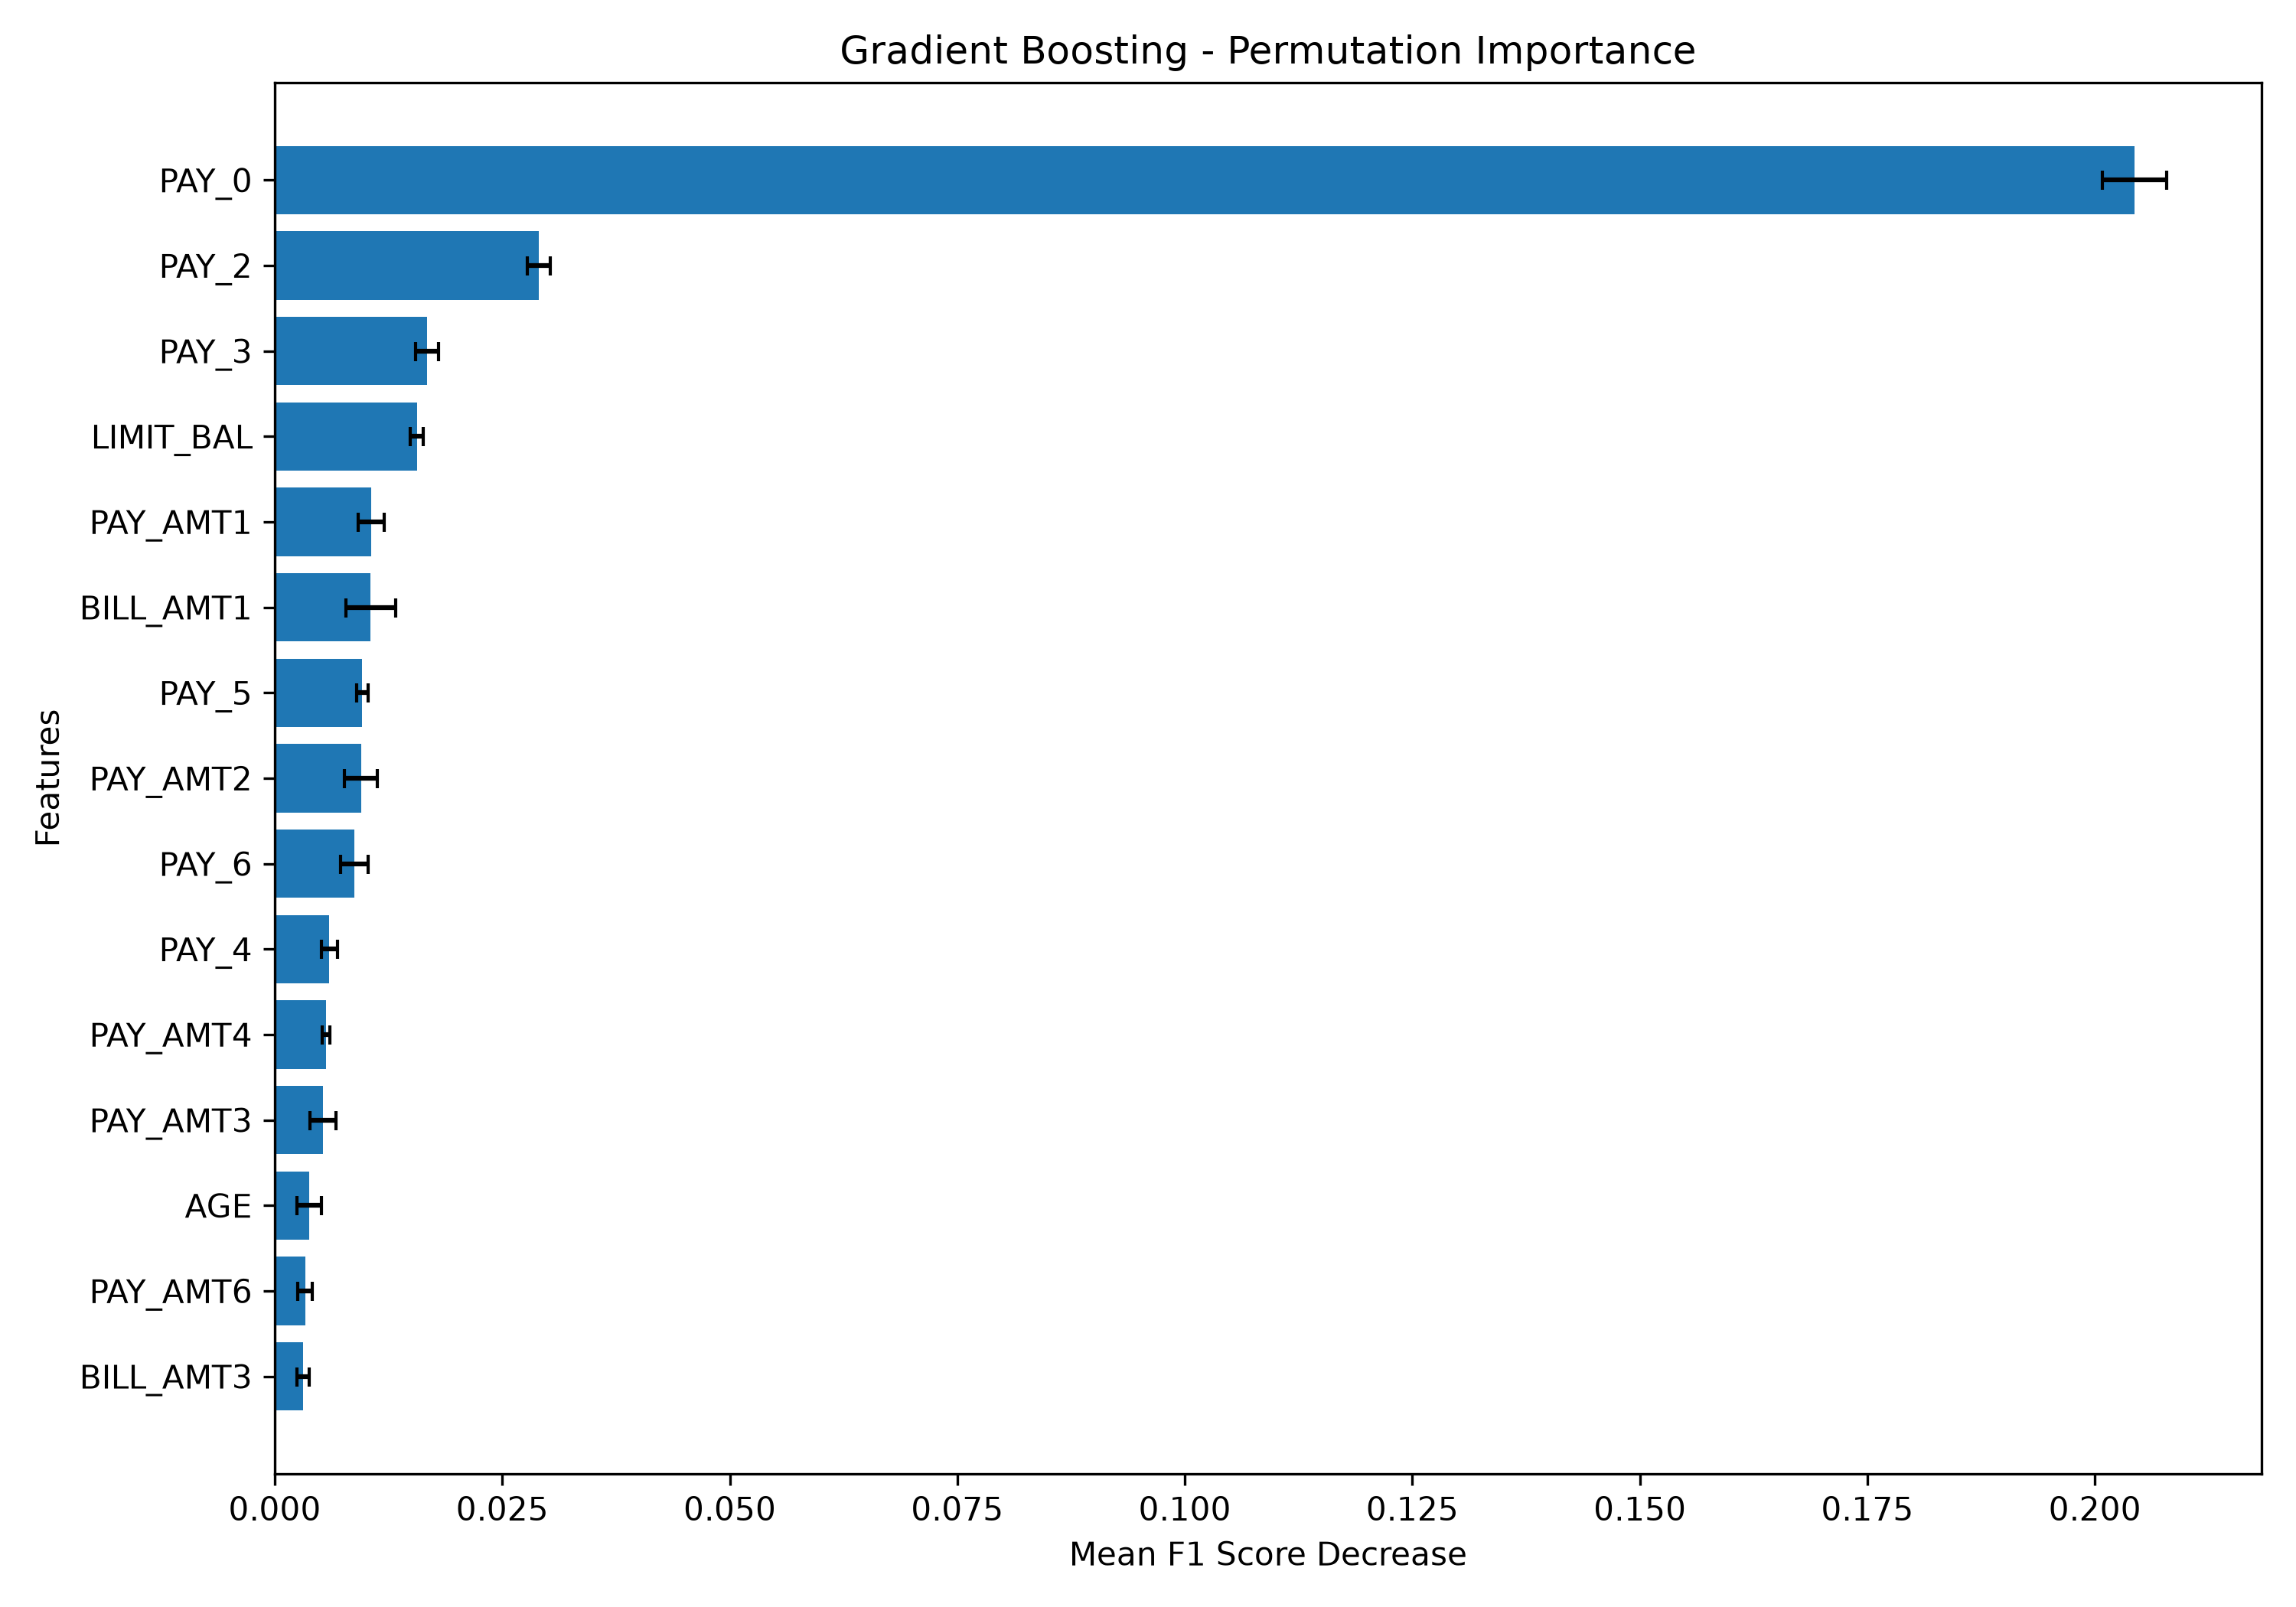

In [ ]:
from IPython.display import Image, display
import pandas as pd
import os
from pathlib import Path

current = Path.cwd().resolve()
candidates = [current, *current.parents]
project_root = next(
    (p for p in candidates if (p / "src" / "preprocessing.py").is_file()),
    None
)
if project_root is None:
    raise FileNotFoundError("Cannot find project root. Make sure you are inside the repo.")
os.chdir(project_root)

print("=== 7.2.1 Permutation Importance ===")
perm_imp = pd.read_csv("results/gb_permutation_importance.csv")
display(perm_imp.head(15).style.format({'importance_mean': '{:.4f}', 'importance_std': '{:.4f}'}))

print("\n=== Figure 7.2.1: Permutation Importance ===")
display(Image(filename='figures/gb_permutation_importance.png'))

**Feature importance.** Figure 7.2.1 shows permutation importance for the Gradient Boosting model. PAY_0 dominates with a mean importance of 0.2067 ± 0.0027. It is followed by PAY_2 (0.0296), PAY_3 (0.0175), LIMIT_BAL (0.0169) and BILL_AMT1 (0.0158). The concentration on repayment-status variables matches credit-risk intuition. This is model dependence, not causation, because PAY_0 is recorded after the billing cycle.

=== 7.2.2 Error Analysis (FP/FN Decomposition) ===


,PAY_0_mean,LIMIT_BAL_median,PAY_AMT1_median
error_group,,,
FN,-0.40,140000.00,2002.00
FP,0.67,70000.00,390.00
TN,-0.40,170000.00,3000.00
TP,1.32,80000.00,1200.00



=== Figure 7.2.3: Error Decomposition ===


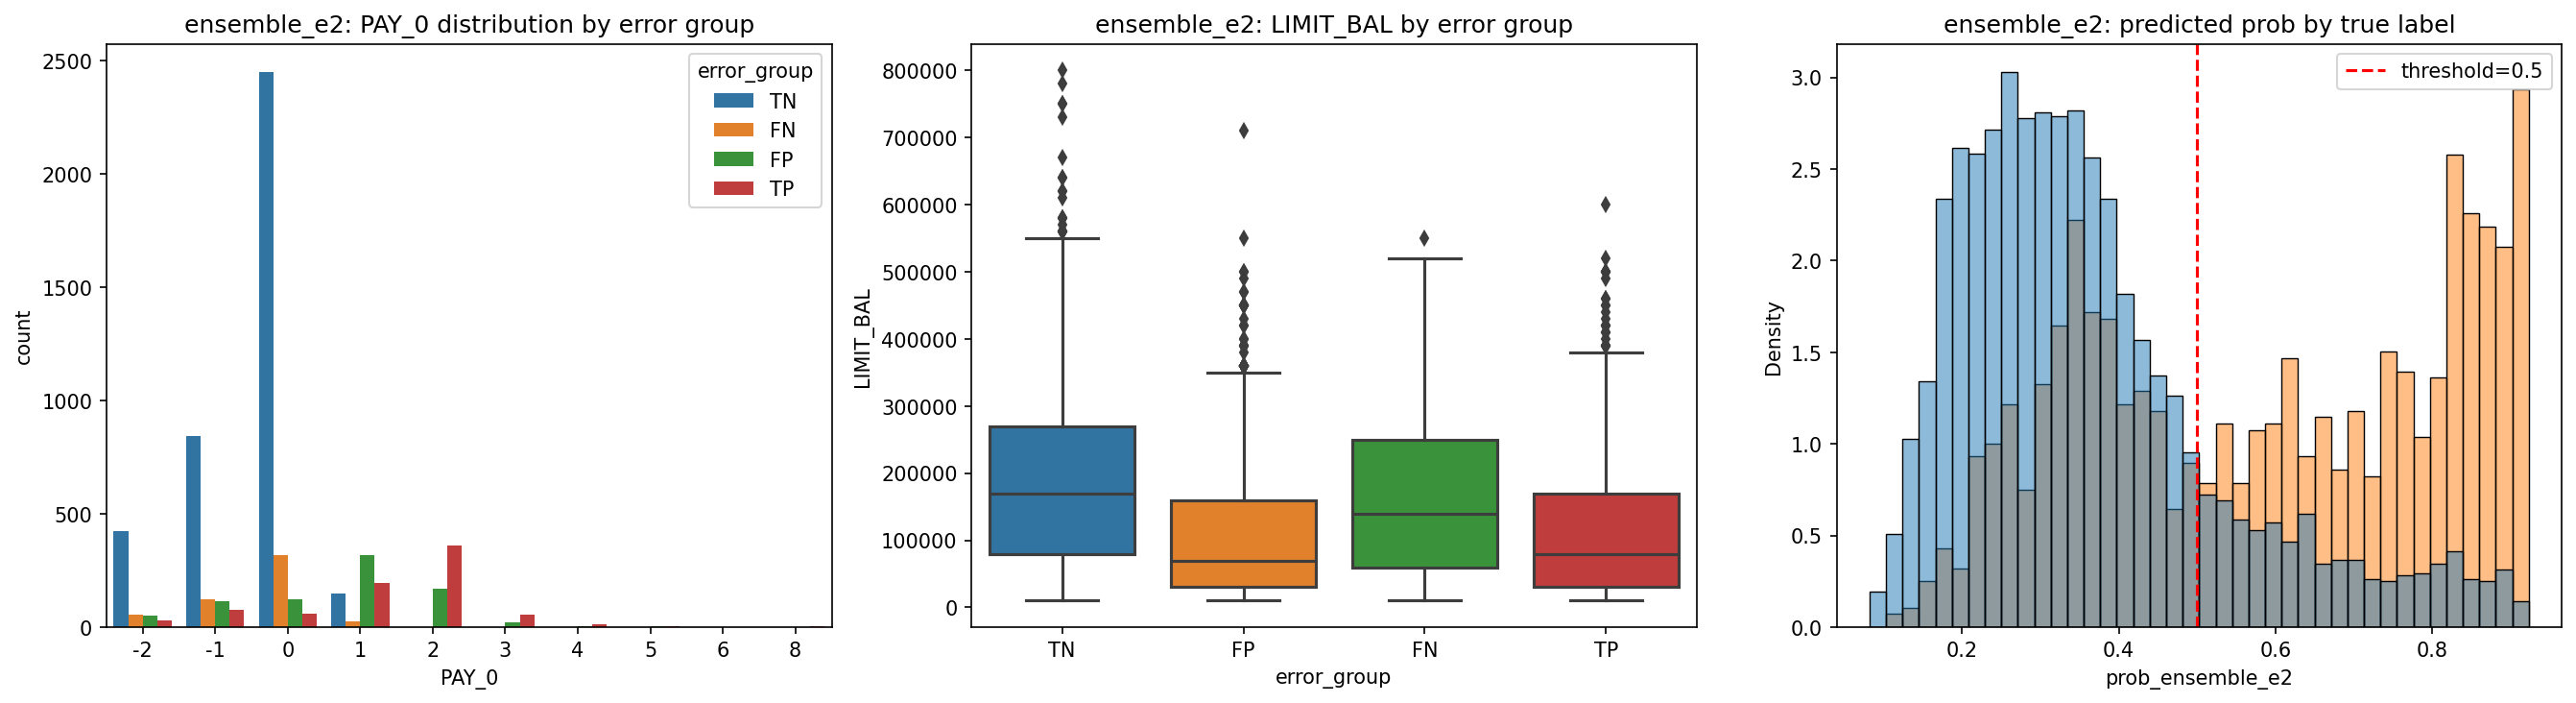

In [ ]:
print("=== 7.2.2 Error Analysis (FP/FN Decomposition) ===")
error_df = pd.read_csv("results/error_analysis.csv", header=[0,1], index_col=0)
error_df.columns = [f'{a}_{b}' for a,b in error_df.columns]
display(error_df[['PAY_0_mean', 'LIMIT_BAL_median', 'PAY_AMT1_median']].style.format('{:.2f}'))

print("\n=== Figure 7.2.3: Error Decomposition ===")
display(Image(filename='figures/error_analysis.png'))

**Error analysis.** The confusion matrix of the ensemble is TN = 3,866, FP = 807, FN = 526 and TP = 801. Figure 7.2.3 explains why these errors occur. In the left panel, false negatives look like true negatives on PAY_0, so they carry no obvious repayment signal. False positives cluster at PAY_0 = 1: they show a repayment delay but do not default. In the middle panel, the median LIMIT_BAL is highest for true negatives (about 170,000), lower for false negatives (about 140,000), and lowest for false positives and true positives (about 70,000–80,000). In the right panel, the two true-label distributions overlap between 0.3 and 0.6, which is why some defaulters fall below the 0.5 threshold and some non-defaulters rise above it.

### Business meaning
A missed default (FN) costs the principal. A false alarm (FP) costs the foregone interest and the customer relationship. The missed-default group is high-limit, so the loss per FN is larger than the loss per FP. This asymmetry motivates the recall-oriented recommendation below.

## 14. Final Recommendation, Limitations and Conclusion

In [ ]:
print("=== Table 7.3.1: Recommendation Matrix ===")
model_comp = pd.read_csv("results/final_model_comparison.csv")
keep = ['random_forest', 'gb_balanced', 'ensemble_e2', 'logistic_regression']
cols = ['model_key', 'test_f1', 'test_recall', 'predict_ms_total', 'artifact_size_kb']
rec_df = model_comp[model_comp.model_key.isin(keep)][cols].copy()
rec_df.columns = ['Model', 'Test F1', 'Test Recall', 'Predict (ms)', 'Size (KB)']
display(rec_df.style.format({'Test F1': '{:.4f}', 'Test Recall': '{:.4f}', 'Predict (ms)': '{:.1f}', 'Size (KB)': '{:,.1f}'}))

=== Table 7.3.1: Recommendation Matrix ===


,Model,Test F1,Test Recall,Predict (ms),Size (KB)
2,gb_balanced,0.5377,0.6285,15.0,43.7
3,logistic_regression,0.5208,0.5554,9.8,2.8
4,random_forest,0.5454,0.5953,188.9,"7,748.6"
5,ensemble_e2,0.5458,0.6036,198.7,"7,804.5"


**Recommendation.** Table 7.3.1 compares the four frozen models. The two-model ensemble (RF:GB 2:1) has the highest test F1 (0.5458). Its gain over the tuned Random Forest (0.5454) is only 0.0004. This is inside the CV noise, so the gain is not practically meaningful. The ensemble is therefore not recommended. Logistic Regression is also not recommended. Its recall is the lowest (0.5554).

Balanced Gradient Boosting is recommended for deployment. It has the highest recall of the four models (0.6285). This matters most because the error analysis shows that missed defaults are concentrated among high-limit customers with the largest loss given default. Its test F1 (0.5377) is statistically indistinguishable from RF. It scores 12× faster than RF (15 ms vs 189 ms per 6,000 rows). Its model file is 180× smaller (43.7 KB vs 7,748 KB). The tuned Random Forest is retained as a benchmarking alternative.

**Limitations.** The dataset is a 2005 Taiwanese bank cohort. Temporal and geographic drift therefore limit generalisation. Demographic features raise fairness concerns. Permutation importance is association, not causation. The decision threshold was fixed at 0.5, with no calibration or cost-sensitive tuning.

**Conclusion.** This study compared Logistic Regression, Random Forest, Gradient Boosting and a two-model soft-voting ensemble under one frozen protocol. The ensemble did not materially improve on the best single model. Balanced Gradient Boosting offers the best balance of recall, efficiency and deployability, and is the recommended solution.